<a href="https://colab.research.google.com/github/samer-glitch/TADP-Enhancing-Trustworthiness-in-Federated-Learning-Through-Provenance-Driven-Governance/blob/main/5_TADP_HPS28_Contribution_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
print(os.listdir('/content'))

['.config', 'Fashion_MNIST_HPS28_V5_Results.zip', 'TADP_HPS28_Adult_Phased_Results_v5.zip', 'sample_data']


In [4]:
#!/usr/bin/env python3
"""TADP HPS-28: audit the ACTUAL archived decision and round records.

This is a post-hoc diagnostic, NOT retraining. It does not authenticate evidence,
validate HPS against a real-world criterion, or change the original policy.

Usage:
  python TADP_HPS28_Contribution_Audit.py \
     --adult TADP_HPS28_Adult_Phased_Results_v5.zip \
     --fashion Fashion_MNIST_HPS28_V5_Results.zip \
     --out TADP_HPS28_Contribution_Audit

Outputs: policy_stage_audit.csv, counterfactual_policy_ablation.csv,
         aggregation_weight_audit.csv, paired_macro_f1.csv,\n         degradation_decision_transitions.csv, AUDIT_README.md.
"""
from __future__ import annotations
import argparse
import csv
import json
import re
import statistics
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

FACTORS = {
    'D1': ('source_reputation','data_controller','data_objective','data_collection_lineage'),
    'D2': ('completeness','duplication_rate','value_validity_error_rate','type_consistency',
           'label_integrity','feature_distribution_consistency','feature_category_coverage',
           'structural_constraint_integrity'),
    'D3': ('data_dictionary','version_logs','collection_protocol','definition_updates'),
    'D4': ('data_freshness','scheduled_refresh','retention_clarity'),
    'D5': ('regulation_coverage','consent_ethics','geo_restrictions','sensitivity_classification','audits'),
    'D6': ('license_terms','ethical_reviews','redistribution','user_agreements'),
}
WEIGHTS = {'D1':.25,'D2':.15,'D3':.10,'D4':.10,'D5':.30,'D6':.10}
DOC_FACTORS = set().union(*(set(f) for d,f in FACTORS.items() if d!='D2'))
D2_FACTORS = set(FACTORS['D2'])
ALL_FACTORS = DOC_FACTORS | D2_FACTORS
GOVERNED = ('HPG', 'PWA', 'WUPW')

def write_rows(path, rows):
    if not rows: raise ValueError('No results for '+str(path))
    keys=list(rows[0]);
    with open(path,'w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,keys);writer.writeheader();writer.writerows(rows)

def load_zip(path):
    z=zipfile.ZipFile(path)
    decision_paths=sorted(n for n in z.namelist() if '/decisions_' in n and n.endswith('_none.json'))
    round_paths=sorted(n for n in z.namelist() if '/rounds_' in n and n.endswith('_none.json'))
    result_paths=sorted(n for n in z.namelist() if '/results_' in n and n.endswith('_none.csv'))
    if len(decision_paths)!=20 or len(round_paths)!=20 or len(result_paths)!=20:
        raise ValueError(f'Expected exactly 20 unperturbed decision/round/result files; got '
                         f'{len(decision_paths)}/{len(round_paths)}/{len(result_paths)} in {path}')
    def key(name):
        alpha=re.search(r'alpha(0\.[0-9]+)',name)
        seed=re.search(r'_seed(4[2-6])_',name)
        if not alpha or not seed: raise ValueError('Unexpected path '+name)
        return (alpha.group(1), int(seed.group(1)), 'degraded' if '_degraded_none.' in name else 'clean')
    d={key(p):json.loads(z.read(p)) for p in decision_paths}
    r={key(p):json.loads(z.read(p)) for p in round_paths}
    v={key(p):list(csv.DictReader(z.read(p).decode('utf-8').splitlines())) for p in result_paths}
    if set(d)!=set(r) or set(d)!=set(v):raise ValueError('Decision/round/result condition mismatch')
    if any(len(x['decisions'])!=50 for x in d.values()):raise ValueError('Client count mismatch')
    return d,r,v

def policy_flags(d, policy):
    scores=d['factor_scores']; dims=d['dimensions']
    if set(scores)!=ALL_FACTORS or set(dims)!=set(FACTORS): raise ValueError('Factor mismatch')
    has_d2_zero=any(scores[f]==0 for f in D2_FACTORS)
    has_doc_zero=any(scores[f]==0 for f in DOC_FACTORS)
    zero=has_d2_zero or has_doc_zero
    floor=any(v<policy['min_dimension'] for v in dims.values())
    critical=any(scores[f]<limit for f,limit in policy.get('critical_factor_floors',{}).items())
    hps=sum(WEIGHTS[d]*dims[d] for d in FACTORS)
    review=sum(WEIGHTS[x]*dims[x] for x in ('D1','D2','D5','D6'))/.80
    if abs(hps-d['hps'])>1e-7 or abs(review-d['hps_review'])>1e-7:
        raise ValueError('Archived HPS and recomputed HPS differ')
    numerical=(hps>=policy['direct_accept_from'] or
               (hps>=policy['reject_below'] and
                review>=(policy['reject_below']+policy['direct_accept_from'])/2))
    all_pass=(not zero and not floor and not critical and numerical)
    if all_pass!=d['accepted']:
        raise ValueError(f'Archived decision differs from reconstructed decision: {d["path"]}')
    return {'zero':zero,'d2_zero':has_d2_zero,'documentary_zero':has_doc_zero,
            'floor':floor,'critical':critical,'numerical':numerical,'full':all_pass}

def sum_round(x):return sum(x)

def mean_sd(x):
    return (statistics.mean(x),statistics.stdev(x) if len(x)>1 else 0.0)

def audit(adult, fashion, out):
    out.mkdir(parents=True,exist_ok=True)
    stage_rows=[]; ablation_rows=[]; weight_rows=[]; predictive_rows=[]; transition_rows=[]
    combined=Counter()
    for dataset,zip_path in (('Adult',adult),('Fashion-MNIST',fashion)):
        decisions,rounds,results=load_zip(zip_path)
        for alpha in ('0.5','0.1'):
            for seed in (42,43,44,45,46):
                orig=decisions[(alpha,seed,'clean')]['decisions']
                altered=decisions[(alpha,seed,'degraded')]['decisions']
                for group, subset in (
                    ('targeted_for_degradation',[cid for cid in orig if altered[cid]['degraded']]),
                    ('not_targeted',[cid for cid in orig if not altered[cid]['degraded']]),
                ):
                    transition_rows.append({
                        'dataset':dataset,'alpha':alpha,'seed':seed,'group':group,
                        'n_clients':len(subset),
                        'admitted_clean':sum(orig[cid]['accepted'] for cid in subset),
                        'admitted_degraded':sum(altered[cid]['accepted'] for cid in subset),
                        'accepted_to_rejected':sum(orig[cid]['accepted'] and not altered[cid]['accepted'] for cid in subset),
                        'rejected_to_accepted':sum(not orig[cid]['accepted'] and altered[cid]['accepted'] for cid in subset),
                    })
        for (alpha,seed,condition),payload in sorted(decisions.items()):
            policy=payload['policy']
            flags={cid:policy_flags(decision,policy) for cid,decision in payload['decisions'].items()}
            paths=Counter(d['path'] for d in payload['decisions'].values())
            for cid, d in payload['decisions'].items():
                st=flags[cid]
                combined['assessments']+=1
                if d['accepted']:combined['accepted']+=1
                if d['path'] in ('BLOCKED_ZERO_FACTOR','BLOCKED_DIMENSION_FLOOR','BLOCKED_CRITICAL_FACTOR'):
                    combined['mandatory_rejected']+=1
                if not d['accepted'] and d['path'] in ('AUTO_REJECT','REVIEW_REJECT'):
                    combined['numerical_additional_rejected']+=1
                if not d['accepted'] and d['hps']>=policy['direct_accept_from']:
                    combined['rejected_high_score']+=1
                if st['d2_zero']: combined['cases_d2_zero']+=1
                if st['documentary_zero']:combined['cases_doc_zero']+=1
                if st['d2_zero'] and d['factor_scores']['feature_distribution_consistency']==0:
                    combined['cases_distribution_zero']+=1
            stage_rows.append({
                'dataset':dataset,'alpha':alpha,'seed':seed,'condition':condition,
                'clients':len(flags),'admitted':sum(x['full'] for x in flags.values()),
                'zero_stage_rejected':paths['BLOCKED_ZERO_FACTOR'],
                'dimension_stage_rejected':paths['BLOCKED_DIMENSION_FLOOR'],
                'other_mandatory_rejected':paths['BLOCKED_DISQUALIFIER']+paths['BLOCKED_CRITICAL_FACTOR'],
                'hps_below_rejection_threshold':paths['AUTO_REJECT'],
                'review_stage_rejected':paths['REVIEW_REJECT'],
                'review_stage_accepted':paths['REVIEW_ACCEPT'],
                'direct_accept':paths['AUTO_ACCEPT'],
                'd2_zero_cases_including_overlaps':sum(x['d2_zero'] for x in flags.values()),
                'doc_zero_cases_including_overlaps':sum(x['documentary_zero'] for x in flags.values()),
                'feature_distribution_consistency_zero':sum(d['factor_scores']['feature_distribution_consistency']==0
                      for d in payload['decisions'].values()),
                'rejected_despite_HPS_at_least_direct_accept':sum(not d['accepted'] and
                          d['hps']>=policy['direct_accept_from'] for d in payload['decisions'].values()),
                'degraded_clients':sum(d.get('degraded',False) for d in payload['decisions'].values()),
                'degraded_rejected':sum(d.get('degraded',False) and not d['accepted'] for d in payload['decisions'].values()),
                'nondegraded_rejected':sum(not d.get('degraded',False) and not d['accepted'] for d in payload['decisions'].values()),
            })
            definitions={
                'full_original':lambda x:x['full'],
                'mandatory_rules_only':lambda x:not (x['zero'] or x['floor'] or x['critical']),
                'zero_veto_only':lambda x:not x['zero'],
                'no_zero_veto':lambda x:not (x['floor'] or x['critical']) and x['numerical'],
                'no_dimension_floor':lambda x:not (x['zero'] or x['critical']) and x['numerical'],
                'numerical_HPS_only':lambda x:x['numerical'],
            }
            for name,fn in definitions.items():
                admitted={cid for cid,x in flags.items() if fn(x)}
                originally={cid for cid,x in flags.items() if x['full']}
                ablation_rows.append({
                    'dataset':dataset,'alpha':alpha,'seed':seed,'condition':condition,
                    'diagnostic_policy':name,'admitted':len(admitted),
                    'gained_vs_original':len(admitted-originally),
                    'lost_vs_original':len(originally-admitted),
                    'decision_changes_vs_original':len(admitted.symmetric_difference(originally)),
                    'note':'Counterfactual diagnostic only; not a recommended deployment policy'
                })
            by_method_round=defaultdict(dict)
            for row in rounds[(alpha,seed,condition)]:
                if row['method'] in GOVERNED:
                    by_method_round[row['round']][row['method']]=row
            for round_number,rows in sorted(by_method_round.items()):
                if set(rows)!=set(GOVERNED):raise ValueError('Missing HPG/PWA/WUPW rows')
                base=rows['HPG']
                ids=set(base['selected_ids']); expected=sum(float(w) for w in base['weights'].values())
                if abs(expected-1)>1e-8:raise ValueError('HPG weights do not sum to one')
                for name in ('PWA','WUPW'):
                    alternative=rows[name]
                    if ids!=set(alternative['selected_ids']):
                        raise ValueError('Cohort/selected IDs do not match in shared round')
                    if abs(sum(alternative['weights'].values())-1)>1e-8:
                        raise ValueError('Aggregated weights do not sum to one')
                    L1=sum(abs(base['weights'][cid]-alternative['weights'][cid]) for cid in ids)
                    hps=[payload['decisions'][cid]['hps'] for cid in ids]
                    weight_rows.append({
                        'dataset':dataset,'alpha':alpha,'seed':seed,'condition':condition,
                        'round':round_number,'comparison':f'{name}_vs_HPG',
                        'n_same_selected_clients':len(ids),
                        'total_variation_distance':round(L1/2,10),
                        'L1_weight_distance':round(L1,10),
                        'minimum_selected_HPS':round(min(hps),8),
                        'maximum_selected_HPS':round(max(hps),8),
                        'selected_HPS_spread':round(max(hps)-min(hps),8),
                        'same_selected_client_ids':True,
                        'same_admission_cohort':True,
                    })
            metrics={row['method']:row for row in results[(alpha,seed,condition)]}
            if set(GOVERNED)-set(metrics):raise ValueError('Missing governed method metrics')
            for name in ('PWA','WUPW'):
                predictive_rows.append({
                    'dataset':dataset,'alpha':alpha,'seed':seed,'condition':condition,
                    'comparison':f'{name}_minus_HPG',
                    'HPG_macro_f1':round(float(metrics['HPG']['macro_f1']),8),
                    'alternative_macro_f1':round(float(metrics[name]['macro_f1']),8),
                    'macro_f1_difference':round(float(metrics[name]['macro_f1'])-float(metrics['HPG']['macro_f1']),8),
                    'HPG_cohort_size':int(float(metrics['HPG']['cohort_size'])),
                    'alternative_cohort_size':int(float(metrics[name]['cohort_size'])),
                })
    write_rows(out/'policy_stage_audit.csv',stage_rows)
    write_rows(out/'counterfactual_policy_ablation.csv',ablation_rows)
    write_rows(out/'aggregation_weight_audit.csv',weight_rows)
    write_rows(out/'paired_macro_f1.csv',predictive_rows)
    write_rows(out/'degradation_decision_transitions.csv',transition_rows)
    by_compare=defaultdict(list)
    for r in weight_rows:by_compare[(r['dataset'],r['comparison'])].append(r['total_variation_distance'])
    all_mand=combined['mandatory_rejected']; total_rejected=combined['assessments']-combined['accepted']
    report=[
        '# TADP HPS-28 — contribution and policy audit',
        '',
        'These results are recomputed from archived decision, round and outcome records.',
        'No federated training is rerun. No independent provenance evidence is validated.',
        '',
        f'- Client assessments (repeated across experimental conditions): **{combined["assessments"]}**',
        f'- Admitted: **{combined["accepted"]}**; rejected: **{total_rejected}**',
        f'- Rejected at mandatory stages (zero factors / floors): **{all_mand} / {total_rejected}** '
        f'({100*all_mand/total_rejected:.2f}%)',
        f'- Additional numerical HPS / intermediate-review rejections: **{combined["numerical_additional_rejected"]}** '
        f'({100*combined["numerical_additional_rejected"]/combined["assessments"]:.3f}% of assessed cases)',
        f'- Rejected even though numerical HPS was >= 3.5: **{combined["rejected_high_score"]}** '
        '(mandatory safeguards take precedence)',
        f'- Cases with at least one D2 zero: **{combined["cases_d2_zero"]}**; '
        f'with at least one documentary zero: **{combined["cases_doc_zero"]}** '
        '(can overlap)',
        f'- Cases with zero for feature-distribution consistency: **{combined["cases_distribution_zero"]}**',
        '',
        '## Original-weight changes (same round participants in all comparisons)',
        '',
        '| Dataset | Pair | Mean total variation | Maximum total variation | Rounds |',
        '|---|---|---:|---:|---:|',
    ]
    for k,v in sorted(by_compare.items()):
        report.append(f'| {k[0]} | {k[1]} | {statistics.mean(v):.4f} | {max(v):.4f} | {len(v)} |')
    report += ['',
      'Total variation = 0.5 × L1 distance of normalized aggregation-weight vectors.',
      'It measures how much weights change, not model-performance improvement.',
      '', '## Interpretation and cautions', '',
      '1. The 28-factor numerical score governs score-adjusted aggregation even if only a few additional rejections arise at the numeric threshold/review stages.',
      '2. Because mandatory vetoes dominate admissions, numerical HPS admission value requires independent demonstration.',
      '3. The archived HPG, PWA and WUPW rounds used exactly the same selected client IDs; thus their comparative FL evaluation already controls cohort membership, although training trajectories diverge after applying different weights.',
      '4. Counterfactual policies are **diagnostic**. Relaxed safeguards may admit unsuitable clients and must not be presented as safer alternatives.',
      '5. Dataset-level corruption is injected synthetically; degraded status is not a real-world eligibility ground truth.',
      '6. Repeated conditions and seeds do not represent independent institutions or datasets.',
      '', '## Generated files', '',
      '- `policy_stage_audit.csv`: exact policy-stage paths and high-HPS rejection counts by seed and condition',
      '- `counterfactual_policy_ablation.csv`: rule ablations recomputed without retraining',
      '- `aggregation_weight_audit.csv`: matched per-round aggregation weights',
      '- `paired_macro_f1.csv`: within-seed PWA/WUPW vs HPG macro F1 differences',
      '', '### Provenance', '',
      f'- Adult archive: `{adult.name}`',
      f'- Fashion archive: `{fashion.name}`',
      '- Read-only ZIP input; code checks saved HPS computations and admission decisions against the original policy.',
    ]
    (out/'AUDIT_README.md').write_text('\n'.join(report)+'\n',encoding='utf-8')
    print('\n'.join(report[:31]))
    return out


# ============================================================================
# SIMPLE COLAB EXECUTION: upload this file + the two original results ZIPs.
# In a Colab cell: %run 01_Run_HPS_Contribution_Audit.py
# ============================================================================

def _run_one_click():
    from pathlib import Path
    import zipfile
    import os

    root = Path('/content') if Path('/content').is_dir() else Path.cwd()
    def find_zip(stem):
        candidates = sorted(root.glob(stem + '*.zip'))
        preferred = root / (stem + '.zip')
        if preferred.exists():
            return preferred
        if len(candidates) != 1:
            raise FileNotFoundError('Upload ' + stem + '.zip in the Colab Files panel; found: ' + str(candidates))
        return candidates[0]

    adult = find_zip('TADP_HPS28_Adult_Phased_Results_v5')
    fashion = find_zip('Fashion_MNIST_HPS28_V5_Results')
    result_dir = root/'STEP1_HPS_Contribution_Results'
    print('EXPERIMENT 1: HPS CONTRIBUTION AUDIT (no model training)')
    print('Using:', adult.name, 'and', fashion.name, flush=True)
    audit(adult, fashion, result_dir)
    bundle = root/'STEP1_HPS_Contribution_Results.zip'
    with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for entry in sorted(result_dir.rglob('*')):
            if entry.is_file():
                z.write(entry, entry.relative_to(result_dir.parent))
    print('SUCCESS. Download:', str(bundle), flush=True)
    print('In Colab, click the Files (folder) icon and download the ZIP.');
    return bundle

if __name__ == '__main__':
    _run_one_click()


EXPERIMENT 1: HPS CONTRIBUTION AUDIT (no model training)
Using: TADP_HPS28_Adult_Phased_Results_v5.zip and Fashion_MNIST_HPS28_V5_Results.zip
# TADP HPS-28 — contribution and policy audit

These results are recomputed from archived decision, round and outcome records.
No federated training is rerun. No independent provenance evidence is validated.

- Client assessments (repeated across experimental conditions): **2000**
- Admitted: **1164**; rejected: **836**
- Rejected at mandatory stages (zero factors / floors): **833 / 836** (99.64%)
- Additional numerical HPS / intermediate-review rejections: **3** (0.150% of assessed cases)
- Rejected even though numerical HPS was >= 3.5: **424** (mandatory safeguards take precedence)
- Cases with at least one D2 zero: **607**; with at least one documentary zero: **100** (can overlap)
- Cases with zero for feature-distribution consistency: **449**

## Original-weight changes (same round participants in all comparisons)

| Dataset | Pair | Mean tot

In [6]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data -O /content/adult.data

!wc -l /content/adult.data

32562 /content/adult.data


In [8]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""STEP 2: isolated Adult data-defect response, without FL retraining.

Uses the ORIGINAL 28-factor TADP policy and Adult D2 functions copied from the
November 10 benchmark source. Verifies the supplied Adult dataset/split against
existing archived decision fingerprints before any analysis. No TEST labels are
used for scoring or calibration. Runs missingness, duplication, invalid numeric
values, and within-class-set label flips SEPARATELY for original targeted clients.

Outputs are controlled synthetic-scenario sensitivity; they do NOT authenticate
legal provenance or prove admission accuracy. Full HPS documentary factors are
held fixed, and unmodified zero-factor rejections are reported distinctly.
"""
from __future__ import annotations
import argparse
import csv
import hashlib
import json
import math
from collections import defaultdict, Counter
from dataclasses import dataclass, field, asdict
from math import isfinite
from numbers import Real
from pathlib import Path
from types import SimpleNamespace
from typing import Mapping, Any
from zipfile import ZipFile
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

POLICY_VERSION = "TADP-HPS-28/1.0"
FACTORS = {
 "D1": ("source_reputation", "data_controller", "data_objective", "data_collection_lineage"),
 "D2": ("completeness", "duplication_rate", "value_validity_error_rate", "type_consistency",
        "label_integrity", "feature_distribution_consistency", "feature_category_coverage",
        "structural_constraint_integrity"),
 "D3": ("data_dictionary", "version_logs", "collection_protocol", "definition_updates"),
 "D4": ("data_freshness", "scheduled_refresh", "retention_clarity"),
 "D5": ("regulation_coverage", "consent_ethics", "geo_restrictions", "sensitivity_classification", "audits"),
 "D6": ("license_terms", "ethical_reviews", "redistribution", "user_agreements"),
}
WEIGHTS = {"D1": .25, "D2": .15, "D3": .10, "D4": .10, "D5": .30, "D6": .10}
CRITICAL = ("D1", "D2", "D5", "D6")
ALL_FACTORS = frozenset(f for fs in FACTORS.values() for f in fs)
D2_FACTORS = FACTORS["D2"]
_VIOLATION_CUTS = {
 "completeness": (.50, .20, .10, .05, .01),
 "duplication_rate": (.20, .10, .05, .02, .01),
 "value_validity_error_rate": (.15, .10, .05, .02, .01),
 "type_consistency": (.20, .10, .05, .02, .01),
 "label_integrity": (.10, .05, .02, .01, .001),
 "feature_distribution_consistency": (.20, .10, .05, .025, .01),
 "structural_constraint_integrity": (.10, .05, .02, .01, .001),
}
ADULT_COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
ADULT_NUMERIC = ("age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week")
NUMERIC_RANGES = {"age": (1, 120), "fnlwgt": (1, 1e10), "education-num": (1, 16),
 "capital-gain": (0, 1e9), "capital-loss": (0, 1e9), "hours-per-week": (0, 168)}


# SOURCE-ALIGNED FUNCTION: Policy
@dataclass(frozen=True)
class Policy:
    min_dimension: float = 2.5
    reject_below: float = 3.0
    direct_accept_from: float = 3.5
    # Explicit individual critical-factor safeguards, if legally/operationally justified.
    critical_factor_floors: Mapping[str, int] = field(default_factory=dict)
    policy_version: str = POLICY_VERSION

    @property
    def review_midpoint(self):
        return (self.reject_below + self.direct_accept_from) / 2.0

    def validate(self):
        bounds = (self.min_dimension, self.reject_below, self.direct_accept_from)
        if not all(isfinite(v) and 0 <= v <= 5 for v in bounds):
            raise ValueError("Invalid policy thresholds")
        if not (self.min_dimension <= self.reject_below < self.direct_accept_from):
            raise ValueError("Require minimum dimension <= reject threshold < accept threshold")
        for f, threshold in self.critical_factor_floors.items():
            if f not in ALL_FACTORS or type(threshold) is not int or not 0 <= threshold <= 5:
                raise ValueError(f"Invalid critical-factor floor: {f}")

# SOURCE-ALIGNED FUNCTION: Decision
@dataclass(frozen=True)
class Decision:
    accepted: bool
    path: str
    hps: float | None
    hps_review: float | None
    dimensions: dict[str, float]
    reasons: tuple[str, ...]
    factor_scores: dict[str, int]
    policy_version: str

    def record(self) -> dict:
        return asdict(self)

# SOURCE-ALIGNED FUNCTION: evaluate
def evaluate(scores: Mapping[str, int], policy: Policy = Policy(),
             disqualifiers: tuple[str, ...] = (),
             ablate_distribution: bool = False) -> Decision:
    policy.validate()
    missing = sorted(ALL_FACTORS - scores.keys())
    unknown = sorted(scores.keys() - ALL_FACTORS)
    if missing or unknown:
        return Decision(False, "BLOCKED_INCOMPLETE", None, None, {},
                        (f"Missing={missing}, unexpected={unknown}",), dict(scores), policy.policy_version)
    for factor, value in scores.items():
        if type(value) is not int or not 0 <= value <= 5:
            return Decision(False, "BLOCKED_INVALID", None, None, {},
                            (f"Invalid rubric score: {factor}={value!r}",), dict(scores), policy.policy_version)
    factor_groups = dict(FACTORS)
    if ablate_distribution:
        factor_groups["D2"] = tuple(f for f in FACTORS["D2"]
                                     if f not in ("feature_distribution_consistency","feature_category_coverage"))
    dimensions = {d: sum(scores[f] for f in fs)/len(fs) for d, fs in factor_groups.items()}
    hps = sum(WEIGHTS[d]*dimensions[d] for d in FACTORS)
    den = sum(WEIGHTS[d] for d in CRITICAL)
    hps_review = sum(WEIGHTS[d]*dimensions[d] for d in CRITICAL)/den
    def out(accepted, path, *reason):
        version = policy.policy_version + ("/NoDistributionAblation" if ablate_distribution else "")
        return Decision(accepted, path, round(hps, 10), round(hps_review, 10),
                        dimensions, tuple(reason), dict(scores), version)
    if disqualifiers:
        return out(False, "BLOCKED_DISQUALIFIER", *disqualifiers)
    active = set(f for fs in factor_groups.values() for f in fs)
    zeros = sorted(f for f, v in scores.items() if f in active and v == 0)
    if zeros:
        return out(False, "BLOCKED_ZERO_FACTOR", f"Required factor(s) scored zero: {zeros}")
    low = [f"{d}={v:.3f} < {policy.min_dimension}" for d, v in dimensions.items()
           if v < policy.min_dimension]
    if low:
        return out(False, "BLOCKED_DIMENSION_FLOOR", *low)
    for f, floor in policy.critical_factor_floors.items():
        if scores[f] < floor:
            return out(False, "BLOCKED_CRITICAL_FACTOR", f"{f}={scores[f]} < {floor}")
    if hps < policy.reject_below:
        return out(False, "AUTO_REJECT", f"HPS={hps:.4f} < {policy.reject_below}")
    if hps >= policy.direct_accept_from:
        return out(True, "AUTO_ACCEPT", f"HPS={hps:.4f} >= {policy.direct_accept_from}")
    if hps_review >= policy.review_midpoint:
        return out(True, "REVIEW_ACCEPT", f"HPS_review={hps_review:.4f} >= {policy.review_midpoint}")
    return out(False, "REVIEW_REJECT", f"HPS_review={hps_review:.4f} < {policy.review_midpoint}")

# SOURCE-ALIGNED FUNCTION: _ks_max
def _ks_max(a, b, seed=1, cap=10000):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a).reshape(-1), np.asarray(b).reshape(-1)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if not len(a) or not len(b): return 1.0
    if len(a) > cap: a = rng.choice(a, cap, replace=False)
    if len(b) > cap: b = rng.choice(b, cap, replace=False)
    return float(ks_2samp(a, b).statistic)

# SOURCE-ALIGNED FUNCTION: adult_train_metrics
def adult_train_metrics(client_x: pd.DataFrame, labels, reference_x: pd.DataFrame):
    if client_x.empty: raise ValueError("No client training records")
    if not set(ADULT_NUMERIC) <= set(client_x.columns): raise ValueError("Adult schema mismatch")
    if set(client_x.columns) != set(reference_x.columns): raise ValueError("Reference schema mismatch")
    x = client_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    ref = reference_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    numeric, categorical = list(ADULT_NUMERIC), [c for c in x.columns if c not in ADULT_NUMERIC]
    n, c = x.shape
    completeness = float(x.isna().to_numpy().mean())
    duplication = float(x.duplicated().mean())
    numeric_arr = x[numeric].apply(pd.to_numeric, errors="coerce")
    num_observed = x[numeric].notna().to_numpy()
    numeric_type_invalid = np.logical_and(num_observed, numeric_arr.isna().to_numpy()).sum()
    # Expected categorical fields are strings (allow object/string and reject unexpected list-like data).
    cat_type_bad = sum(sum(not isinstance(v, (str, np.str_)) for v in x[col].dropna()) for col in categorical)
    observed_count = int(x.notna().to_numpy().sum())
    type_inconsistency = (numeric_type_invalid + cat_type_bad) / max(observed_count, 1)
    num_invalid = np.zeros((n, len(numeric)), dtype=bool)
    bad_row = np.zeros(n, dtype=bool)
    for idx, field in enumerate(numeric):
        vals = numeric_arr[field].to_numpy(dtype=float)
        lo, hi = NUMERIC_RANGES[field]
        bad = np.isfinite(vals) & ((vals < lo) | (vals > hi))
        num_invalid[:, idx] = bad
        bad_row |= bad
    # Numeric type errors also count as invalid values, independently of completeness.
    validity = float((num_invalid.sum() + numeric_type_invalid) / max(observed_count, 1))
    structural = float(bad_row.mean())
    ys = np.asarray(labels)
    if len(ys) != n: raise ValueError("Label count mismatch")
    label_bad = float((~np.isin(ys, [0, 1])).mean())
    ks_vals = []
    for k, field in enumerate(numeric):
        r = pd.to_numeric(ref[field], errors="coerce").to_numpy(dtype=float)
        p = numeric_arr[field].to_numpy(dtype=float)
        ks_vals.append(_ks_max(p, r, seed=1337+k))
    consistency = max(ks_vals)
    coverage = []
    for field in categorical:
        ref_levels = set(ref[field].dropna().astype(str).str.strip().str.lower())
        present = set(x[field].dropna().astype(str).str.strip().str.lower())
        if ref_levels: coverage.append(len(ref_levels & present)/len(ref_levels))
    return dict(completeness=completeness, duplication_rate=duplication,
                value_validity_error_rate=min(1.,validity), type_consistency=min(1.,float(type_inconsistency)),
                label_integrity=label_bad, feature_distribution_consistency=float(consistency),
                feature_category_coverage=float(np.mean(coverage) if coverage else 1),
                structural_constraint_integrity=structural)

# SOURCE-ALIGNED FUNCTION: d2_from_metrics
def d2_from_metrics(metrics: Mapping[str, float]) -> dict[str, int]:
    if set(metrics) != set(D2_FACTORS):
        raise ValueError(f"Expected all eight D2 factors, missing={set(D2_FACTORS)-set(metrics)}")
    result = {}
    for name, value in metrics.items():
        if isinstance(value, bool) or not isinstance(value, Real) or not isfinite(value) or not 0 <= value <= 1:
            raise ValueError(f"Invalid TRAIN-only metric {name}={value!r}")
        if name == "feature_category_coverage":
            if value < .50: score = 0
            elif value < .65: score = 1
            elif value < .75: score = 2
            elif value < .825: score = 3
            elif value < .90: score = 4
            else: score = 5
        else:
            score = next((i for i, cut in enumerate(_VIOLATION_CUTS[name]) if value > cut), 5)
        result[name] = score
    return result

# SOURCE-ALIGNED FUNCTION: load_dataset
def load_dataset(dataset, adult_csv=None, fashion_root="./data", download=True):
    if dataset == "adult":
        if not adult_csv: raise ValueError("Provide --adult-csv path to Adult CSV (raw with missing values)")
        raw = pd.read_csv(adult_csv, skipinitialspace=True, na_values=["?", " ?", "", "nan"])
        if raw.shape[1] == 15 and str(raw.columns[0]).lower() != "age":
            # Headerless UCI adult.data file: preserve first data row.
            raw = pd.read_csv(adult_csv, header=None, skipinitialspace=True,
                              na_values=["?", " ?", "", "nan"])
        if raw.shape[1] != 15: raise ValueError("Adult CSV must have 15 columns")
        if list(raw.columns) != ADULT_COLUMNS:
            if ("income" in [str(c).lower() for c in raw.columns] or len(raw.columns)==15):
                raw.columns = ADULT_COLUMNS
        raw["income"] = raw["income"].astype(str).str.strip().str.lower().str.rstrip(".")
        raw = raw[raw["income"].isin(["<=50k", ">50k"])].copy()
        if raw.empty: raise ValueError("No recognized Adult binary income labels")
        y = (raw["income"] == ">50k").astype(np.int64).to_numpy()
        return raw.drop(columns="income").reset_index(drop=True), y
    try:
        from torchvision.datasets import FashionMNIST
    except Exception as exc:
        raise RuntimeError("torchvision is needed for Fashion-MNIST") from exc
    tr = FashionMNIST(root=fashion_root, train=True, download=download)
    te = FashionMNIST(root=fashion_root, train=False, download=download)
    return (tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy())

# SOURCE-ALIGNED FUNCTION: split_global
def split_global(dataset, loaded, cfg: Config, seed):
    """One immutable TRAIN/TEST division across ALL experimental seeds and methods.

    Adult has no patient identifier: claims of patient-grouped splitting are INVALID.
    Instead, identical raw predictor records are grouped to prevent exact
    duplicate predictors occurring in both TRAIN and TEST. Approximate 80/20,
    stratified as closely as possible under those grouping constraints.

    D2-only reference uses GLOBAL TRAIN predictors; it is never fitted as model
    preprocessing and is never used for gradient updates separately.
    """
    if dataset == "adult":
        from sklearn.model_selection import StratifiedGroupKFold
        x, y = loaded
        groups = pd.util.hash_pandas_object(x.fillna("__RAW_MISSING__").astype(str), index=False).to_numpy()
        splits = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg.global_split_seed)
        target_frac = cfg.test_fraction
        global_rate = float(np.mean(y))
        candidates = []
        for train_index, test_index in splits.split(x, y, groups):
            frac = len(test_index) / len(y)
            rate = float(np.mean(y[test_index]))
            candidates.append((abs(frac-target_frac)+abs(rate-global_rate), train_index, test_index))
        _, train_index, test_index = min(candidates, key=lambda z:z[0])
        if set(groups[train_index]) & set(groups[test_index]):
            raise AssertionError("LEAKAGE: identical raw predictor group occurs in TRAIN and TEST")
        xtrain = x.iloc[train_index].reset_index(drop=True)
        xtest = x.iloc[test_index].reset_index(drop=True)
        ytrain, ytest = np.asarray(y)[train_index], np.asarray(y)[test_index]
        assert len(xtrain)+len(xtest)==len(x)
        assert not (set(groups[train_index]) & set(groups[test_index]))
        return xtrain, ytrain, xtrain, xtest, ytest
    xtrain,ytrain,xtest,ytest = loaded
    return xtrain,np.asarray(ytrain),xtrain,xtest,np.asarray(ytest)

# SOURCE-ALIGNED FUNCTION: dirichlet_partition
def dirichlet_partition(y, n_clients, alpha, seed, min_samples=16, max_repair_fraction=.10,
                        return_diagnostics=False):
    """Seeded label-wise Dirichlet allocation plus EXPLICIT minimum-size repair.

    Rejection sampling with K=50, alpha=0.1 is rarely feasible. Instead sample
    the requested Dirichlet ONCE, then relocate the minimum records required
    from largest donors into undersized clients, preserving class labels.
    Because the repair changes the sampled allocation, report its count/rate;
    never describe the final partition as an unmodified Dirichlet draw.
    """
    rng=np.random.default_rng(seed)
    y=np.asarray(y)
    if alpha<=0 or len(y)<n_clients*min_samples:
        raise ValueError("Impossible partition: alpha<=0 or insufficient TRAIN records")
    bags=[[] for _ in range(n_clients)]
    for label in np.unique(y):
        indices=rng.permutation(np.flatnonzero(y==label))
        proportions=rng.dirichlet(np.full(n_clients, alpha))
        counts=rng.multinomial(len(indices), proportions)
        for i,part in enumerate(np.split(indices, np.cumsum(counts)[:-1])):
            bags[i].extend(part.tolist())
    pre_min=min(map(len,bags))
    moved=0
    for receiver in sorted(range(n_clients),key=lambda i:(len(bags[i]),i)):
        while len(bags[receiver]) < min_samples:
            donors=[j for j in range(n_clients) if len(bags[j])>min_samples]
            if not donors:raise ValueError("Partition quota infeasible; no donor clients")
            donor=max(donors,key=lambda j:(len(bags[j]),-j))
            j=int(rng.integers(len(bags[donor])))
            bags[receiver].append(bags[donor].pop(j));moved+=1
    assigned=np.concatenate([np.asarray(b,dtype=int) for b in bags])
    if len(assigned)!=len(y) or len(set(assigned.tolist()))!=len(y):
        raise AssertionError("Partition has dropped or duplicated TRAIN records")
    repair_fraction=moved/len(y)
    if repair_fraction>max_repair_fraction:
        raise ValueError(f"Partition repair {repair_fraction:.2%} > prespecified cap {max_repair_fraction:.2%}")
    diag={"alpha_requested":float(alpha),"seed":int(seed),"n_clients":n_clients,
          "min_client_size_before_repair":int(pre_min),"min_client_size_after_repair":int(min(map(len,bags))),
          "records_reallocated":int(moved),"repair_fraction":float(repair_fraction),
          "min_samples":int(min_samples),"distribution":"Dirichlet with logged minimum-client-size repair"}
    indices=[np.array(sorted(b),dtype=int) for b in bags]
    return (indices,diag) if return_diagnostics else indices

# SOURCE-ALIGNED FUNCTION: split_fingerprint
def split_fingerprint(xtr,ytr,xt,yt):
    """Bind cached results to the full, ordered TRAIN and held-out TEST data.

    TEST is hashed only for cache integrity; it is not used for D2, admission,
    loss weights, model selection, or fitting.
    """
    digest=hashlib.sha256()
    for tag,x,y in ((b'TRAIN',xtr,ytr),(b'TEST',xt,yt)):
        digest.update(tag)
        digest.update(np.asarray(pd.util.hash_pandas_object(x,index=False).to_numpy(),dtype=np.uint64).tobytes()
                      if isinstance(x,pd.DataFrame) else np.ascontiguousarray(x).tobytes())
        digest.update(np.ascontiguousarray(np.asarray(y,dtype=np.int64)).tobytes())
    return digest.hexdigest()


def apply_one_defect(x, y, scenario, seed):
    """Mirror the benchmark's Adult injection strength; ONE operation per case.

    Missingness uses replacement sampling as in the original Adult script.
    Duplicate selects 15% rows and copies their source records AND labels.
    Invalid targets 6% of rows in hours-per-week; labels flip 20%.
    """
    rng=np.random.default_rng(seed)
    z=x.copy(deep=True)
    labels=np.asarray(y).copy()
    n=len(labels)
    if scenario=='missing':
        count=max(1,int(n*len(z.columns)*0.12))
        rows=rng.integers(0,n,size=count)
        cols=rng.integers(0,len(z.columns),size=count)
        for row,col in zip(rows,cols):
            z.iat[int(row),int(col)] = np.nan
    elif scenario=='duplicate':
        if n>2:
            indices=rng.choice(n,max(1,int(n*0.15)),replace=False)
            sources=rng.choice(n,len(indices),replace=True)
            z.iloc[indices]=z.iloc[sources].to_numpy()
            labels[indices]=labels[sources]
    elif scenario=='invalid':
        ids=rng.choice(n,max(1,int(n*0.06)),replace=False)
        z.iloc[ids,z.columns.get_loc('hours-per-week')]=-999
    elif scenario=='label_flip':
        ids=rng.choice(n,max(1,int(n*0.20)),replace=False)
        labels[ids]=1-labels[ids]
    else:
        raise ValueError(scenario)
    return z, labels


def _save_csv(path, data):
    if not data: raise ValueError('No rows to save')
    with open(path,'w',newline='',encoding='utf-8') as f:
        writer=csv.DictWriter(f,fieldnames=list(data[0]));writer.writeheader();writer.writerows(data)


def _archive_cases(archive):
    decision_records={}
    with ZipFile(archive) as z:
        for path in z.namelist():
            if '/decisions_adult_seed' not in path or not path.endswith('_none.json'):
                continue
            obj=json.loads(z.read(path))
            if obj.get('dataset')!='adult': raise ValueError('Unexpected dataset')
            key=(float(obj['training_config']['alpha']),int(obj['seed']),
                 'degraded' if 'degraded' in path else 'clean')
            if key in decision_records: raise ValueError(f'Duplicate case {key}')
            decision_records[key]=obj
    expected={(a,seed,c) for a in (0.5,0.1) for seed in range(42,47) for c in ('clean','degraded')}
    if set(decision_records)!=expected:
        raise ValueError(f'Archive is missing cases {expected-set(decision_records)}')
    return decision_records


def run(archive, adult_data, output):
    out=Path(output);out.mkdir(parents=True,exist_ok=True)
    cases=_archive_cases(archive)
    cfg=SimpleNamespace(test_fraction=.20,global_split_seed=2026,min_client_samples=16,
                        max_partition_repair_fraction=.10)
    loaded=load_dataset('adult',adult_csv=str(adult_data))
    if len(loaded[1])!=32561:
        raise ValueError(f'Adult source has {len(loaded[1])} records, expected 32561. Supply original UCI adult.data.')
    xtr,ytr,ref,xt,yt=split_global('adult',loaded,cfg,42)
    fingerprint=split_fingerprint(xtr,ytr,xt,yt)
    fingerprints={d['global_train_test_sha256'] for d in cases.values()}
    if fingerprints!={fingerprint}:
        raise ValueError('Data/split fingerprint does NOT match archived benchmark. Do not mix results. '
                         f'Observed {fingerprint} vs archived {fingerprints}.')
    print('PASS: data and original TRAIN/TEST split fingerprints match the archive.',flush=True)
    ids=[f'C{i:03d}' for i in range(50)]
    rows=[]; controls=[]
    for alpha in (0.5,0.1):
        for seed in range(42,47):
            clean=cases[(alpha,seed,'clean')]
            degraded=cases[(alpha,seed,'degraded')]
            policy=Policy(**clean['policy'])
            client_ids=set(clean['decisions'])
            if client_ids!=set(ids):raise ValueError('Unexpected client IDs')
            if any(clean['decisions'][cid]['factor_scores'][f]!=degraded['decisions'][cid]['factor_scores'][f]
                   for cid in ids for f in ALL_FACTORS if f not in D2_FACTORS):
                raise ValueError('Documentary scoring changed unexpectedly across clean/degraded')
            idx,diag=dirichlet_partition(ytr,50,alpha,seed+31,min_samples=16,
                                        max_repair_fraction=.10,return_diagnostics=True)
            selected=set(degraded['degraded_ids'])
            expected=set(np.random.default_rng(seed+339).choice(ids,size=15,replace=False).tolist())
            if selected!=expected:raise ValueError('Original targeted client IDs did not reproduce')
            # Control group is all original clean clients; no remeasurement needed.
            for cid in ids:
                rec=clean['decisions'][cid]
                score=rec['factor_scores']
                controls.append(dict(alpha=alpha,seed=seed,client=cid,
                    targeted=int(cid in selected),original_admitted=int(rec['accepted']),
                    original_path=rec['path'],original_hps=rec['hps'],
                    original_D2=rec['dimensions']['D2'],
                    original_distribution_score=score['feature_distribution_consistency'],
                    original_distribution_zero=int(score['feature_distribution_consistency']==0),
                    original_any_D2_zero=int(any(score[f]==0 for f in D2_FACTORS))))
            for cid in sorted(selected):
                client_index=int(cid[1:])
                x=xtr.iloc[idx[client_index]].reset_index(drop=True)
                y=np.asarray(ytr)[idx[client_index]].copy()
                saved=clean['decisions'][cid]
                original_raw=adult_train_metrics(x,y,ref)
                for key in D2_FACTORS:
                    if not np.isclose(original_raw[key],saved['train_d2_raw_metrics'][key],atol=1e-9,rtol=0):
                        raise AssertionError(f'Mismatch in clean D2 raw metric for {alpha}/{seed}/{cid}/{key}: '
                                             f'{original_raw[key]} versus {saved["train_d2_raw_metrics"][key]}')
                baseline_scores=saved['factor_scores']
                if d2_from_metrics(original_raw)!={k:baseline_scores[k] for k in D2_FACTORS}:
                    raise AssertionError(f'Mismatch clean D2 score for {alpha}/{seed}/{cid}')
                policy_check=evaluate(baseline_scores,policy)
                if policy_check.accepted != saved['accepted']:
                    raise AssertionError('Original decision cannot be reproduced')
                for scenario in ('missing','duplicate','invalid','label_flip'):
                    # Deterministic independent random stream per scenario and client.
                    scenario_index=('missing','duplicate','invalid','label_flip').index(scenario)
                    defect_seed=seed*10007+client_index*17+scenario_index*100000
                    changed_x,changed_y=apply_one_defect(x,y,scenario,defect_seed)
                    raw=adult_train_metrics(changed_x,changed_y,ref)
                    scores=d2_from_metrics(raw)
                    full={**baseline_scores, **scores}
                    assessment=evaluate(full,policy)
                    changed_factors=[k for k in D2_FACTORS if scores[k]!=baseline_scores[k]]
                    worsened=[k for k in D2_FACTORS if scores[k]<baseline_scores[k]]
                    rows.append(dict(alpha=alpha,seed=seed,client=cid,scenario=scenario,
                        n_records=len(y),baseline_admitted=int(saved['accepted']),
                        scenario_admitted=int(assessment.accepted),
                        admitted_to_rejected=int(saved['accepted'] and not assessment.accepted),
                        rejected_to_admitted=int(not saved['accepted'] and assessment.accepted),
                        baseline_path=saved['path'],scenario_path=assessment.path,
                        baseline_hps=float(saved['hps']),scenario_hps=assessment.hps,
                        delta_hps=round(assessment.hps-float(saved['hps']),8),
                        baseline_D2=float(saved['dimensions']['D2']),scenario_D2=assessment.dimensions['D2'],
                        changed_D2_count=len(changed_factors),worsened_D2_count=len(worsened),
                        any_D2_worsened=int(bool(worsened)),
                        target_D2_zero=int(any(scores[f]==0 for f in D2_FACTORS)),
                        baseline_D2_zero=int(any(baseline_scores[f]==0 for f in D2_FACTORS)),
                        changed_factor_names=';'.join(changed_factors),
                        worsened_factor_names=';'.join(worsened),
                        baseline_distribution_score=baseline_scores['feature_distribution_consistency'],
                        scenario_distribution_score=scores['feature_distribution_consistency'],
                        baseline_label_integrity_score=baseline_scores['label_integrity'],
                        scenario_label_integrity_score=scores['label_integrity'],
                        raw_missing_before=round(original_raw['completeness'],6),
                        raw_missing_after=round(raw['completeness'],6),
                        raw_duplicate_before=round(original_raw['duplication_rate'],6),
                        raw_duplicate_after=round(raw['duplication_rate'],6),
                        raw_invalid_before=round(original_raw['value_validity_error_rate'],6),
                        raw_invalid_after=round(raw['value_validity_error_rate'],6)))
            print(f'Finished alpha={alpha}, seed={seed}: {len(selected)} original targeted clients.',flush=True)
    _save_csv(out/'B_client_level_defect_results.csv',rows)
    _save_csv(out/'B_clean_noniid_controls.csv',controls)
    summary=[]
    group=defaultdict(list)
    for row in rows:group[(row['alpha'],row['scenario'])].append(row)
    for (alpha,scenario),items in sorted(group.items()):
        total=len(items)
        eligible=sum(row['baseline_admitted'] for row in items)
        summary.append(dict(alpha=alpha,scenario=scenario,cases=total,
            initially_admitted=eligible,initially_rejected=total-eligible,
            any_D2_score_declined=sum(row['any_D2_worsened'] for row in items),
            score_decline_rate=round(sum(row['any_D2_worsened'] for row in items)/total,4),
            admitted_to_rejected=sum(row['admitted_to_rejected'] for row in items),
            initial_admitted_rejection_rate=round(sum(row['admitted_to_rejected'] for row in items)/eligible,4) if eligible else '',
            rejected_to_admitted=sum(row['rejected_to_admitted'] for row in items),
            mean_D2_change=round(float(np.mean([row['scenario_D2']-row['baseline_D2'] for row in items])),6),
            mean_HPS_change=round(float(np.mean([row['delta_hps'] for row in items])),6)))
    _save_csv(out/'B_summary_by_defect.csv',summary)
    controls_summary=[]
    for a in (.5,.1):
        arr=[row for row in controls if row['alpha']==a]
        zero=sum(row['original_any_D2_zero'] for row in arr)
        dist_zero=sum(row['original_distribution_zero'] for row in arr)
        controls_summary.append(dict(alpha=a,clean_client_assessments=len(arr),
            rejected_in_clean=sum(not row['original_admitted'] for row in arr),
            clean_any_D2_zero=zero,
            clean_distribution_score_zero=dist_zero,
            clean_D2_zero_rate=round(zero/len(arr),5),
            clean_distribution_zero_rate=round(dist_zero/len(arr),5)))
    _save_csv(out/'B_clean_noniid_summary.csv',controls_summary)
    report=[
        '# Step 2 — HPS single-defect data-quality assessment (Adult)', '',
        'Dataset and split fingerprints checked against the original Adult archive.',
        'Original documentary scores, admission policy, partitions, and global TRAIN reference retained.',
        'Fifteen originally targeted clients per alpha/seed; 4 separate defect scenarios each.',
        'Counts are correlated repeated virtual-client/seed assessments, NOT independent institutions.',
        'No model retraining, held-out TEST use for scoring, or real provenance verification.',
        '', '## Raw scenario counts', '',
        '| Alpha | Defect | Cases | D2 declines | Accepted→rejected | Rejected→accepted | Mean HPS change |',
        '|---|---|---:|---:|---:|---:|---:|']
    for r in summary:
        report.append(f'| {r["alpha"]} | {r["scenario"]} | {r["cases"]} | '
                      f'{r["any_D2_score_declined"]} | {r["admitted_to_rejected"]} | '
                      f'{r["rejected_to_admitted"]} | {r["mean_HPS_change"]:+.4f} |')
    report += ['', '## False-exclusion warning',
        'The clean cases are NOT independently labeled as legally eligible clients.',
        'Zero distribution-consistency scores among clean clients show possible non-IID exclusions,',
        'but are not validated false-positive rates without an independent suitability label.',
        '', '## Interpretation',
        '- Valid-class label flipping is deliberately not measurable by the current D2 label-integrity check.',
        '- Changes to the distribution-consistency factor can reflect legitimate heterogeneity as well as injected defects.',
        '- Combined original degradation is not analyzed here; each scenario modifies only one defect category.',
        '- Do not claim that these tests authenticate documentary evidence or legal compliance.',
        '- Do not choose HPS weights/thresholds by maximizing held-out TEST outcomes.']
    (out/'B_README.md').write_text('\n'.join(report)+'\n',encoding='utf-8')
    print('\n'.join(report[:19]))
    return out



# ============================================================================
# SIMPLE COLAB EXECUTION: upload this file, adult.data, and the Adult results ZIP.
# In a Colab cell: %run 02_Run_HPS_Individual_Defect_Tests.py
# ============================================================================

def _run_one_click():
    from pathlib import Path
    import zipfile

    root = Path('/content') if Path('/content').is_dir() else Path.cwd()
    adult_archive = root/'TADP_HPS28_Adult_Phased_Results_v5.zip'
    if not adult_archive.exists():
        matches=sorted(root.glob('TADP_HPS28_Adult_Phased_Results_v5*.zip'))
        if len(matches)!=1:
            raise FileNotFoundError('Upload TADP_HPS28_Adult_Phased_Results_v5.zip in the Colab Files panel.')
        adult_archive=matches[0]
    adult_data = root/'adult.data'
    if not adult_data.exists():
        candidates=[p for p in (root/'adult.csv',root/'adult_data.csv') if p.exists()]
        if len(candidates)!=1:
            raise FileNotFoundError('Upload the original UCI adult.data (32,561 records) in the Colab Files panel.')
        adult_data=candidates[0]
    result_dir = root/'STEP2_HPS_Defect_Results'
    print('EXPERIMENT 2: FOUR ISOLATED DATA-QUALITY DEFECTS (no model training)')
    print('Using:', adult_archive.name, 'and', adult_data.name, flush=True)
    run(adult_archive, adult_data, result_dir)
    bundle=root/'STEP2_HPS_Defect_Results.zip'
    with zipfile.ZipFile(bundle, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for entry in sorted(result_dir.rglob('*')):
            if entry.is_file():
                z.write(entry, entry.relative_to(result_dir.parent))
    print('SUCCESS. Download:', str(bundle), flush=True)
    print('In Colab, click the Files (folder) icon and download the ZIP.')
    return bundle

if __name__ == '__main__':
    _run_one_click()


EXPERIMENT 2: FOUR ISOLATED DATA-QUALITY DEFECTS (no model training)
Using: TADP_HPS28_Adult_Phased_Results_v5.zip and adult.data
PASS: data and original TRAIN/TEST split fingerprints match the archive.
Finished alpha=0.5, seed=42: 15 original targeted clients.
Finished alpha=0.5, seed=43: 15 original targeted clients.
Finished alpha=0.5, seed=44: 15 original targeted clients.
Finished alpha=0.5, seed=45: 15 original targeted clients.
Finished alpha=0.5, seed=46: 15 original targeted clients.
Finished alpha=0.1, seed=42: 15 original targeted clients.
Finished alpha=0.1, seed=43: 15 original targeted clients.
Finished alpha=0.1, seed=44: 15 original targeted clients.
Finished alpha=0.1, seed=45: 15 original targeted clients.
Finished alpha=0.1, seed=46: 15 original targeted clients.
# Step 2 — HPS single-defect data-quality assessment (Adult)

Dataset and split fingerprints checked against the original Adult archive.
Original documentary scores, admission policy, partitions, and global 

In [9]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""EXPERIMENT 3 — Distribution-factor hard-veto diagnostic (NO FL RETRAINING).

For each of the original 2,000 Adult/Fashion-MNIST client assessments,
reconstruct three admission-policy variants using the EXACT original scores,
HPS weights, thresholds and documentary profiles:
  A) original: all zero-valued factors are hard vetoes;
  B) distribution_soft: distribution-consistency score=0 does not hard-veto,
     but still counts in the original D2 mean and HPS;
  C) distribution_and_coverage_soft: both distribution-consistency and
     category-coverage score=0 remain in the score, not hard vetoes.

This is a COUNTERFACTUAL POLICY DIAGNOSTIC. It does NOT establish that
newly admitted clients are compliant or trustworthy. It does NOT claim
prediction accuracy or modify the existing benchmark results. Do not
choose policy variants using held-out TEST performance.

Google Colab: upload both original results ZIPs to /content and run
  %run /content/03_HPS_Distribution_Gate_Stress_Test.py
This will download STEP3_HPS_Distribution_Gate_Results.zip automatically.
"""
from __future__ import annotations
import argparse,csv,json,os,re,sys,zipfile
from collections import defaultdict,Counter
from pathlib import Path
from statistics import mean,stdev

WEIGHTS={"D1":.25,"D2":.15,"D3":.10,"D4":.10,"D5":.30,"D6":.10}
CRITICAL=("D1","D2","D5","D6")
DIST="feature_distribution_consistency"
COVER="feature_category_coverage"
VARIANTS={
    "original":set(),
    "distribution_soft":{DIST},
    "distribution_and_coverage_soft":{DIST,COVER},
}
INPUTS={
  "Adult":"TADP_HPS28_Adult_Phased_Results_v5.zip",
  "Fashion-MNIST":"Fashion_MNIST_HPS28_V5_Results.zip",
}

def locate(name, supplied=None):
    if supplied:
        p=Path(supplied)
        if not p.exists(): raise FileNotFoundError(f"File not found: {p}")
        return p
    matches=[]
    for folder in (Path.cwd(),Path('/content')):
        if folder.is_dir():
            matches.extend(p for p in folder.glob(name.removesuffix('.zip')+'*.zip') if p.is_file())
    matches=list(dict.fromkeys(p.resolve() for p in matches))
    direct=[p for p in matches if p.name==name]
    if len(direct)==1: return direct[0]
    if len(matches)==1: return matches[0]
    raise FileNotFoundError(f"Upload original result archive '{name}' to the Colab Files panel (found {len(matches)} matching files).")

def calculate(rec,policy,excluded_from_zero_veto):
    """Uses original stored dimensions and HPS; only changes veto semantics."""
    sc=rec['factor_scores']; dims=rec['dimensions']
    hps=sum(WEIGHTS[d]*dims[d] for d in WEIGHTS)
    review=sum(WEIGHTS[d]*dims[d] for d in CRITICAL)/sum(WEIGHTS[d] for d in CRITICAL)
    if abs(hps-rec['hps'])>1e-7 or abs(review-rec['hps_review'])>1e-7:
        raise AssertionError('HPS or review score differs from archived computation')
    zeros=[k for k,v in sc.items() if v==0 and k not in excluded_from_zero_veto]
    if zeros: return False,'BLOCKED_ZERO_FACTOR'
    if any(v<policy['min_dimension'] for v in dims.values()):return False,'BLOCKED_DIMENSION_FLOOR'
    if any(sc[k]<v for k,v in policy['critical_factor_floors'].items()): return False,'BLOCKED_CRITICAL_FACTOR'
    if hps<policy['reject_below']: return False,'AUTO_REJECT'
    if hps>=policy['direct_accept_from']: return True,'AUTO_ACCEPT'
    if review >=(policy['reject_below']+policy['direct_accept_from'])/2:return True,'REVIEW_ACCEPT'
    return False,'REVIEW_REJECT'

def read_zips(adult_path,fashion_path):
    cases={}
    for dataset,path in [('Adult',adult_path),('Fashion-MNIST',fashion_path)]:
        stem='adult' if dataset=='Adult' else 'fashion'
        pattern=re.compile(rf'/{stem}_alpha(0\.5|0\.1)/decisions_{stem}_seed(4[2-6])_(clean|degraded)_none\.json$')
        with zipfile.ZipFile(path) as z:
            for member in z.namelist():
                hit=pattern.search('/'+member.lstrip('/'))
                if not hit:continue
                key=(dataset,hit.group(1),int(hit.group(2)),hit.group(3))
                if key in cases:raise AssertionError(f'Duplicate {key}')
                cases[key]=json.loads(z.read(member))
    expected={(ds,alpha,seed,condition) for ds in INPUTS for alpha in ('0.5','0.1')
              for seed in range(42,47) for condition in ('clean','degraded')}
    if set(cases)!=expected:raise ValueError(f'Missing {sorted(expected-set(cases))}; extra {sorted(set(cases)-expected)}')
    for key,block in cases.items():
        if len(block['decisions'])!=50: raise ValueError(f'{key}: expected 50 client decisions')
        for cid,rec in block['decisions'].items():
            acc,path=calculate(rec,block['policy'],set())
            if bool(acc)!=bool(rec['accepted']) or path!=rec['path']:
                raise AssertionError(f'Original policy does not reproduce {key}/{cid}: {path} vs {rec["path"]}')
    return cases

def write_csv(p,records):
    if not records: raise ValueError('empty CSV')
    with open(p,'w',newline='',encoding='utf-8') as f:
        out=csv.DictWriter(f,fieldnames=list(records[0]));out.writeheader();out.writerows(records)

def run(adult_path,fashion_path,output):
    cases=read_zips(adult_path,fashion_path)
    output=Path(output);output.mkdir(parents=True,exist_ok=True)
    details=[];bycase={}
    for key,block in sorted(cases.items()):
        dataset,alpha,seed,condition=key
        for cid,rec in sorted(block['decisions'].items()):
            answers={v:calculate(rec,block['policy'],soft) for v,soft in VARIANTS.items()}
            if answers['original'][0]!=rec['accepted']:raise AssertionError('original mismatch')
            bycase[(dataset,alpha,seed,condition,cid)]=answers
            for variant,(accepted,path) in answers.items():
                details.append(dict(dataset=dataset,alpha=alpha,seed=seed,condition=condition,
                   client=cid,variant=variant,accepted=int(accepted),decision_path=path,
                   original_accepted=int(rec['accepted']),newly_admitted=int(accepted and not rec['accepted']),
                   newly_excluded=int(rec['accepted'] and not accepted),
                   targeted_for_degradation=int(rec.get('degraded',False)),
                   hps=round(rec['hps'],8),d2=round(rec['dimensions']['D2'],8),
                   distribution_factor_score=rec['factor_scores'][DIST],
                   coverage_factor_score=rec['factor_scores'][COVER],
                   other_factor_zero=int(any(val==0 for f,val in rec['factor_scores'].items() if f not in (DIST,COVER)))))
    if len(details)!=6000:raise AssertionError(len(details))
    write_csv(output/'step3_all_client_decisions.csv',details)
    summary=[]
    for ds in INPUTS:
      for alpha in ('0.5','0.1'):
       for condition in ('clean','degraded'):
        for variant in VARIANTS:
         subset=[r for r in details if r['dataset']==ds and r['alpha']==alpha and r['condition']==condition and r['variant']==variant]
         summary.append(dict(dataset=ds,alpha=alpha,condition=condition,variant=variant,
           assessments=len(subset),admitted=sum(r['accepted'] for r in subset),
           admitted_per_seed=round(sum(r['accepted'] for r in subset)/5,2),
           newly_admitted=sum(r['newly_admitted'] for r in subset),
           newly_excluded=sum(r['newly_excluded'] for r in subset),
           admitted_with_distribution_zero=sum(r['accepted'] and r['distribution_factor_score']==0 for r in subset),
           admitted_with_coverage_zero=sum(r['accepted'] and r['coverage_factor_score']==0 for r in subset),
           admitted_with_other_factor_zero=sum(r['accepted'] and r['other_factor_zero'] for r in subset),
           admitted_targeted_degraded=sum(r['accepted'] and r['targeted_for_degradation'] for r in subset)))
    write_csv(output/'step3_policy_summary.csv',summary)
    transitions=[]
    for ds in INPUTS:
      for alpha in ('0.5','0.1'):
       for variant in VARIANTS:
        for group in ('targeted','untargeted'):
         n=a2r=r2a=pass_clean=pass_degraded=0
         for seed in range(42,47):
          for cid,clean in cases[(ds,alpha,seed,'clean')]['decisions'].items():
           deg=cases[(ds,alpha,seed,'degraded')]['decisions'][cid]
           if ('targeted' if deg['degraded'] else 'untargeted')!=group:continue
           a=bycase[(ds,alpha,seed,'clean',cid)][variant][0]
           b=bycase[(ds,alpha,seed,'degraded',cid)][variant][0]
           n+=1;pass_clean+=a;pass_degraded+=b;a2r+=int(a and not b);r2a+=int(b and not a)
         transitions.append(dict(dataset=ds,alpha=alpha,variant=variant,group=group,
           paired_clients=n,admitted_clean=pass_clean,admitted_degraded=pass_degraded,
           accepted_to_rejected=a2r,rejected_to_accepted=r2a,
           accepted_to_rejected_rate_among_originally_accepted=round(a2r/pass_clean,5) if pass_clean else 'NA'))
    write_csv(output/'step3_clean_degraded_paired_transitions.csv',transitions)
    (output/'README.txt').write_text('EXPERIMENT 3: distribution zero-veto policy diagnostic\n'
       '2,000 archived client assessments across Adult and Fashion-MNIST, 5 seeds, both alphas, clean/degraded.\n'
       'ORIGINAL: any factor score of zero excludes client.\n'
       'DISTRIBUTION SOFT: a zero distribution-consistency factor is scored normally but does not automatically exclude.\n'
       'DISTRIBUTION+COVERAGE SOFT: both representativeness factors are scored but not zero-vetoed.\n'
       'The weighted HPS formula, dimension floor and score thresholds are UNCHANGED in all variants.\n'
       'All original archived decisions are reproduced exactly before analysis. No model training or TEST evaluation.\n'
       'Clean means no artificially injected defects, NOT independently verified governance eligibility.\n'
       'Targeted means selected for synthetic degradation, not necessarily verified unacceptable.\n'
       'This exercise is a diagnostic policy comparison, not a validated replacement policy or a superiority claim.\n',encoding='utf-8')
    zip_path=output.parent/(output.name+'.zip')
    with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for p in sorted(output.iterdir()): z.write(p,arcname=f'{output.name}/{p.name}')
    print('\nEXPERIMENT 3 COMPLETED. Reproduced 2,000 original admissions, checked 6,000 policy variants.')
    for r in summary:
        if r['condition']=='clean' and r['variant'] in ('original','distribution_soft'):
            print(f"{r['dataset']:14} alpha {r['alpha']} {r['variant']:19} clean admissions {r['admitted']:3}/250; +{r['newly_admitted']:3} vs original")
    print('\nResults:',zip_path)
    return zip_path

def main():
    parser=argparse.ArgumentParser()
    parser.add_argument('--adult',default=None)
    parser.add_argument('--fashion',default=None)
    parser.add_argument('--out',default=None)
    args,_=parser.parse_known_args()
    root=Path('/content') if Path('/content').exists() else Path.cwd()
    adult=locate(INPUTS['Adult'],args.adult)
    fashion=locate(INPUTS['Fashion-MNIST'],args.fashion)
    out=Path(args.out) if args.out else root/'STEP3_HPS_Distribution_Gate_Results'
    z=run(adult,fashion,out)
    if 'google.colab' in sys.modules:
        from google.colab import files
        files.download(str(z))

if __name__=='__main__': main()



EXPERIMENT 3 COMPLETED. Reproduced 2,000 original admissions, checked 6,000 policy variants.
Adult          alpha 0.5 original            clean admissions 151/250; +  0 vs original
Adult          alpha 0.5 distribution_soft   clean admissions 208/250; + 57 vs original
Adult          alpha 0.1 original            clean admissions  81/250; +  0 vs original
Adult          alpha 0.1 distribution_soft   clean admissions 192/250; +111 vs original
Fashion-MNIST  alpha 0.5 original            clean admissions 210/250; +  0 vs original
Fashion-MNIST  alpha 0.5 distribution_soft   clean admissions 210/250; +  0 vs original
Fashion-MNIST  alpha 0.1 original            clean admissions 210/250; +  0 vs original
Fashion-MNIST  alpha 0.1 distribution_soft   clean admissions 210/250; +  0 vs original

Results: /content/STEP3_HPS_Distribution_Gate_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


PHASE 1/5  |  EXPERIMENT OVERVIEW
Adult | 28-factor HPS | 5 paired seeds | same held-out TEST | transparent per-run outputs
Adult CSV missing at /content/adult.csv; downloading original UCI adult.data ...

PHASE 2/5  |  GLOBAL DATA ISOLATION
TRAIN/TEST split is fixed before clients, HPS or fitted preprocessing. Adult has no patient identifiers.
FIXED GLOBAL TRAIN/TEST SPLIT: {'global_split_seed': 2026, 'global_train_test_sha256': 'ce12db5389422aac36175923ae65d5a14635b9609070631d95383d3565916a0e', 'n_train': 26050, 'n_test': 6511, 'train_positive_rate': 0.23965451055662187, 'test_positive_rate': 0.2454308093994778, 'test_fraction_observed': 0.19996314609502167, 'grouping': 'exact raw predictor-vector groups; NOT patient-grouped', 'test_never_used_for_scoring_or_fit': True}

PHASE 3/5  |  PRETRAINING GOVERNANCE ADMISSION PREFLIGHT
No quota is imposed on HPS acceptance; the round budget is adapted AFTER admission.
  PREFLIGHT  alpha=0.5 seed=42    CLEAN | HPS accepted=32/50 | training sl

,alpha,seed,degraded,clients_total,accepted,rejected,trainers_per_round,hps_training_possible,effective_trainers_per_round,krum_feasible_at_adapted_round_size,...,degraded_clients,admitted_degraded_clients,degraded_targets_accepted_when_clean,degraded_targets_accepted_when_corrupted,degraded_targets_accept_to_reject,degraded_targets_reject_to_accept,mean_hps_change_in_targeted_clients,decision_paths,partition_reallocated,partition_repair_fraction
0,0.5,42,False,50,32,18,10,True,10,True,...,0,0,8,6,3,1,-0.14125,"{""AUTO_ACCEPT"": 30, ""BLOCKED_DIMENSION_FLOOR"":...",2,0.000077
1,0.5,42,True,50,30,20,10,True,10,True,...,15,6,8,6,3,1,-0.14125,"{""AUTO_ACCEPT"": 29, ""BLOCKED_DIMENSION_FLOOR"":...",2,0.000077
2,0.5,43,False,50,30,20,10,True,10,True,...,0,0,10,10,0,0,-0.13125,"{""AUTO_ACCEPT"": 27, ""BLOCKED_DIMENSION_FLOOR"":...",8,0.000307
3,0.5,43,True,50,30,20,10,True,10,True,...,15,10,10,10,0,0,-0.13125,"{""AUTO_ACCEPT"": 27, ""BLOCKED_DIMENSION_FLOOR"":...",8,0.000307
4,0.5,44,False,50,30,20,10,True,10,True,...,0,0,12,10,2,0,-0.13750,"{""AUTO_ACCEPT"": 28, ""BLOCKED_DIMENSION_FLOOR"":...",23,0.000883
5,0.5,44,True,50,28,22,10,True,10,True,...,15,10,12,10,2,0,-0.13750,"{""AUTO_ACCEPT"": 25, ""BLOCKED_DIMENSION_FLOOR"":...",23,0.000883
6,0.5,45,False,50,29,21,10,True,10,True,...,0,0,10,10,0,0,-0.13500,"{""AUTO_ACCEPT"": 28, ""BLOCKED_DIMENSION_FLOOR"":...",13,0.000499
7,0.5,45,True,50,29,21,10,True,10,True,...,15,10,10,10,0,0,-0.13500,"{""AUTO_ACCEPT"": 27, ""BLOCKED_DIMENSION_FLOOR"":...",13,0.000499
8,0.5,46,False,50,30,20,10,True,10,True,...,0,0,8,8,0,0,-0.13500,"{""AUTO_ACCEPT"": 27, ""BLOCKED_DIMENSION_FLOOR"":...",2,0.000077
9,0.5,46,True,50,30,20,10,True,10,True,...,15,8,8,8,0,0,-0.13500,"{""AUTO_ACCEPT"": 26, ""BLOCKED_DIMENSION_FLOOR"":...",2,0.000077


FULL STUDY: 5 seeds, 50 clients, 25 rounds, 10 trainers/round, 20 steps/client/round, 13 methods. Large compute requirement.

PHASE 4/5  |  CORE FEDERATED LEARNING
One run = (alpha, seed, clean/degraded). Each run prints methods, rounds, and a utility table.

--------------------------------------------------------------------------------------------
RUN 01/20  |  alpha=0.5  seed=42  condition=CLEAN  threat=none
TRAINING SCHEDULE | 25 rounds; max 10 clients/round; 20 steps/client
--------------------------------------------------------------------------------------------
    GOVERNANCE: ACCEPT=32/50  REJECT=18  SCHEDULE: target=10, effective=10 (matched FL possible)
  Governance approved : 32 (0..50; NO admission quota)
  Nominal per round    : 10
  Effective per round  : 10 for matched methods
  Planned matched steps: 25 rounds x 10 clients x 20 steps = 5000
  Batch size           : 64; mini-batch sampling WITH replacement
  FedAvg_all           : 25 x 50 x 20 = 25000 (UNMATCHED)
  Po

,method,accuracy,macro_f1,balanced_accuracy,auc,pr_auc_average_precision,positive_recall,runtime_seconds,estimated_energy_kwh,estimated_co2_kg,upload_MB_payload,cohort_size,training_clients_per_round,total_optimizer_steps,budget_matched_to_hps
0,D2_only,0.84749,0.78451,0.77248,0.90140,0.76394,0.62516,18.80053,0.00052,0.00021,110.593,40,10,5000,True
1,FedAvg_all,0.84411,0.79049,0.79178,0.90499,0.77063,0.68899,98.76353,0.00274,0.00110,552.965,50,50,25000,False
2,FedAvg_matched,0.83643,0.72930,0.69675,0.90043,0.76210,0.42240,27.38628,0.00076,0.00030,110.593,50,10,5000,True
3,FedProx,0.84119,0.74249,0.71004,0.90612,0.77151,0.45244,26.86427,0.00075,0.00030,110.593,50,10,5000,True
4,HPG,0.81216,0.77718,0.82402,0.90652,0.77242,0.84731,19.26231,0.00054,0.00021,110.593,32,10,5000,True
5,Krum,0.71617,0.69786,0.79757,0.90739,0.77117,0.95745,19.73540,0.00055,0.00022,110.593,50,10,5000,True
6,Median,0.82937,0.78969,0.82106,0.90667,0.77291,0.80476,20.77525,0.00058,0.00023,110.593,50,10,5000,True
7,NoDist_HPG,0.84319,0.78782,0.78715,0.90292,0.76677,0.67710,19.81484,0.00055,0.00022,110.593,42,10,5000,True
8,NoDist_PWA,0.84273,0.79067,0.79487,0.90342,0.76742,0.70088,18.68723,0.00052,0.00021,110.593,42,10,5000,True
9,PWA,0.81247,0.77663,0.82148,0.90642,0.77250,0.83917,19.20562,0.00053,0.00021,110.593,32,10,5000,True



PERFORMANCE + UTILITY (individual run, NOT mean ± SD): alpha=0.5 seed=42 degraded=False


,method,accuracy,macro_f1,balanced_accuracy,auc,pr_auc_average_precision,positive_recall,runtime_seconds,estimated_energy_kwh,estimated_co2_kg,upload_MB_payload,cohort_size,training_clients_per_round,total_optimizer_steps,mean_participant_hps,mean_aggregation_weighted_hps
0,D2_only,0.847489,0.784505,0.772481,0.901402,0.763938,0.625156,18.800533,0.000522,0.000209,110.593,40,10,5000,3.608469,3.525656
1,FedAvg_all,0.844110,0.790485,0.791776,0.904990,0.770631,0.688986,98.763525,0.002743,0.001097,552.965,50,50,25000,3.687025,3.439660
2,FedAvg_matched,0.836431,0.729300,0.696750,0.900432,0.762104,0.422403,27.386284,0.000761,0.000304,110.593,50,10,5000,3.687025,3.618882
3,FedProx,0.841192,0.742490,0.710039,0.906120,0.771509,0.452441,26.864274,0.000746,0.000298,110.593,50,10,5000,3.687025,3.618882
4,HPG,0.812164,0.777177,0.824021,0.906517,0.772417,0.847309,19.262311,0.000535,0.000214,110.593,32,10,5000,4.083047,4.082457
5,Krum,0.716173,0.697859,0.797571,0.907386,0.771169,0.957447,19.735404,0.000548,0.000219,110.593,50,10,5000,3.687025,3.984700
6,Median,0.829366,0.789690,0.821063,0.906672,0.772910,0.804756,20.775253,0.000577,0.000231,110.593,50,10,5000,3.687025,3.751827
7,NoDist_HPG,0.843188,0.787822,0.787154,0.902918,0.766769,0.677096,19.814843,0.000550,0.000220,110.593,42,10,5000,4.160893,4.218442
8,NoDist_PWA,0.842728,0.790667,0.794871,0.903419,0.767424,0.700876,18.687232,0.000519,0.000208,110.593,42,10,5000,4.160893,4.263149
9,PWA,0.812471,0.776634,0.821480,0.906416,0.772500,0.839174,19.205618,0.000533,0.000213,110.593,32,10,5000,4.083047,4.128919


... (138 outputs left out)

,dataset,alpha,degraded,threat,method,seeds,Accuracy,Macro F1,Balanced Accuracy,ROC-AUC,...,Positive Recall,Client cohort,Trained clients / round,Total optimizer steps,Time (s),Estimated energy (kWh),Estimated CO2 (kg),Average admitted HPS,Aggregation weighted HPS,Upload MB (payload)
0,adult,0.1,False,none,D2_only,5,0.7720 ± 0.0389,0.4985 ± 0.1530,0.5513 ± 0.1147,0.8699 ± 0.0268,...,0.1179 ± 0.2636,19.2000 ± 3.2711,10.0000 ± 0.0000,5000.0000 ± 0.0000,20.2137 ± 0.3635,0.0005615 ± 0.0000101,0.0002246 ± 0.0000040,3.6864 ± 0.2343,3.5230 ± 0.4764,110.5930 ± 0.0000
1,adult,0.1,False,none,FedAvg_all,5,0.7764 ± 0.0382,0.5150 ± 0.1452,0.5590 ± 0.1102,0.8888 ± 0.0126,...,0.1320 ± 0.2518,50.0000 ± 0.0000,50.0000 ± 0.0000,25000.0000 ± 0.0000,98.0643 ± 0.7822,0.0027240 ± 0.0000217,0.0010896 ± 0.0000087,3.6455 ± 0.0039,3.5470 ± 0.3359,552.9650 ± 0.0000
2,adult,0.1,False,none,FedAvg_matched,5,0.7297 ± 0.1364,0.5469 ± 0.1209,0.5969 ± 0.0902,0.8860 ± 0.0197,...,0.3359 ± 0.4089,50.0000 ± 0.0000,10.0000 ± 0.0000,5000.0000 ± 0.0000,20.1285 ± 0.8889,0.0005591 ± 0.0000247,0.0002236 ± 0.0000099,3.6455 ± 0.0039,3.5729 ± 0.3822,110.5930 ± 0.0000
3,adult,0.1,False,none,FedProx,5,0.7518 ± 0.1257,0.6194 ± 0.1513,0.6648 ± 0.1253,0.8959 ± 0.0084,...,0.4939 ± 0.4138,50.0000 ± 0.0000,10.0000 ± 0.0000,5000.0000 ± 0.0000,27.0015 ± 0.3143,0.0007500 ± 0.0000087,0.0003000 ± 0.0000035,3.6455 ± 0.0039,3.5729 ± 0.3822,110.5930 ± 0.0000
4,adult,0.1,False,none,HPG,5,0.7698 ± 0.0340,0.4881 ± 0.1298,0.5379 ± 0.0848,0.8553 ± 0.0294,...,0.0826 ± 0.1847,16.2000 ± 3.2711,10.0000 ± 0.0000,5000.0000 ± 0.0000,20.3533 ± 0.5176,0.0005654 ± 0.0000144,0.0002261 ± 0.0000058,4.0446 ± 0.0951,4.0226 ± 0.1528,110.5930 ± 0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,adult,0.5,True,none,RandomHPS,5,0.7646 ± 0.0945,0.7334 ± 0.0785,0.7956 ± 0.0382,0.9031 ± 0.0036,...,0.8564 ± 0.1092,29.4000 ± 0.8944,10.0000 ± 0.0000,5000.0000 ± 0.0000,19.4096 ± 0.5384,0.0005392 ± 0.0000150,0.0002157 ± 0.0000060,4.0126 ± 0.0855,4.0543 ± 0.1233,110.5930 ± 0.0000
66,adult,0.5,True,none,WUPW,5,0.8139 ± 0.0251,0.7592 ± 0.0336,0.7854 ± 0.0613,0.9015 ± 0.0035,...,0.7295 ± 0.2052,29.4000 ± 0.8944,10.0000 ± 0.0000,5000.0000 ± 0.0000,20.0111 ± 0.5888,0.0005559 ± 0.0000164,0.0002223 ± 0.0000065,4.0126 ± 0.0855,4.0476 ± 0.0833,110.5930 ± 0.0000
67,adult,0.5,True,stale,HPG,5,0.8268 ± 0.0089,0.7686 ± 0.0339,0.7841 ± 0.0602,0.9015 ± 0.0032,...,0.7001 ± 0.1844,29.0000 ± 1.2247,10.0000 ± 0.0000,5000.0000 ± 0.0000,19.9287 ± 0.6759,0.0005536 ± 0.0000188,0.0002214 ± 0.0000075,3.9905 ± 0.0794,3.9915 ± 0.0723,110.5930 ± 0.0000
68,adult,0.5,True,stale,PWA,5,0.8260 ± 0.0070,0.7674 ± 0.0340,0.7833 ± 0.0613,0.9017 ± 0.0033,...,0.6995 ± 0.1879,29.0000 ± 1.2247,10.0000 ± 0.0000,5000.0000 ± 0.0000,19.3870 ± 0.5979,0.0005385 ± 0.0000166,0.0002154 ± 0.0000066,3.9905 ± 0.0794,4.0343 ± 0.0740,110.5930 ± 0.0000


MAJORITY-ONLY COLLAPSE: 65/350 method trials; accuracy at/below majority-class baseline: 116/350.


,alpha,degraded,seed,method,accuracy,macro_f1,balanced_accuracy,positive_recall,pr_auc_average_precision
136,0.1,False,42,HPG,0.754569,0.43006,0.5,0.0,0.584289
137,0.1,False,42,PWA,0.754569,0.43006,0.5,0.0,0.587191
138,0.1,False,42,WUPW,0.754569,0.43006,0.5,0.0,0.587735
139,0.1,False,42,RandomHPS,0.754569,0.43006,0.5,0.0,0.506238
140,0.1,False,42,D2_only,0.754569,0.43006,0.5,0.0,0.603685
...,...,...,...,...,...,...,...,...,...
336,0.1,True,45,PWA,0.754569,0.43006,0.5,0.0,0.599622
337,0.1,True,45,WUPW,0.754569,0.43006,0.5,0.0,0.613033
338,0.1,True,45,HPG,0.754569,0.43006,0.5,0.0,0.623426
339,0.1,True,45,PWA,0.754569,0.43006,0.5,0.0,0.605653


Journal reporting: inspect summary.csv, journal_descriptive_table.csv, paired_vs_FedAvg_matched.csv and failures. No claims if complete 5-seed matched evidence is missing.


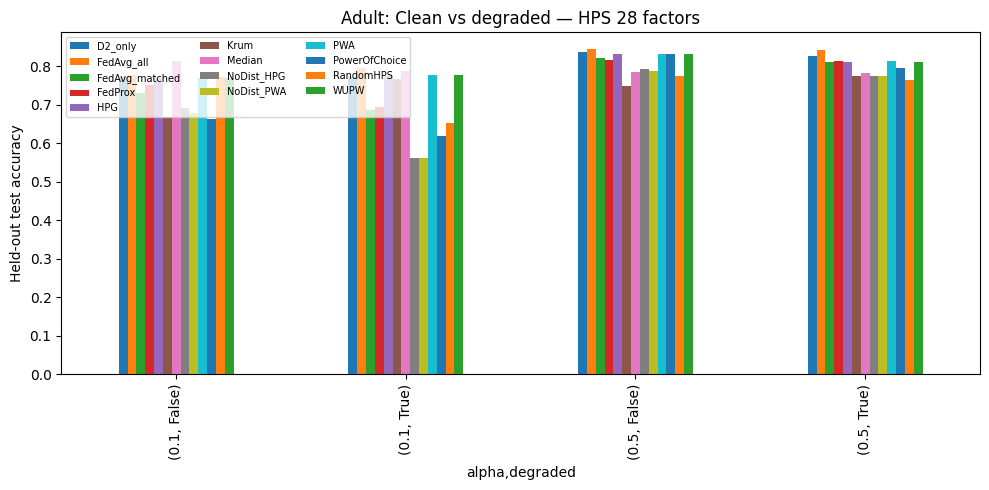

Study output directory: /content/TADP_HPS28_Adult_Phased_Results_v5
CHECK: use the held-out TEST only for final evaluation. Do not tune policy,
architecture, class weight, or training duration using these TEST outcomes.


In [11]:
# -*- coding: utf-8 -*-
from __future__ import annotations
"""1- Adult_HPS28.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/github/samer-glitch/TADP-Enhancing-Trustworthiness-in-Federated-Learning-Through-Provenance-Driven-Governance/blob/main/1-%20Adult_HPS28.ipynb
"""

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""SELF-CONTAINED COLAB SCRIPT: TADP-HPS-28 / phased multi-seed FL benchmark

Paste this entire file into a Google Colab code cell and run it. No other
TADP Python modules or ZIP extraction required. Requires standard scientific
Python libraries (NumPy, pandas, PyTorch, scikit-learn, SciPy, matplotlib).

Methodology: HPS D1-D6 (28 factors; 8 TRAIN-derived D2, 20 documentary
rubric factors). The 20 documentary levels are FROZEN SYNTHETIC PROFILES,
not actual human-verified records. The human evidence-checking step is not
automated by this script.

This is a RESEARCH-GRADE benchmark, not a production clinical/governance
service: reviewers are simulated, no cryptographic attestation, no external
ledger anchoring, no secure aggregation, and no networked FL deployment.
No seed or threshold may be tuned on held-out TEST. Adult lacks patient IDs:
its split uses exact-duplicate predictor grouping, not patient grouping.
The TRAIN-only governance distribution reference is never model preprocessing.
The pilot is intended to check execution, NOT to support publication claims.
Publication claims require complete matched-seed runs and independent review of results.
"""
from IPython.display import display
import matplotlib.pyplot as plt
from urllib.request import urlretrieve
import traceback
import platform
import sys



# ==============================================================================
# EMBEDDED MODULE: hps_policy.py
# ==============================================================================
"""TADP: 28-factor Hybrid Provenance Score (HPS) admission policy.

Documentary levels are HUMAN-ASSESSED in deployment; SIMULATED evidence
profiles in these experiments must not be presented as human verification.
"""
from dataclasses import dataclass, field, asdict
from math import isfinite
from numbers import Real
from typing import Mapping, Any

POLICY_VERSION = "TADP-HPS-28/1.0"
FACTORS = {
    "D1": ("source_reputation", "data_controller", "data_objective", "data_collection_lineage"),
    "D2": ("completeness", "duplication_rate", "value_validity_error_rate", "type_consistency",
           "label_integrity", "feature_distribution_consistency", "feature_category_coverage",
           "structural_constraint_integrity"),
    "D3": ("data_dictionary", "version_logs", "collection_protocol", "definition_updates"),
    "D4": ("data_freshness", "scheduled_refresh", "retention_clarity"),
    "D5": ("regulation_coverage", "consent_ethics", "geo_restrictions", "sensitivity_classification", "audits"),
    "D6": ("license_terms", "ethical_reviews", "redistribution", "user_agreements"),
}
WEIGHTS = {"D1": .25, "D2": .15, "D3": .10, "D4": .10, "D5": .30, "D6": .10}
CRITICAL = ("D1", "D2", "D5", "D6")
ALL_FACTORS = frozenset(f for dim in FACTORS.values() for f in dim)
DOC_FACTORS = frozenset(f for d, fs in FACTORS.items() if d != "D2" for f in fs)
D2_FACTORS = FACTORS["D2"]
assert len(ALL_FACTORS) == 28 and len(DOC_FACTORS) == 20 and len(D2_FACTORS) == 8
assert abs(sum(WEIGHTS.values()) - 1) < 1e-12

@dataclass(frozen=True)
class Policy:
    min_dimension: float = 2.5
    reject_below: float = 3.0
    direct_accept_from: float = 3.5
    # Explicit individual critical-factor safeguards, if legally/operationally justified.
    critical_factor_floors: Mapping[str, int] = field(default_factory=dict)
    policy_version: str = POLICY_VERSION

    @property
    def review_midpoint(self):
        return (self.reject_below + self.direct_accept_from) / 2.0

    def validate(self):
        bounds = (self.min_dimension, self.reject_below, self.direct_accept_from)
        if not all(isfinite(v) and 0 <= v <= 5 for v in bounds):
            raise ValueError("Invalid policy thresholds")
        if not (self.min_dimension <= self.reject_below < self.direct_accept_from):
            raise ValueError("Require minimum dimension <= reject threshold < accept threshold")
        for f, threshold in self.critical_factor_floors.items():
            if f not in ALL_FACTORS or type(threshold) is not int or not 0 <= threshold <= 5:
                raise ValueError(f"Invalid critical-factor floor: {f}")

@dataclass(frozen=True)
class Decision:
    accepted: bool
    path: str
    hps: float | None
    hps_review: float | None
    dimensions: dict[str, float]
    reasons: tuple[str, ...]
    factor_scores: dict[str, int]
    policy_version: str

    def record(self) -> dict:
        return asdict(self)


def evaluate(scores: Mapping[str, int], policy: Policy = Policy(),
             disqualifiers: tuple[str, ...] = (),
             ablate_distribution: bool = False) -> Decision:
    policy.validate()
    missing = sorted(ALL_FACTORS - scores.keys())
    unknown = sorted(scores.keys() - ALL_FACTORS)
    if missing or unknown:
        return Decision(False, "BLOCKED_INCOMPLETE", None, None, {},
                        (f"Missing={missing}, unexpected={unknown}",), dict(scores), policy.policy_version)
    for factor, value in scores.items():
        if type(value) is not int or not 0 <= value <= 5:
            return Decision(False, "BLOCKED_INVALID", None, None, {},
                            (f"Invalid rubric score: {factor}={value!r}",), dict(scores), policy.policy_version)
    factor_groups = dict(FACTORS)
    if ablate_distribution:
        factor_groups["D2"] = tuple(f for f in FACTORS["D2"]
                                     if f not in ("feature_distribution_consistency","feature_category_coverage"))
    dimensions = {d: sum(scores[f] for f in fs)/len(fs) for d, fs in factor_groups.items()}
    hps = sum(WEIGHTS[d]*dimensions[d] for d in FACTORS)
    den = sum(WEIGHTS[d] for d in CRITICAL)
    hps_review = sum(WEIGHTS[d]*dimensions[d] for d in CRITICAL)/den
    def out(accepted, path, *reason):
        version = policy.policy_version + ("/NoDistributionAblation" if ablate_distribution else "")
        return Decision(accepted, path, round(hps, 10), round(hps_review, 10),
                        dimensions, tuple(reason), dict(scores), version)
    if disqualifiers:
        return out(False, "BLOCKED_DISQUALIFIER", *disqualifiers)
    active = set(f for fs in factor_groups.values() for f in fs)
    zeros = sorted(f for f, v in scores.items() if f in active and v == 0)
    if zeros:
        return out(False, "BLOCKED_ZERO_FACTOR", f"Required factor(s) scored zero: {zeros}")
    low = [f"{d}={v:.3f} < {policy.min_dimension}" for d, v in dimensions.items()
           if v < policy.min_dimension]
    if low:
        return out(False, "BLOCKED_DIMENSION_FLOOR", *low)
    for f, floor in policy.critical_factor_floors.items():
        if scores[f] < floor:
            return out(False, "BLOCKED_CRITICAL_FACTOR", f"{f}={scores[f]} < {floor}")
    if hps < policy.reject_below:
        return out(False, "AUTO_REJECT", f"HPS={hps:.4f} < {policy.reject_below}")
    if hps >= policy.direct_accept_from:
        return out(True, "AUTO_ACCEPT", f"HPS={hps:.4f} >= {policy.direct_accept_from}")
    if hps_review >= policy.review_midpoint:
        return out(True, "REVIEW_ACCEPT", f"HPS_review={hps_review:.4f} >= {policy.review_midpoint}")
    return out(False, "REVIEW_REJECT", f"HPS_review={hps_review:.4f} < {policy.review_midpoint}")


# Proportions with >lower boundary map down one category; all values must lie in [0,1].
_VIOLATION_CUTS = {
    "completeness": (.50, .20, .10, .05, .01),
    "duplication_rate": (.20, .10, .05, .02, .01),
    "value_validity_error_rate": (.15, .10, .05, .02, .01),
    "type_consistency": (.20, .10, .05, .02, .01),
    "label_integrity": (.10, .05, .02, .01, .001),
    "feature_distribution_consistency": (.20, .10, .05, .025, .01),
    "structural_constraint_integrity": (.10, .05, .02, .01, .001),
}

def d2_from_metrics(metrics: Mapping[str, float]) -> dict[str, int]:
    if set(metrics) != set(D2_FACTORS):
        raise ValueError(f"Expected all eight D2 factors, missing={set(D2_FACTORS)-set(metrics)}")
    result = {}
    for name, value in metrics.items():
        if isinstance(value, bool) or not isinstance(value, Real) or not isfinite(value) or not 0 <= value <= 1:
            raise ValueError(f"Invalid TRAIN-only metric {name}={value!r}")
        if name == "feature_category_coverage":
            if value < .50: score = 0
            elif value < .65: score = 1
            elif value < .75: score = 2
            elif value < .825: score = 3
            elif value < .90: score = 4
            else: score = 5
        else:
            score = next((i for i, cut in enumerate(_VIOLATION_CUTS[name]) if value > cut), 5)
        result[name] = score
    return result


def verified_document_scores(records: Mapping[str, Mapping[str, Any]]) -> dict[str, int]:
    """Reviewers select a rubric level supported by inspected evidence.

    'synthetic' is accepted solely to run labeled experimental simulations.
    This function does NOT independently authenticate documentary evidence.
    """
    if set(records) != DOC_FACTORS:
        raise ValueError("Missing/unexpected documentary factors")
    scores = {}
    for f, record in records.items():
        if record.get("mode") not in ("human", "synthetic") or record.get("verified") is not True:
            raise ValueError(f"Unverified evidence: {f}")
        if not record.get("reviewer_id"):
            raise ValueError(f"Missing reviewer for {f}")
        level = record.get("rubric_level")
        if type(level) is not int or not 0 <= level <= 5:
            raise ValueError(f"Invalid reviewer level: {f}")
        if level > 0 and not record.get("evidence_ref"):
            raise ValueError(f"Missing evidence reference for {f}")
        scores[f] = level
    return scores


def evaluate_client(document_records, train_quality_metrics, policy=Policy(), disqualifiers=()):
    return evaluate({**verified_document_scores(document_records),
                     **d2_from_metrics(train_quality_metrics)}, policy, disqualifiers)


# ==============================================================================
# EMBEDDED MODULE: hps_evidence.py
# ==============================================================================
"""Factor-specific evidence templates drawn from Appendix A; synthetic experimental use only."""
import hashlib
import json
from pathlib import Path
from random import Random

RUBRICS = {
 "source_reputation": ("No information", "Poor", "Limited evidence", "Average, partially trusted", "Well-documented, reliable", "Highly reputable, verified"),
 "data_controller": ("No documented controller", "Unclear", "Partially clear", "Moderately clear", "Mostly clear", "Fully documented"),
 "data_objective": ("None", "Vague", "Partial", "General but unclear", "Mostly explicit", "Fully explicit and justified"),
 "data_collection_lineage": ("Origin unknown", "Informal/unverifiable origin", "Partially documented path", "Documented with limited traceability", "Well-documented traceable path", "Fully source-linked/versioned/auditable"),
 "data_dictionary": ("None", "Minimal outline", "Partial coverage", "Moderate coverage", "Near-complete", "Fully detailed"),
 "version_logs": ("None", "Minimal logs", "Occasional logs", "Regular logs", "Near-complete", "Full version history"),
 "collection_protocol": ("None", "Vague", "Partial", "General methods", "Well-defined", "Fully transparent"),
 "definition_updates": ("None", "Rare", "Occasional", "Regular but basic", "Frequent", "Real-time documented"),
 "data_freshness": (">5 years", "2-5 years", "1-2 years", "6-12 months", "1-6 months", "Current"),
 "scheduled_refresh": ("Never", "Irregular", "Annual", "Quarterly", "Monthly", "Daily/real time"),
 "retention_clarity": ("None", "Minimal", "Basic guidelines", "Moderate clarity", "High clarity", "Fully documented"),
 "regulation_coverage": ("None", "Minimal", "Partial", "Moderate", "Comprehensive but dated", "Fully documented/current"),
 "consent_ethics": ("None", "Minimal record", "Partial", "Moderate logs", "Substantial", "Fully documented"),
 "geo_restrictions": ("None", "Basic mention", "Partial", "Moderate", "Near-complete", "Fully documented"),
 "sensitivity_classification": ("None", "Basic flagging", "Partial", "Moderate", "Near-complete", "Fully classified"),
 "audits": ("None", "Internal only", "Basic certification", "Occasional audit", "Recent audit", "Regular external audits"),
 "license_terms": ("None", "Vague", "Basic", "Clear", "Detailed", "Industry-compliant"),
 "ethical_reviews": ("None", "Informal", "Partial", "Moderate", "Well-documented", "Certified"),
 "redistribution": ("None", "Unclear", "Partial", "Clear", "Detailed", "Fully documented"),
 "user_agreements": ("Non-compliant", "Minimal", "Partial", "Mostly compliant", "Fully compliant", "Audited"),
}
assert set(RUBRICS) == DOC_FACTORS and all(len(x) == 6 for x in RUBRICS.values())

# Profiles are correlated across factors to avoid implausibly incoherent random vectors.
# The profile assignment itself is a synthetic assumption; NOT independently verified.
BANDS = {"high": (4, 5), "medium": (3, 4), "low": (1, 2), "missing": (0, 1)}

def make_manifest(ids: list[str], seed: int, profile_map: dict | None = None):
    rng = Random(seed)
    if len(set(ids)) != len(ids): raise ValueError("Duplicate IDs")
    if profile_map is not None and set(profile_map) != set(ids): raise ValueError("Incomplete profile map")
    clients = {}
    for cid in sorted(ids):
        tier = profile_map[cid] if profile_map is not None else rng.choices(
            list(BANDS), weights=[.52, .33, .10, .05])[0]
        lo, hi = BANDS[tier]
        doc = {}
        for factor in sorted(DOC_FACTORS):
            score = rng.randint(lo, hi)
            doc[factor] = {"rubric_level": score, "descriptor": RUBRICS[factor][score],
                            "mode": "synthetic", "verified": True,
                            "evidence_ref": (f"SIMULATED:{cid}:{factor}:L{score}" if score>0 else ""),
                            "reviewer_id": "SYNTHETIC_PROFILE_NOT_HUMAN_REVIEW"}
        clients[cid] = {"tier": tier, "documentary_factors": doc}
    body = {"policy_version": POLICY_VERSION, "synthetic": True, "seed": seed, "clients": clients}
    body["sha256"] = _digest(body)
    return body

def _digest(obj):
    return hashlib.sha256(json.dumps({k:v for k,v in obj.items() if k != "sha256"},
                                     sort_keys=True, separators=(",", ":")).encode()).hexdigest()

def save_manifest(body, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(body, indent=2, sort_keys=True), encoding="utf-8")

def load_manifest(path):
    obj = json.loads(Path(path).read_text(encoding="utf-8"))
    if obj["sha256"] != _digest(obj): raise ValueError("Evidence manifest was modified")
    return obj


# ==============================================================================
# EMBEDDED MODULE: hps_data_quality.py
# ==============================================================================
"""Eight D2 checks computed from RAW client TRAIN data only.

Two distribution factors compare with a FROZEN TRAIN-only calibration set.
This comparison measures representativeness, not corruption; preserve its
impact in an ablation. Label flips that remain valid are not observable without
independently audited ground truth and are intentionally NOT inferred here.
"""
import hashlib
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

ADULT_NUMERIC = ("age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week")
NUMERIC_RANGES = {"age": (1, 120), "fnlwgt": (1, 1e10), "education-num": (1, 16),
                  "capital-gain": (0, 1e9), "capital-loss": (0, 1e9), "hours-per-week": (0, 168)}

def _ks_max(a, b, seed=1, cap=10000):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a).reshape(-1), np.asarray(b).reshape(-1)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if not len(a) or not len(b): return 1.0
    if len(a) > cap: a = rng.choice(a, cap, replace=False)
    if len(b) > cap: b = rng.choice(b, cap, replace=False)
    return float(ks_2samp(a, b).statistic)

def adult_train_metrics(client_x: pd.DataFrame, labels, reference_x: pd.DataFrame):
    if client_x.empty: raise ValueError("No client training records")
    if not set(ADULT_NUMERIC) <= set(client_x.columns): raise ValueError("Adult schema mismatch")
    if set(client_x.columns) != set(reference_x.columns): raise ValueError("Reference schema mismatch")
    x = client_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    ref = reference_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    numeric, categorical = list(ADULT_NUMERIC), [c for c in x.columns if c not in ADULT_NUMERIC]
    n, c = x.shape
    completeness = float(x.isna().to_numpy().mean())
    duplication = float(x.duplicated().mean())
    numeric_arr = x[numeric].apply(pd.to_numeric, errors="coerce")
    num_observed = x[numeric].notna().to_numpy()
    numeric_type_invalid = np.logical_and(num_observed, numeric_arr.isna().to_numpy()).sum()
    # Expected categorical fields are strings (allow object/string and reject unexpected list-like data).
    cat_type_bad = sum(sum(not isinstance(v, (str, np.str_)) for v in x[col].dropna()) for col in categorical)
    observed_count = int(x.notna().to_numpy().sum())
    type_inconsistency = (numeric_type_invalid + cat_type_bad) / max(observed_count, 1)
    num_invalid = np.zeros((n, len(numeric)), dtype=bool)
    bad_row = np.zeros(n, dtype=bool)
    for idx, field in enumerate(numeric):
        vals = numeric_arr[field].to_numpy(dtype=float)
        lo, hi = NUMERIC_RANGES[field]
        bad = np.isfinite(vals) & ((vals < lo) | (vals > hi))
        num_invalid[:, idx] = bad
        bad_row |= bad
    # Numeric type errors also count as invalid values, independently of completeness.
    validity = float((num_invalid.sum() + numeric_type_invalid) / max(observed_count, 1))
    structural = float(bad_row.mean())
    ys = np.asarray(labels)
    if len(ys) != n: raise ValueError("Label count mismatch")
    label_bad = float((~np.isin(ys, [0, 1])).mean())
    ks_vals = []
    for k, field in enumerate(numeric):
        r = pd.to_numeric(ref[field], errors="coerce").to_numpy(dtype=float)
        p = numeric_arr[field].to_numpy(dtype=float)
        ks_vals.append(_ks_max(p, r, seed=1337+k))
    consistency = max(ks_vals)
    coverage = []
    for field in categorical:
        ref_levels = set(ref[field].dropna().astype(str).str.strip().str.lower())
        present = set(x[field].dropna().astype(str).str.strip().str.lower())
        if ref_levels: coverage.append(len(ref_levels & present)/len(ref_levels))
    return dict(completeness=completeness, duplication_rate=duplication,
                value_validity_error_rate=min(1.,validity), type_consistency=min(1.,float(type_inconsistency)),
                label_integrity=label_bad, feature_distribution_consistency=float(consistency),
                feature_category_coverage=float(np.mean(coverage) if coverage else 1),
                structural_constraint_integrity=structural)

def _sample_hashes(images):
    return [hashlib.blake2b(np.ascontiguousarray(row).tobytes(), digest_size=8).digest()
            for row in images]

def fashion_train_metrics(images: np.ndarray, labels, reference_images: np.ndarray):
    x = np.asarray(images)
    if x.ndim != 3 or x.shape[1:] != (28, 28): raise ValueError("Fashion input expected (N,28,28)")
    n = x.shape[0]
    if not n: raise ValueError("No images")
    y = np.asarray(labels)
    if len(y) != n: raise ValueError("Label count mismatch")
    observed = np.isfinite(x)
    missing = 1.0 - float(observed.mean())
    duplication = 1 - len(set(_sample_hashes(x))) / n
    # Raw images stored on 0..255 scale. Pixel errors share some constraints
    # with structural checks; this overlap is documented, not ignored.
    out_of_range = observed & ((x < 0) | (x > 255))
    invalid = float(out_of_range.sum() / max(observed.sum(),1))
    type_errors = observed & (x != np.floor(x))
    dtype_bad = float(type_errors.sum() / max(observed.sum(),1))
    structural = float(out_of_range.reshape(n,-1).any(axis=1).mean())
    label_bad = float((~np.isin(y, np.arange(10))).mean())
    distribution = _ks_max(x, np.asarray(reference_images), seed=2026, cap=15000)
    # 16 fixed raw-pixel categories [0,16), ..., [240,256).
    valid_pixels = x[observed & (x >= 0) & (x <= 255)]
    ref = np.asarray(reference_images)
    reference_pixels = ref[np.isfinite(ref) & (ref >= 0) & (ref <= 255)]
    observed_bins = set(np.clip((valid_pixels // 16).astype(int),0,15).tolist())
    ref_bins = set(np.clip((reference_pixels // 16).astype(int),0,15).tolist())
    cover = len(observed_bins & ref_bins) / max(len(ref_bins),1)
    return dict(completeness=missing, duplication_rate=float(duplication),
                value_validity_error_rate=invalid, type_consistency=dtype_bad,
                label_integrity=label_bad, feature_distribution_consistency=distribution,
                feature_category_coverage=float(cover), structural_constraint_integrity=structural)


def inject_degradation(x, y, dataset: str, rng: np.random.Generator,
                       missing_fraction=.12, duplicate_fraction=.15,
                       invalid_fraction=.06, label_flip_fraction=.20):
    """Only mutates a COPY of selected CLIENT TRAIN data, never calibration/TEST."""
    y = np.asarray(y).copy()
    n = len(y)
    if dataset == "adult":
        z = x.copy(deep=True)
        if n > 2:
            dup_ids = rng.choice(n, max(1,int(n*duplicate_fraction)), replace=False)
            origin = rng.choice(n, len(dup_ids), replace=True)
            z.iloc[dup_ids] = z.iloc[origin].to_numpy()
            y[dup_ids] = y[origin]
        rows = rng.integers(0,n, size=max(1,int(n*len(z.columns)*missing_fraction)))
        cols = rng.integers(0,len(z.columns),size=len(rows))
        for r,c in zip(rows,cols): z.iat[int(r),int(c)] = np.nan
        numcol = "hours-per-week"
        invalid_ids = rng.choice(n,max(1,int(n*invalid_fraction)), replace=False)
        z.iloc[invalid_ids, z.columns.get_loc(numcol)] = -999
        flips = rng.choice(n,max(1,int(n*label_flip_fraction)),replace=False)
        y[flips] = 1-y[flips]
        return z,y
    if dataset == "fashion":
        z = np.asarray(x).copy().astype(np.float32)
        if n > 2:
            dup_ids = rng.choice(n,max(1,int(n*duplicate_fraction)),replace=False)
            orig = rng.choice(n,len(dup_ids),replace=True)
            z[dup_ids] = z[orig]
            y[dup_ids] = y[orig]
        missing_count = max(1,int(z.size*missing_fraction))
        idx = rng.choice(z.size,missing_count,replace=False)
        z.flat[idx] = np.nan
        invalid_count = max(1,int(z.size*invalid_fraction))
        idx = rng.choice(z.size,invalid_count,replace=False)
        z.flat[idx] = 999
        flips = rng.choice(n,max(1,int(n*label_flip_fraction)),replace=False)
        y[flips] = (y[flips] + rng.integers(1,10,size=len(flips))) % 10
        return z, y
    raise ValueError(dataset)


# ==============================================================================
# EMBEDDED MODULE: hps_ledger.py
# ==============================================================================
"""Lightweight SHA-256 hash chain; NOT resistant to a server that recomputes history.

To detect server-side rewriting, securely retain/publish signed head hashes
with an INDEPENDENT verifier outside server control. This module does not
implement external anchoring, signatures, or consensus.
"""
import json, hashlib
from pathlib import Path

def _canonical(data):
    return json.dumps(data,sort_keys=True,separators=(",", ":"),allow_nan=False,default=str).encode()

def _hash(data):return hashlib.sha256(_canonical(data)).hexdigest()

def append_event(path, event):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    # Do not trust an existing ledger unless verified before appending.
    ok, _=verify_ledger(path)
    if not ok:raise ValueError("Existing ledger hash chain failed validation")
    entries=[] if not path.exists() else [json.loads(x) for x in path.read_text().splitlines() if x.strip()]
    row={"sequence":len(entries),"prev_hash":entries[-1]["row_hash"] if entries else "GENESIS",
         "event":event}
    row["row_hash"]=_hash(row)
    with path.open("a",encoding="utf-8") as f:f.write(json.dumps(row,sort_keys=True,default=str)+"\n")
    return row["row_hash"]

def verify_ledger(path, trusted_head=None):
    path=Path(path)
    if not path.exists():return (trusted_head is None),"GENESIS"
    previous="GENESIS"
    for i,line in enumerate(path.read_text().splitlines()):
        try:
            r=json.loads(line)
            digest=r.pop("row_hash")
            if r["sequence"]!=i or r["prev_hash"]!=previous or _hash(r)!=digest:return False,previous
            previous=digest
        except (KeyError,ValueError,TypeError,IndexError):return False,previous
    return (trusted_head is None or previous==trusted_head),previous


# ==============================================================================
# EMBEDDED MODULE: tadp_fl.py
# ==============================================================================
"""Reproducible 28-factor HPS federated-learning benchmark on Adult/Fashion-MNIST.

No actual network transfer; model-byte counts are parameter-payload estimates.
No public-data dataset is bundled; Fashion-MNIST may download on first use.
"""
import copy
import json
import math
import random
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, recall_score, roc_auc_score,
                             balanced_accuracy_score, average_precision_score,
                             precision_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


ADULT_COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
                 "hours-per-week", "native-country", "income"]
METHODS = ("FedAvg_all", "FedAvg_matched", "FedProx", "Median", "Krum",
           "PowerOfChoice", "HPG", "PWA", "WUPW", "RandomHPS", "D2_only",
           "NoDist_HPG", "NoDist_PWA")

@dataclass(frozen=True)
class Config:
    dataset: str = "adult"
    n_clients: int = 10
    rounds: int = 15
    per_round: int = 3
    local_steps: int = 10
    batch_size: int = 64
    lr: float = .001
    alpha: float = .5
    warmup_rounds: int = 5
    corruption_fraction: float = .30
    fedprox_mu: float = .01
    krum_f: int = 1
    calibration_fraction: float = .10  # compatibility; no rows withheld for D2 reference
    test_fraction: float = .20
    global_split_seed: int = 2026
    min_client_samples: int = 16
    max_partition_repair_fraction: float = 0.10
    category_hash_bins: int = 32
    use_train_cohort_class_weight: bool = True
    class_weight_cap: float = 5.0
    device: str = "cpu"
    energy_power_kw_assumed: float = .1
    co2_kg_per_kwh_assumed: float = .4

    def validate(self):
        if self.dataset not in ("adult", "fashion"): raise ValueError("Unknown dataset")
        if min(self.n_clients, self.rounds, self.per_round, self.local_steps, self.batch_size) < 1:
            raise ValueError("Nonpositive budget")
        if self.per_round > self.n_clients: raise ValueError("Too many clients per round")
        if not (0 < self.test_fraction < 1 and 0 < self.corruption_fraction <= 1):
            raise ValueError("Invalid data fractions")
        if self.min_client_samples < 1 or self.category_hash_bins < 4 or not 0 <= self.max_partition_repair_fraction <= 1:
            raise ValueError("Invalid fixed partition or feature settings")
        if self.class_weight_cap < 1 or self.warmup_rounds >= self.rounds:
            raise ValueError("Invalid class-weight cap or warm-up")


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def load_dataset(dataset, adult_csv=None, fashion_root="./data", download=True):
    if dataset == "adult":
        if not adult_csv: raise ValueError("Provide --adult-csv path to Adult CSV (raw with missing values)")
        raw = pd.read_csv(adult_csv, skipinitialspace=True, na_values=["?", " ?", "", "nan"])
        if raw.shape[1] == 15 and str(raw.columns[0]).lower() != "age":
            # Headerless UCI adult.data file: preserve first data row.
            raw = pd.read_csv(adult_csv, header=None, skipinitialspace=True,
                              na_values=["?", " ?", "", "nan"])
        if raw.shape[1] != 15: raise ValueError("Adult CSV must have 15 columns")
        if list(raw.columns) != ADULT_COLUMNS:
            if ("income" in [str(c).lower() for c in raw.columns] or len(raw.columns)==15):
                raw.columns = ADULT_COLUMNS
        raw["income"] = raw["income"].astype(str).str.strip().str.lower().str.rstrip(".")
        raw = raw[raw["income"].isin(["<=50k", ">50k"])].copy()
        if raw.empty: raise ValueError("No recognized Adult binary income labels")
        y = (raw["income"] == ">50k").astype(np.int64).to_numpy()
        return raw.drop(columns="income").reset_index(drop=True), y
    try:
        from torchvision.datasets import FashionMNIST
    except Exception as exc:
        raise RuntimeError("torchvision is needed for Fashion-MNIST") from exc
    tr = FashionMNIST(root=fashion_root, train=True, download=download)
    te = FashionMNIST(root=fashion_root, train=False, download=download)
    return (tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy())


def split_global(dataset, loaded, cfg: Config, seed):
    """One immutable TRAIN/TEST division across ALL experimental seeds and methods.

    Adult has no patient identifier: claims of patient-grouped splitting are INVALID.
    Instead, identical raw predictor records are grouped to prevent exact
    duplicate predictors occurring in both TRAIN and TEST. Approximate 80/20,
    stratified as closely as possible under those grouping constraints.

    D2-only reference uses GLOBAL TRAIN predictors; it is never fitted as model
    preprocessing and is never used for gradient updates separately.
    """
    if dataset == "adult":
        from sklearn.model_selection import StratifiedGroupKFold
        x, y = loaded
        groups = pd.util.hash_pandas_object(x.fillna("__RAW_MISSING__").astype(str), index=False).to_numpy()
        splits = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg.global_split_seed)
        target_frac = cfg.test_fraction
        global_rate = float(np.mean(y))
        candidates = []
        for train_index, test_index in splits.split(x, y, groups):
            frac = len(test_index) / len(y)
            rate = float(np.mean(y[test_index]))
            candidates.append((abs(frac-target_frac)+abs(rate-global_rate), train_index, test_index))
        _, train_index, test_index = min(candidates, key=lambda z:z[0])
        if set(groups[train_index]) & set(groups[test_index]):
            raise AssertionError("LEAKAGE: identical raw predictor group occurs in TRAIN and TEST")
        xtrain = x.iloc[train_index].reset_index(drop=True)
        xtest = x.iloc[test_index].reset_index(drop=True)
        ytrain, ytest = np.asarray(y)[train_index], np.asarray(y)[test_index]
        assert len(xtrain)+len(xtest)==len(x)
        assert not (set(groups[train_index]) & set(groups[test_index]))
        return xtrain, ytrain, xtrain, xtest, ytest
    xtrain,ytrain,xtest,ytest = loaded
    return xtrain,np.asarray(ytrain),xtrain,xtest,np.asarray(ytest)


def dirichlet_partition(y, n_clients, alpha, seed, min_samples=16, max_repair_fraction=.10,
                        return_diagnostics=False):
    """Seeded label-wise Dirichlet allocation plus EXPLICIT minimum-size repair.

    Rejection sampling with K=50, alpha=0.1 is rarely feasible. Instead sample
    the requested Dirichlet ONCE, then relocate the minimum records required
    from largest donors into undersized clients, preserving class labels.
    Because the repair changes the sampled allocation, report its count/rate;
    never describe the final partition as an unmodified Dirichlet draw.
    """
    rng=np.random.default_rng(seed)
    y=np.asarray(y)
    if alpha<=0 or len(y)<n_clients*min_samples:
        raise ValueError("Impossible partition: alpha<=0 or insufficient TRAIN records")
    bags=[[] for _ in range(n_clients)]
    for label in np.unique(y):
        indices=rng.permutation(np.flatnonzero(y==label))
        proportions=rng.dirichlet(np.full(n_clients, alpha))
        counts=rng.multinomial(len(indices), proportions)
        for i,part in enumerate(np.split(indices, np.cumsum(counts)[:-1])):
            bags[i].extend(part.tolist())
    pre_min=min(map(len,bags))
    moved=0
    for receiver in sorted(range(n_clients),key=lambda i:(len(bags[i]),i)):
        while len(bags[receiver]) < min_samples:
            donors=[j for j in range(n_clients) if len(bags[j])>min_samples]
            if not donors:raise ValueError("Partition quota infeasible; no donor clients")
            donor=max(donors,key=lambda j:(len(bags[j]),-j))
            j=int(rng.integers(len(bags[donor])))
            bags[receiver].append(bags[donor].pop(j));moved+=1
    assigned=np.concatenate([np.asarray(b,dtype=int) for b in bags])
    if len(assigned)!=len(y) or len(set(assigned.tolist()))!=len(y):
        raise AssertionError("Partition has dropped or duplicated TRAIN records")
    repair_fraction=moved/len(y)
    if repair_fraction>max_repair_fraction:
        raise ValueError(f"Partition repair {repair_fraction:.2%} > prespecified cap {max_repair_fraction:.2%}")
    diag={"alpha_requested":float(alpha),"seed":int(seed),"n_clients":n_clients,
          "min_client_size_before_repair":int(pre_min),"min_client_size_after_repair":int(min(map(len,bags))),
          "records_reallocated":int(moved),"repair_fraction":float(repair_fraction),
          "min_samples":int(min_samples),"distribution":"Dirichlet with logged minimum-client-size repair"}
    indices=[np.array(sorted(b),dtype=int) for b in bags]
    return (indices,diag) if return_diagnostics else indices


def make_clients(dataset, x_train, y_train, ids, cfg, seed, degraded=False):
    indices,partition_diag = dirichlet_partition(y_train, cfg.n_clients, cfg.alpha, seed+31,
        min_samples=cfg.min_client_samples,max_repair_fraction=cfg.max_partition_repair_fraction,
        return_diagnostics=True)
    rng=np.random.default_rng(seed+339)
    corrupt_ids=set(rng.choice(ids,size=max(1,math.ceil(cfg.corruption_fraction*len(ids))),
                               replace=False).tolist()) if degraded else set()
    clients={}
    for i,cid in enumerate(ids):
        x = x_train.iloc[indices[i]].reset_index(drop=True) if dataset=="adult" else x_train[indices[i]].copy()
        y = np.asarray(y_train)[indices[i]].copy()
        if cid in corrupt_ids:
            x,y=inject_degradation(x,y,dataset,np.random.default_rng(seed*10007+i))
        clients[cid]={"x_raw":x,"y_raw":y,"n":len(y),"degraded":cid in corrupt_ids}
    return clients,sorted(corrupt_ids),partition_diag


def assess_clients(dataset, clients, xreference, manifest, policy, threat="none"):
    decisions, metric_map, records = {}, {}, {}
    rng = np.random.default_rng(205)
    target_low = min(clients, key=lambda c: manifest["clients"][c]["documentary_factors"]["regulation_coverage"]["rubric_level"])
    for cid, c in clients.items():
        docs = copy.deepcopy(manifest["clients"][cid]["documentary_factors"])
        if threat == "inflation" and (c["degraded"] or cid == target_low):
            for factor in FACTORS["D3"]+FACTORS["D5"]:
                docs[factor]["rubric_level"] = 5
                docs[factor]["evidence_ref"] = f"SIMULATED_FALSE_CLAIM:{cid}:{factor}"
                docs[factor]["descriptor"] = "Manipulated unverified claim, simulated verification failure"
                # Attacker has managed to mislead a reviewer. Verification is NOT a defense in this case.
        if threat == "stale" and (c["degraded"] or cid == target_low):
            docs["data_freshness"]["rubric_level"] = 1
            docs["data_freshness"]["evidence_ref"] = f"SIMULATED_STALE:{cid}"
        if threat == "inconsistent" and (c["degraded"] or cid == target_low):
            for factor in FACTORS["D3"]:
                docs[factor]["rubric_level"] = 5
                docs[factor]["evidence_ref"] = f"SIMULATED_HIGH_DOCUMENTATION:{cid}:{factor}"
        metrics = (adult_train_metrics(c["x_raw"],c["y_raw"],xreference) if dataset=="adult"
                   else fashion_train_metrics(c["x_raw"],c["y_raw"],xreference))
        metric_map[cid] = metrics
        decision = evaluate_client(docs, metrics, policy)
        decisions[cid] = decision
        records[cid] = docs
    return decisions, metric_map, records


class FederatedAdultPreprocessor:
    """Accepted-TRAIN-only statistics and accepted-TRAIN-only category vocabulary.

    Categories are hashed into a FIXED schema of 32 bins per field (configurable).
    This avoids a model-dimension mismatch between methods with different
    admitted cohorts while preventing any vocabulary fitted from TEST or
    rejected clients. Unknown TEST categories produce zeros, not fitted bins.
    Fixed hashing may produce collisions; these are documented and deterministic.

    Aggregate sufficient statistics simulate federated computation; they are
    NOT cryptographically secure aggregation or proof of practical privacy.
    """
    def __init__(self, cohort, hash_bins=32):
        self.numeric=list(ADULT_NUMERIC)
        self.categorical=[c for c in ADULT_COLUMNS if c not in self.numeric and c!="income"]
        self.hash_bins=hash_bins
        sums=np.zeros(len(self.numeric));sq=np.zeros(len(self.numeric));counts=np.zeros(len(self.numeric))
        self.vocabulary={c:set() for c in self.categorical}
        for cid in sorted(cohort):
            raw=cohort[cid]["x_raw"]
            z=self._numerical_with_schema_checks(raw)
            finite=np.isfinite(z)
            sums+=np.where(finite,z,0).sum(axis=0)
            sq+=np.where(finite,z*z,0).sum(axis=0)
            counts+=finite.sum(axis=0)
            for col in self.categorical:
                normalized=raw[col].fillna("MISSING").astype(str).str.strip().to_list()
                self.vocabulary[col].update(normalized)
        self.means=np.divide(sums,counts,out=np.zeros_like(sums),where=counts>0)
        variance=np.maximum(np.divide(sq,counts,out=np.zeros_like(sq),where=counts>0)-self.means**2,0)
        self.stds=np.sqrt(variance)
        self.stds[self.stds<1e-9]=1
        self.n_features=len(self.numeric)+len(self.categorical)*self.hash_bins

    def _numerical_with_schema_checks(self,x):
        """Schema checks are fixed BEFORE inspection of any split.

        Invalid numerical values become missing values for imputation; their
        original errors remain visible in the pre-admission D2 measurements.
        """
        z=x[self.numeric].apply(pd.to_numeric,errors="coerce").to_numpy(dtype=float)
        for j,name in enumerate(self.numeric):
            lo,hi=NUMERIC_RANGES[name]
            bad=(~np.isfinite(z[:,j])) | (z[:,j]<lo) | (z[:,j]>hi)
            z[bad,j]=np.nan
        return z

    def transform(self,x):
        z=self._numerical_with_schema_checks(x)
        z=np.where(np.isfinite(z),z,self.means)
        numeric=np.asarray((z-self.means)/self.stds,dtype=np.float32)
        categorical=np.zeros((len(x),len(self.categorical)*self.hash_bins),dtype=np.float32)
        for i,col in enumerate(self.categorical):
            vals=x[col].fillna("MISSING").astype(str).str.strip().to_numpy()
            permitted=self.vocabulary[col]
            for j,value in enumerate(vals):
                if value in permitted:
                    digest=hashlib.sha256((col+"::"+value).encode()).digest()
                    bin_id=int.from_bytes(digest[:8],"big") % self.hash_bins
                    categorical[j,i*self.hash_bins+bin_id]=1
        return np.hstack((numeric,categorical))


def prep_clients(dataset, clients, cohort_ids, reference_x, test_x, cfg=None):
    """Fit all model transforms only after cohort selection. TEST transform only."""
    out={}
    if dataset=="adult":
        subset={cid:clients[cid] for cid in cohort_ids}
        prep=FederatedAdultPreprocessor(subset,hash_bins=cfg.category_hash_bins if cfg else 32)
        xte=prep.transform(test_x)
        for cid in cohort_ids:
            out[cid]={"x":prep.transform(clients[cid]["x_raw"]),
                      "y":clients[cid]["y_raw"].astype(np.int64),"n":clients[cid]["n"]}
        # Cohort-level loss balancing computed only from participating TRAIN labels.
        train_y=np.concatenate([clients[cid]["y_raw"] for cid in cohort_ids])
        unique=np.unique(train_y)
        if not set([0,1]).issubset(set(unique.tolist())):
            raise ValueError("Selected cohort lacks both labels; training is infeasible")
        pos=int(np.sum(train_y==1));neg=int(np.sum(train_y==0))
        cap=cfg.class_weight_cap if cfg else 5.0
        pos_weight=min(cap,neg/max(pos,1)) if cfg is None or cfg.use_train_cohort_class_weight else 1.0
        for cid in out:out[cid]["positive_class_weight"]=float(pos_weight)
    else:
        def trans(x):
            v=np.asarray(x,dtype=np.float32)
            return np.clip(np.nan_to_num(v,nan=0.,posinf=255.,neginf=0.),0,255)[:,None,:,:]/255.
        xte=trans(test_x)
        for cid in cohort_ids:
            out[cid]={"x":trans(clients[cid]["x_raw"]),"y":clients[cid]["y_raw"].astype(np.int64),
                      "n":clients[cid]["n"],"positive_class_weight":1.0}
    return out,xte


class AdultModel(nn.Module):
    def __init__(self,d):
        super().__init__()
        self.m = nn.Sequential(nn.Linear(d,256),nn.ReLU(),nn.Linear(256,128),nn.ReLU(),
                               nn.Linear(128,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x):return self.m(x).squeeze(-1)

class FashionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.Conv2d(32,64,3,padding=1),
                                    nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128*7*7,256),nn.ReLU(),nn.Linear(256,10))
    def forward(self,x):return self.classifier(self.features(x))


def model_factory(dataset, n_features, device):
    model=AdultModel(n_features) if dataset=="adult" else FashionModel()
    return model.to(device)


def model_payload_bytes(model):
    return sum(t.numel()*t.element_size() for t in model.state_dict().values())


def split_fingerprint(xtr,ytr,xt,yt):
    """Bind cached results to the full, ordered TRAIN and held-out TEST data.

    TEST is hashed only for cache integrity; it is not used for D2, admission,
    loss weights, model selection, or fitting.
    """
    digest=hashlib.sha256()
    for tag,x,y in ((b'TRAIN',xtr,ytr),(b'TEST',xt,yt)):
        digest.update(tag)
        digest.update(np.asarray(pd.util.hash_pandas_object(x,index=False).to_numpy(),dtype=np.uint64).tobytes()
                      if isinstance(x,pd.DataFrame) else np.ascontiguousarray(x).tobytes())
        digest.update(np.ascontiguousarray(np.asarray(y,dtype=np.int64)).tobytes())
    return digest.hexdigest()


def init_model(dataset,n_features,seed,device):
    set_seed(seed)
    return model_factory(dataset,n_features,device)


def _criterion(pred, target, dataset, pos_weight=1.0):
    if dataset=="adult":return nn.functional.binary_cross_entropy_with_logits(
        pred,target.float(),pos_weight=torch.tensor(float(pos_weight),device=pred.device))
    return nn.functional.cross_entropy(pred,target.long())


def train_client(global_model, data, cfg, seed, r, cid, prox=False):
    """Exactly cfg.local_steps optimizer updates per selected client, replacement sampling."""
    local = copy.deepcopy(global_model)
    local.train()
    optim=torch.optim.Adam(local.parameters(),lr=cfg.lr)
    x,y = data["x"], data["y"]
    rng=np.random.default_rng(seed*1234567+r*971+int(cid[1:])*31)
    if not len(y):raise ValueError("Zero-size client")
    global_params=[t.detach().clone() for t in global_model.parameters()]
    for step in range(cfg.local_steps):
        ids=rng.integers(0,len(y),size=cfg.batch_size)
        xb=torch.as_tensor(x[ids],dtype=torch.float32,device=cfg.device)
        yb=torch.as_tensor(y[ids],dtype=torch.long,device=cfg.device)
        optim.zero_grad(set_to_none=True)
        logits=local(xb)
        loss=_criterion(logits,yb,cfg.dataset,data.get("positive_class_weight",1.0))
        if prox:
            loss += (cfg.fedprox_mu/2)*sum(((p-q)**2).sum() for p,q in zip(local.parameters(),global_params))
        loss.backward();optim.step()
    return {k:v.detach().cpu().clone() for k,v in local.state_dict().items()}


def agg_states(states, weights, rule, f=1):
    keys=tuple(states[0])
    for st in states:
        if tuple(st)!=keys:raise ValueError("Incompatible model states")
    if rule == "krum":
        n=len(states)
        if n < 2*f+3:raise ValueError(f"Krum with f={f} requires n >= {2*f+3} trained updates")
        flat=torch.stack([torch.cat([v.float().reshape(-1) for v in st.values()]) for st in states])
        dist=torch.cdist(flat,flat,p=2).square()
        # Exclude self; n-f-2 neighbors, smaller score wins.
        dist.fill_diagonal_(float("inf"))
        k=n-f-2
        scores=dist.topk(k,largest=False).values.sum(dim=1)
        winner=int(scores.argmin())
        return states[winner], [float(i==winner) for i in range(n)]
    if rule=="median":
        return {k:torch.stack([st[k].float() for st in states]).median(dim=0).values for k in keys}, [1/len(states)]*len(states)
    weights=np.asarray(weights,dtype=float)
    if not len(weights) or not np.isfinite(weights).all() or (weights<0).any() or weights.sum()<=0:
        raise ValueError("Invalid aggregation weights")
    weights=weights/weights.sum()
    new={key:sum(float(w)*st[key].float() for w,st in zip(weights,states)) for key in keys}
    return new, weights.tolist()


def local_loss(global_model, data, cfg, seed, r, cid):
    rng=np.random.default_rng(seed*211+r*101+int(cid[1:]))
    ids=rng.integers(0,len(data["y"]),size=min(cfg.batch_size,len(data["y"])))
    global_model.eval()
    with torch.no_grad():
        x=torch.as_tensor(data["x"][ids],dtype=torch.float32,device=cfg.device)
        y=torch.as_tensor(data["y"][ids],dtype=torch.long,device=cfg.device)
        return float(_criterion(global_model(x),y,cfg.dataset,data.get("positive_class_weight",1.0)).item())


def eval_model(model,x_test,y_test,cfg):
    model.eval()
    ps=[]
    with torch.no_grad():
        for start in range(0,len(y_test),512):
            v=torch.as_tensor(x_test[start:start+512],dtype=torch.float32,device=cfg.device)
            o=model(v)
            p=torch.sigmoid(o).cpu().numpy() if cfg.dataset=="adult" else torch.softmax(o,dim=1).cpu().numpy()
            ps.append(p)
    p=np.concatenate(ps,axis=0)
    yhat=(p>=.5).astype(int) if cfg.dataset=="adult" else p.argmax(axis=1)
    result={"accuracy":float(accuracy_score(y_test,yhat)),
            "macro_f1":float(f1_score(y_test,yhat,average="macro",zero_division=0)),
            "macro_recall":float(recall_score(y_test,yhat,average="macro",zero_division=0)),
            "balanced_accuracy":float(balanced_accuracy_score(y_test,yhat))}
    if cfg.dataset == "adult":
        tn,fp,fn,tp=confusion_matrix(y_test,yhat,labels=[0,1]).ravel()
        negative_rate=float(np.mean(np.asarray(y_test)==0))
        majority_class=int(negative_rate < 0.5)
        result.update({
            "majority_accuracy":max(negative_rate,1-negative_rate),
            "majority_class":majority_class,
            "positive_prevalence":float(np.mean(np.asarray(y_test)==1)),
            "predicted_positive_fraction":float(np.mean(yhat==1)),
            "positive_precision":float(precision_score(y_test,yhat,zero_division=0)),
            "positive_recall":float(recall_score(y_test,yhat,zero_division=0)),
            "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp),
            "pr_auc_average_precision":float(average_precision_score(y_test,p)),
            "is_majority_collapse":bool(np.all(yhat==majority_class))})
    try:
        result["auc"] = float(roc_auc_score(y_test,p)) if cfg.dataset=="adult" else float(roc_auc_score(y_test,p,average="macro",multi_class="ovr"))
    except ValueError:result["auc"] = float("nan")
    return result


def run_method(method, clients, decisions, cfg, xref, xtest, ytest, seed, policy=Policy(),
               shuffled_decisions=None, ablated_decisions=None, log_rounds=True):
    """Return final metrics & per-round ledger-like records for ONE method."""
    ids=sorted(clients)
    effective = ablated_decisions if method.startswith("NoDist_") else decisions
    if effective is None:raise ValueError("Missing ablation decisions")
    eligible=[i for i in ids if effective[i].accepted]
    if method=="RandomHPS":
        if shuffled_decisions is None:raise ValueError("Provide randomly permuted full-factor HPS decisions")
        eligible=[i for i in ids if shuffled_decisions[i].accepted]
    elif method=="D2_only":
        eligible=[i for i in ids if decisions[i].dimensions["D2"]>=policy.min_dimension
                  and all(decisions[i].factor_scores[f]>0 for f in FACTORS["D2"])]
    no_gate={"FedAvg_all","FedAvg_matched","FedProx","Median","Krum","PowerOfChoice"}
    allowed=ids if method in no_gate else eligible
    # The target is a TRAINING-SCHEDULE limit, never an HPS admission quota.
    # run_experiment adjusts cfg.per_round to the HPS-approved cohort count,
    # and matched baseline methods inherit the same effective round budget.
    target=(len(ids) if method=="FedAvg_all" else cfg.per_round)
    if len(allowed)<target:
        raise ValueError(f"{method}: eligible pool {len(allowed)} < matched round budget {target}; "
                         "no governance re-admission or artificial cohort expansion")
    # Participant-dependent imputer and scaler are fit once before rounds.
    prep, xte = prep_clients(cfg.dataset,clients,allowed,xref,xtest,cfg)
    n_features=next(iter(prep.values()))["x"].shape[1] if cfg.dataset=="adult" else None
    model=init_model(cfg.dataset,n_features,seed,cfg.device)
    upload=model_payload_bytes(model)
    history=[]; start=time.perf_counter()
    milestone=max(1,cfg.rounds//5)
    for r in range(1,cfg.rounds+1):
        rng=np.random.default_rng(seed*99991+r*1009)
        if method=="FedAvg_all":chosen=list(ids)
        elif method=="PowerOfChoice":
            d=min(len(ids),max(cfg.per_round,cfg.per_round*2))
            candidates=sorted(rng.choice(allowed,size=d,replace=False).tolist())
            # Probe candidate local TRAIN loss, do NOT train or upload unselected models.
            losses={c:local_loss(model,prep[c],cfg,seed,r,c) for c in candidates}
            chosen=sorted(candidates,key=lambda c:losses[c],reverse=True)[:cfg.per_round]
        else:
            chosen=sorted(rng.choice(allowed,size=target,replace=False).tolist())
        states=[train_client(model,prep[c],cfg,seed,r,c,prox=(method=="FedProx")) for c in chosen]
        if method in ("PWA", "NoDist_PWA") or (method=="WUPW" and r>cfg.warmup_rounds):
            weights=[prep[c]["n"] * max(0.,effective[c].hps) for c in chosen]
        elif method=="RandomHPS":
            weights=[prep[c]["n"] * max(0.,shuffled_decisions[c].hps) for c in chosen]
        else:
            weights=[prep[c]["n"] for c in chosen]
        rule="median" if method=="Median" else ("krum" if method=="Krum" else "average")
        new_state, actual_weights=agg_states(states,weights,rule,cfg.krum_f)
        model.load_state_dict(new_state)
        # Exactly target*local_steps actual optimizer updates; PoC additionally evaluates losses.
        audit_hps = shuffled_decisions if method == "RandomHPS" else effective
        weighted_hps=sum(actual_weights[j]*audit_hps[c].hps for j,c in enumerate(chosen))
        history.append({"round":r,"method":method,"selected_ids":chosen,
                        "weights":{c:actual_weights[j] for j,c in enumerate(chosen)},
                        "selected_clients":len(chosen),"optimizer_steps":len(chosen)*cfg.local_steps,
                        "model_upload_bytes":len(chosen)*upload,
                        "selection_probe_clients":len(candidates) if method=="PowerOfChoice" else 0,
                        "aggregation_weighted_hps":weighted_hps})
        if r == 1 or r == cfg.rounds or r % milestone == 0:
            print(f"      round {r:>3}/{cfg.rounds} | selected={len(chosen):>2} "
                  f"| cumulative steps={r*len(chosen)*cfg.local_steps:>5} "
                  f"| model upload payload={r*len(chosen)*upload/1e6:.2f} MB",flush=True)
    elapsed=time.perf_counter()-start
    result=eval_model(model,xte,ytest,cfg)
    result.update({"method":method,"seed":seed,"cohort_size":len(allowed),
                   "training_clients_per_round":target,"total_optimizer_steps":sum(h["optimizer_steps"] for h in history),
                   "upload_MB_payload":sum(h["model_upload_bytes"] for h in history)/1e6,
                   "estimated_energy_kwh":elapsed/3600*cfg.energy_power_kw_assumed,
                   "estimated_co2_kg":elapsed/3600*cfg.energy_power_kw_assumed*cfg.co2_kg_per_kwh_assumed,
                   "runtime_seconds":elapsed,
                   "train_only_positive_class_weight":prep[allowed[0]].get("positive_class_weight",1.0),
                   "mean_participant_hps":float(np.mean([(shuffled_decisions if method == "RandomHPS" else effective)[c].hps for c in allowed])),
                   "mean_aggregation_weighted_hps":float(np.mean([h["aggregation_weighted_hps"] for h in history]))})
    return result,history


def run_experiment(cfg, seed, loaded, outdir, evidence_seed=7702,
                   policy=Policy(), degraded=False, threat="none", methods=METHODS,
                   manifest_file=None):
    cfg.validate();policy.validate();set_seed(seed)
    outdir=Path(outdir);outdir.mkdir(parents=True,exist_ok=True)
    xtrain,ytrain,xref,xtest,ytest=split_global(cfg.dataset,loaded,cfg,seed)
    split_sha256 = split_fingerprint(xtrain,ytrain,xtest,ytest)
    ids=[f"C{i:03d}" for i in range(cfg.n_clients)]
    clients,corrupted,partition_diag=make_clients(cfg.dataset,xtrain,ytrain,ids,cfg,seed,degraded)
    manifest_path=Path(manifest_file or (outdir/f"manifest_{cfg.dataset}_K{cfg.n_clients}_E{evidence_seed}.json"))
    if manifest_path.exists():manifest=load_manifest(manifest_path)
    else:
        manifest=make_manifest(ids,evidence_seed)
        save_manifest(manifest,manifest_path)
    if set(manifest["clients"]) != set(ids):
        raise ValueError("Manifest IDs do not match; refuse to silently resample")
    decisions,metrics,records=assess_clients(cfg.dataset,clients,xref,manifest,policy,threat)
    ablated={cid:evaluate(decisions[cid].factor_scores,policy,ablate_distribution=True)
             for cid in ids}
    shuffled={}
    shuffler=np.random.default_rng(seed+837)
    order=list(shuffler.permutation(ids))
    for cid,source in zip(ids,order):
        shuffled[cid]=evaluate(decisions[source].factor_scores,policy)
    tag=f"{cfg.dataset}_seed{seed}_{'degraded' if degraded else 'clean'}_{threat}"
    decisions_path=outdir/f"decisions_{tag}.json"
    results_path=outdir/f"results_{tag}.csv"
    rounds_path=outdir/f"rounds_{tag}.json"
    failure_path=outdir/f"failed_{tag}.json"
    hps_admitted_ids=[cid for cid in ids if decisions[cid].accepted]
    n_hps_admitted=len(hps_admitted_ids)
    # Governance always admits precisely the clients who passed. There is NO
    # minimum-10 admission requirement. Adapt the matched optimization budget
    # only AFTER admission, never the policy or its thresholds.
    matched_training_possible=n_hps_admitted>0
    effective_m=min(cfg.per_round,n_hps_admitted) if matched_training_possible else cfg.per_round
    execution_cfg=replace(cfg,per_round=effective_m)
    print(f"    GOVERNANCE: ACCEPT={n_hps_admitted}/{len(ids)}  REJECT={len(ids)-n_hps_admitted}  "
          f"SCHEDULE: target={cfg.per_round}, effective={effective_m if matched_training_possible else 0} "
          f"{'(matched FL possible)' if matched_training_possible else '(ABSTAIN: no approved clients)'}",flush=True)
    print_budget_explanation(cfg,n_hps_admitted)
    decision_payload={"dataset":cfg.dataset,"seed":seed,"code_version":RUN_CODE_VERSION,
        "global_train_test_sha256":split_sha256,
        "degraded_ids":corrupted,"synthetic_documentary_evidence":True,
        "manifest_sha256":manifest["sha256"],"policy":asdict(policy),
        "training_config":asdict(cfg),"partition_diagnostics":partition_diag,
        "hps_accepted_clients":n_hps_admitted,
        "hps_training_possible":matched_training_possible,
        "effective_matched_trainers_per_round":effective_m if matched_training_possible else 0,
        "budget_matching_rule":"min(nominal_per_round, HPS_admitted_count); no forced admission",
        "decisions":{c:{**decisions[c].record(),"train_d2_raw_metrics":metrics[c],
                         "degraded":clients[c]["degraded"]} for c in ids}}
    # Condition-level checkpoints: only reload partial results if exact run
    # configuration, policy, seed, evidence manifest and decisions match.
    results=[];history=[];failed={}
    resume_ok=False
    if decisions_path.exists() and failure_path.exists() and rounds_path.exists() and results_path.exists():
        try:
            prior=json.loads(decisions_path.read_text())
            prior_results=pd.read_csv(results_path) if results_path.stat().st_size else pd.DataFrame()
            prior_failures=json.loads(failure_path.read_text())
            prior_history=json.loads(rounds_path.read_text())
            resume_ok=(_canonical(prior)==_canonical(decision_payload) and isinstance(prior_failures,dict)
                       and isinstance(prior_history,list) and
                       set(prior_results.get('method',pd.Series(dtype=str)))
                       .isdisjoint(set(prior_failures)))
            if resume_ok:
                results=prior_results.to_dict('records')
                failed=prior_failures
                history=prior_history
                print(f"METHOD-CHECKPOINT RESUME {tag}: {len(results)} successful, "
                      f"{len(failed)} recorded failures",flush=True)
        except Exception:
            resume_ok=False
    if not resume_ok:
        # Atomic replace for metadata; if the code version/config changes,
        # discard old checkpoints rather than risking cross-run contamination.
        tmp=decisions_path.with_suffix('.tmp')
        tmp.write_text(json.dumps(decision_payload,indent=2,default=str),encoding='utf-8')
        tmp.replace(decisions_path)

    def checkpoint():
        # Atomic file replacement avoids partial writes on Colab interruption.
        csv_tmp=results_path.with_suffix('.csv.tmp')
        pd.DataFrame(results,columns=['method'] if not results else None).to_csv(csv_tmp,index=False)
        csv_tmp.replace(results_path)
        for target,obj in ((rounds_path,history),(failure_path,failed)):
            temp=target.with_suffix('.json.tmp')
            temp.write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8')
            temp.replace(target)
    if not resume_ok:checkpoint()
    completed={r['method'] for r in results}|set(failed)
    for index,method in enumerate(methods, start=1):
        if method in completed:
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} REUSED checked checkpoint",flush=True)
            continue
        print(f"    [{index:02d}/{len(methods):02d}] {method:<18} START",flush=True)
        try:
            result,log=run_method(method,clients,decisions,execution_cfg,xref,xtest,ytest,seed,policy,shuffled,ablated)
            result.update({"dataset":cfg.dataset,"degraded":degraded,"threat":threat,
                           "manifest_sha256":manifest["sha256"],
                           "nominal_trainers_per_round":cfg.per_round,
                           "hps_approved_clients":n_hps_admitted,
                           "hps_matched_budget_available":matched_training_possible,
                           "budget_matched_to_hps":bool(matched_training_possible and method != 'FedAvg_all'),
                           "effective_reference_trainers_per_round":effective_m if matched_training_possible else 0})
            if not matched_training_possible and method not in {'FedAvg_all','FedAvg_matched','FedProx','Median','Krum','PowerOfChoice'}:
                raise AssertionError('Governance-approved FL cannot proceed with zero accepted clients')
            expected=execution_cfg.rounds * result['training_clients_per_round'] * execution_cfg.local_steps
            if int(result['total_optimizer_steps'])!=int(expected):
                raise AssertionError(f"Training budget mismatch in {method}: expected {expected}, got {result['total_optimizer_steps']}")
            results.append(result);history.extend(log)
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} DONE  "
                  f"Acc={result['accuracy']:.4f}  MacroF1={result['macro_f1']:.4f}  "
                  f"steps={result['total_optimizer_steps']}  "
                  f"runtime={result['runtime_seconds']:.1f}s",flush=True)
        except (ValueError,RuntimeError) as exc:
            failed[method]=str(exc)
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} INFEASIBLE/FAILED: {exc}",flush=True)
        checkpoint()
    return results,failed


from scipy.stats import t as tdist, ttest_rel

def summarize(df, outdir):
    if df.empty:return
    keys=["dataset","alpha","degraded","threat","method","manifest_sha256"]
    numeric=[c for c in ["accuracy","macro_f1","macro_recall","auc","balanced_accuracy",
             "pr_auc_average_precision", "positive_precision", "positive_recall",
             "predicted_positive_fraction", "majority_accuracy", "runtime_seconds",
             "estimated_energy_kwh", "estimated_co2_kg",
             "upload_MB_payload", "total_optimizer_steps", "cohort_size",
             "training_clients_per_round", "mean_participant_hps",
             "mean_aggregation_weighted_hps"] if c in df.columns]
    rows=[]
    for group,part in df.groupby(keys,dropna=False):
        row=dict(zip(keys,group));row["n_seeds"]=len(part)
        for col in numeric:
            row[col+"_mean"]=float(part[col].mean())
            row[col+"_sd"]=float(part[col].std(ddof=1)) if len(part)>1 else float("nan")
        rows.append(row)
    summary_df=pd.DataFrame(rows)
    summary_df.to_csv(outdir/"summary.csv",index=False)
    def fmt(row,metric):
        if metric+"_mean" not in row or pd.isna(row[metric+"_mean"]): return "N/A"
        mu=row[metric+"_mean"]; sd=row[metric+"_sd"]
        digits=7 if metric in ("estimated_energy_kwh", "estimated_co2_kg") else 4
        return f"{mu:.{digits}f} ± {sd:.{digits}f}" if np.isfinite(sd) else f"{mu:.{digits}f} [single run]"
    table=[]
    for _, row in summary_df.iterrows():
        table.append({"dataset":row["dataset"],"alpha":row["alpha"],"degraded":row["degraded"],
                      "threat":row["threat"],"method":row["method"],
                      "seeds":int(row["n_seeds"]),
                      "Accuracy":fmt(row,"accuracy"),"Macro F1":fmt(row,"macro_f1"),
                      "Balanced Accuracy":fmt(row,"balanced_accuracy"),
                      "ROC-AUC":fmt(row,"auc"),"PR-AUC (AP)":fmt(row,"pr_auc_average_precision"),
                      "Positive Recall":fmt(row,"positive_recall"),
                      "Client cohort":fmt(row,"cohort_size"),
                      "Trained clients / round":fmt(row,"training_clients_per_round"),
                      "Total optimizer steps":fmt(row,"total_optimizer_steps"),
                      "Time (s)":fmt(row,"runtime_seconds"),
                      "Estimated energy (kWh)":fmt(row,"estimated_energy_kwh"),
                      "Estimated CO2 (kg)":fmt(row,"estimated_co2_kg"),
                      "Average admitted HPS":fmt(row,"mean_participant_hps"),
                      "Aggregation weighted HPS":fmt(row,"mean_aggregation_weighted_hps"),
                      "Upload MB (payload)":fmt(row,"upload_MB_payload")})
    pd.DataFrame(table).to_csv(outdir/"journal_descriptive_table.csv",index=False)
    # Paired differences: compare equal-budget methods to FedAvg_matched.
    paired=[]
    for (ds,alpha,degr,th,manifest),part in df.groupby(["dataset","alpha","degraded","threat","manifest_sha256"],dropna=False):
        baselines=part[part.method=="FedAvg_matched"].set_index("seed")
        for method,grp in part.groupby("method"):
            if method in ("FedAvg_matched","FedAvg_all"):continue
            common=sorted(set(baselines.index)&set(grp.seed))
            if len(common)<2:continue
            matched=grp.set_index("seed")
            delta=(matched.loc[common,"accuracy"]-baselines.loc[common,"accuracy"]).to_numpy()
            mean=float(delta.mean());sem=float(delta.std(ddof=1)/np.sqrt(len(delta)))
            ci=float(tdist.ppf(.975,len(delta)-1)*sem)
            f1delta=(matched.loc[common,"macro_f1"]-baselines.loc[common,"macro_f1"]).to_numpy()
            f1mean=float(f1delta.mean());f1ci=float(tdist.ppf(.975,len(common)-1)*f1delta.std(ddof=1)/np.sqrt(len(common)))
            def paired_p(delta):
                if not np.isfinite(delta).all() or len(delta)<3 or np.isclose(delta.std(ddof=1),0):
                    return float('nan')  # t-test undefined when differences have zero variance
                return float(ttest_rel(delta, np.zeros_like(delta)).pvalue)
            paired.append({"dataset":ds,"alpha":alpha,"degraded":degr,"threat":th,"manifest_sha256":manifest,
                           "method":method,"n_pairs":len(common),"accuracy_delta":mean,
                           "ci95_lower":mean-ci,"ci95_upper":mean+ci,
                           "accuracy_paired_t_p_unadjusted":paired_p(delta),
                           "macro_f1_delta":f1mean,"macro_f1_ci95_lower":f1mean-f1ci,
                           "macro_f1_ci95_upper":f1mean+f1ci,
                           "macro_f1_paired_t_p_unadjusted":paired_p(f1delta)})
    pairs_df=pd.DataFrame(paired)
    if not pairs_df.empty:
        # Holm multiplicity adjustment within each dataset/alpha/degradation/
        # threat/manifest combination, separately for each endpoint.
        family_cols=['dataset','alpha','degraded','threat','manifest_sha256']
        for raw in ('accuracy_paired_t_p_unadjusted','macro_f1_paired_t_p_unadjusted'):
            adj=raw.replace('_unadjusted','_holm')
            pairs_df[adj]=float('nan')
            for _,part in pairs_df.groupby(family_cols,dropna=False):
                valid=part[raw].dropna().sort_values()
                if valid.empty: continue
                m=len(valid)
                unbounded=np.array([val*(m-j) for j,val in enumerate(valid.to_numpy())])
                corrected=np.minimum(1,np.maximum.accumulate(unbounded))
                pairs_df.loc[valid.index,adj]=corrected
    pairs_df.to_csv(outdir/"paired_vs_FedAvg_matched.csv",index=False)
    robustness=[]
    for (ds,alpha,th,method,manifest),part in df.groupby(
            ["dataset","alpha","threat","method","manifest_sha256"],dropna=False):
        clean=part[part.degraded==False].set_index("seed")
        corrupt=part[part.degraded==True].set_index("seed")
        shared=sorted(set(clean.index)&set(corrupt.index))
        if len(shared)<2: continue
        row={"dataset":ds,"alpha":alpha,"threat":th,"method":method,
             "manifest_sha256":manifest,"n_paired_seeds":len(shared)}
        for metric in ("accuracy","macro_f1","balanced_accuracy","positive_recall","pr_auc_average_precision"):
            if metric not in part.columns:continue
            vals=(corrupt.loc[shared,metric]-clean.loc[shared,metric]).to_numpy(dtype=float)
            vals=vals[np.isfinite(vals)]
            row[f"degraded_minus_clean_{metric}"]=float(vals.mean()) if len(vals) else float('nan')
            row[f"paired_n_{metric}"]=len(vals)
            row[f"paired_sd_{metric}"]=float(vals.std(ddof=1)) if len(vals)>1 else float('nan')
        robustness.append(row)
    pd.DataFrame(robustness).to_csv(outdir/"paired_clean_vs_degraded.csv",index=False)
    # An incomplete five-seed group is descriptive only; NEVER label it an
    # adequately replicated journal result, even if one seed looks favorable.
    summary_df["complete_five_seeds"] = summary_df["n_seeds"].eq(5)
    summary_df.to_csv(outdir/"summary.csv",index=False)
    (outdir/"INCOMPLETE_GROUPS.csv").write_text(
        summary_df.loc[~summary_df.complete_five_seeds].to_csv(index=False),encoding='utf-8')



# ============================================================================
# PRESENTATION ONLY — PHASE AND RUN REPORTING
# ============================================================================
def phase(title, detail="", step=None, total=None):
    prefix=f"PHASE {step}/{total}" if step is not None else "PHASE"
    bar="="*92
    print(f"\n{bar}\n{prefix}  |  {title}\n{bar}",flush=True)
    if detail:print(detail,flush=True)


def condition_banner(index,total,alpha,seed,degraded,threat="none",schedule=""):
    print("\n"+"-"*92,flush=True)
    print(f"RUN {index:02d}/{total:02d}  |  alpha={alpha}  seed={seed}  "
          f"condition={'DEGRADED' if degraded else 'CLEAN'}  threat={threat}",flush=True)
    if schedule:print("TRAINING SCHEDULE | "+schedule,flush=True)
    print("-"*92,flush=True)


def condition_table(rows, failure_map, alpha=None,seed=None,degraded=None, threat="none"):
    """Display only one complete condition, never silently pool seeds."""
    if rows:
        df=pd.DataFrame(rows)
        cols=["method","accuracy","macro_f1","balanced_accuracy","auc",
              "pr_auc_average_precision","positive_recall","runtime_seconds",
              "estimated_energy_kwh","estimated_co2_kg","upload_MB_payload",
              "cohort_size","training_clients_per_round","total_optimizer_steps",
              "budget_matched_to_hps"]
        print("\n  PERFORMANCE & UTILITY  |  individual run (NOT mean ± SD)",flush=True)
        display(df[[c for c in cols if c in df.columns]].sort_values('method').round(5).reset_index(drop=True))
    if failure_map:
        print("  EXPLICITLY INFEASIBLE / FAILED METHODS",flush=True)
        display(pd.DataFrame([{'method':k,'reason':v} for k,v in failure_map.items()]))
    if not rows and not failure_map:print("No results recorded for this condition.",flush=True)


def print_budget_explanation(cfg,actual_hps_accepted=None):
    accepted=actual_hps_accepted
    eff=(min(cfg.per_round,accepted) if accepted is not None and accepted>0 else (cfg.per_round if accepted is None else 0))
    print(f"  Governance approved : {accepted if accepted is not None else 'assess first'} (0..{cfg.n_clients}; NO admission quota)",flush=True)
    print(f"  Nominal per round    : {cfg.per_round}",flush=True)
    print(f"  Effective per round  : {eff} for matched methods",flush=True)
    print(f"  Planned matched steps: {cfg.rounds} rounds x {eff} clients x {cfg.local_steps} steps = {cfg.rounds*eff*cfg.local_steps}",flush=True)
    print(f"  Batch size           : {cfg.batch_size}; mini-batch sampling WITH replacement",flush=True)
    print(f"  FedAvg_all           : {cfg.rounds} x {cfg.n_clients} x {cfg.local_steps} = {cfg.rounds*cfg.n_clients*cfg.local_steps} (UNMATCHED)",flush=True)
    print("  PoC selection probes are additional forward passes, not optimizer steps.",flush=True)

# ------------------------ USER CONFIGURATION ------------------------------
RUN_CODE_VERSION = "TADP-HPS28/ADULT-PHASED-ADAPTIVE-BUDGET-V5/2026-10-16"
PILOT = False                # False = 5 seeds / 50 clients. Use True ONLY for debugging.
PREFLIGHT_ONLY = False      # Full study; change to True to run admission checks only.
RUN_THREAT_EXPERIMENTS = True  # Quantify 3 metadata threats after core runs (costly).
                             # The preflight still runs automatically before full training.
                             # Do NOT loosen the fixed HPS policy just to admit more clients.
ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUTPUT = ROOT / 'TADP_HPS28_Adult_Phased_Results_v5'
OUTPUT.mkdir(parents=True, exist_ok=True)

# ADULT_CSV and DATA_ROOT are configured in the study-specific section below.
# The HPS policy never overrides the admission floor to make training run.
# If too few clients are admitted, that method reports INFEASIBLE explicitly.
# Krum with f=1 requires at least 5 uploaded updates in a round, so a 3-client
# pilot marks it infeasible; it is NOT silently replaced by another method.



def _fetch_adult_if_needed(csv_path):
    """Convenience download for Colab; edit ADULT_CSV to use an uploaded raw file."""
    csv_path = Path(csv_path)
    if csv_path.is_file():
        return str(csv_path)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
    print(f'Adult CSV missing at {csv_path}; downloading original UCI adult.data ...', flush=True)
    try:
        urlretrieve(url, csv_path)
    except Exception as e:
        raise FileNotFoundError(
            f'Unable to download Adult dataset ({e}). Upload your raw Adult CSV '
            f'into Colab and set ADULT_CSV to its full path.'
        ) from e
    return str(csv_path)


def _audit_trial(outdir, cfg, seed, degraded, methods_result, threat='none'):
    """Write SHA-256-linked local audit events; NOT signed or externally anchored."""
    outdir = Path(outdir)
    tag = f"{cfg.dataset}_seed{seed}_{'degraded' if degraded else 'clean'}_{threat}"
    df = outdir / f'decisions_{tag}.json'
    rf = outdir / f'rounds_{tag}.json'
    if not (df.exists() and rf.exists()):
        return False
    lp = outdir / f'ledger_{tag}.jsonl'
    if lp.exists():
        lp.unlink()  # deterministic regeneration on rerun
    snapshot = json.loads(df.read_text())
    for cid, entry in snapshot['decisions'].items():
        append_event(lp, dict(kind='admission', trial=tag, client_id=cid,
                              policy_version=entry['policy_version'],
                              hps=entry['hps'], dimensions=entry['dimensions'],
                              hps_review=entry['hps_review'],
                              accepted=entry['accepted'], path=entry['path'],
                              factor_scores=entry['factor_scores']))
    for event in json.loads(rf.read_text()):
        append_event(lp, dict(kind='aggregation', trial=tag,
                              method=event['method'], round=event['round'],
                              selected_ids=event['selected_ids'], weights=event['weights'],
                              optimizer_steps=event['optimizer_steps'],
                              model_upload_bytes=event['model_upload_bytes']))
    for item in methods_result:
        append_event(lp, dict(kind='evaluation', trial=tag,
                              method=item['method'], accuracy=item['accuracy'],
                              macro_f1=item['macro_f1']))
    integrity = verify_ledger(lp)
    print(f'Audit chain verification for {tag}: {integrity}', flush=True)
    return integrity


def _show_dataframe(df, columns=None):
    if df.empty:
        print('No successful method results. Inspect the failures and admission decision JSON files.')
    else:
        display(df[columns] if columns is not None else df)




def _round_weight_profiles(path, method, client_ids):
    if not Path(path).exists(): return None
    history=[row for row in json.loads(Path(path).read_text()) if row.get("method")==method]
    if not history:return None
    by_round={int(row["round"]):{k:float(v) for k,v in row["weights"].items()} for row in history}
    return by_round


def quantify_threat_vs_baseline(destination, cfg, seed, method, threat, degraded=True):
    """Per-threat quantitative evidence; all compared runs use the same seed and TRAIN partition.

    Report the exact changed participation decisions, and the L1 change in
    aggregation weights (including zero weight for nonparticipating clients).
    This is a perturbation sensitivity measure, not a tamper-resistance proof.
    """
    suffix="degraded" if degraded else "clean"
    baseline=f"adult_seed{seed}_{suffix}_none"
    attacked=f"adult_seed{seed}_{suffix}_{threat}"
    decision_base=json.loads((destination/f"decisions_{baseline}.json").read_text())
    decision_new=json.loads((destination/f"decisions_{attacked}.json").read_text())
    a0=decision_base['decisions'];a1=decision_new['decisions']
    ids=sorted(a0)
    excluded0=[cid for cid in ids if not a0[cid]['accepted']]
    excluded1=[cid for cid in ids if not a1[cid]['accepted']]
    w0=_round_weight_profiles(destination/f"rounds_{baseline}.json",method,ids)
    w1=_round_weight_profiles(destination/f"rounds_{attacked}.json",method,ids)
    all_r=sorted(set(w0 or {}) & set(w1 or {}))
    round_l1=[sum(abs(w0[r].get(cid,0)-w1[r].get(cid,0)) for cid in ids) for r in all_r]
    mean_w0={cid:float(np.mean([w0[r].get(cid,0) for r in all_r])) for cid in ids} if all_r else {}
    mean_w1={cid:float(np.mean([w1[r].get(cid,0) for r in all_r])) for cid in ids} if all_r else {}
    return {
        'alpha':cfg.alpha,'seed':seed,'degraded':degraded,'threat':threat,'method':method,
        'admitted_before':len(ids)-len(excluded0),'admitted_after':len(ids)-len(excluded1),
        'excluded_before':json.dumps(excluded0),'excluded_after':json.dumps(excluded1),
        'newly_excluded':json.dumps(sorted(set(excluded1)-set(excluded0))),
        'newly_admitted':json.dumps(sorted(set(excluded0)-set(excluded1))),
        'mean_roundwise_weight_l1_shift':float(np.mean(round_l1)) if round_l1 else float('nan'),
        'per_client_average_weight_delta':json.dumps({cid:round(mean_w1[cid]-mean_w0[cid],8) for cid in ids},sort_keys=True)
                                       if all_r else '{}',
        'paired_rounds':len(all_r)
    }


def preflight_all(loaded, alpha_values, seeds, clients_count, rounds, per_round, steps, policy):
    """Feasibility check before expensive FL training; never changes the policy.

    Derived from the same fixed TRAIN client partitions and evidence manifest
    used in the actual run. Saves one record per (alpha, seed, degradation).
    """
    rows=[]
    phase("PRETRAINING GOVERNANCE ADMISSION PREFLIGHT", "No quota is imposed on HPS acceptance; the round budget is adapted AFTER admission.",3,5)
    for alpha in alpha_values:
        cfg=Config(dataset='adult',n_clients=clients_count,rounds=rounds,
                   per_round=per_round,local_steps=steps,batch_size=64,
                   alpha=alpha,warmup_rounds=min(5,rounds-1),krum_f=1,device='cpu')
        root=OUTPUT/f'adult_alpha{alpha}'
        root.mkdir(parents=True,exist_ok=True)
        ids=[f'C{i:03d}' for i in range(clients_count)]
        manifest_file=root/f'manifest_adult_K{clients_count}_E7702.json'
        if manifest_file.exists():manifest=load_manifest(manifest_file)
        else:
            manifest=make_manifest(ids,7702)
            save_manifest(manifest,manifest_file)
        if set(manifest['clients'])!=set(ids):raise ValueError('Manifest IDs mismatch')
        for seed in seeds:
            xtrain,ytrain,xref,_,_=split_global('adult',loaded,cfg,seed)
            paired_clients={}
            paired_decisions={}
            paired_corrupt={}
            paired_diags={}
            for degraded in (False,True):
                cohort,corrupted,partition_diag=make_clients('adult',xtrain,ytrain,ids,cfg,seed,degraded)
                decisions,_,_=assess_clients('adult',cohort,xref,manifest,policy)
                paired_clients[degraded]=cohort
                paired_decisions[degraded]=decisions
                paired_corrupt[degraded]=corrupted
                paired_diags[degraded]=partition_diag
            targeted=set(paired_corrupt[True])
            transitioned=sum(paired_decisions[False][cid].accepted and not paired_decisions[True][cid].accepted
                             for cid in targeted)
            newly_admitted=sum(not paired_decisions[False][cid].accepted and paired_decisions[True][cid].accepted
                               for cid in targeted)
            mean_hps_delta=float(np.mean([paired_decisions[True][cid].hps-paired_decisions[False][cid].hps
                                          for cid in targeted]))
            for degraded in (False,True):
                decisions=paired_decisions[degraded]
                corrupted=paired_corrupt[degraded]
                partition_diag=paired_diags[degraded]
                accepted=[cid for cid,d in decisions.items() if d.accepted]
                paths={}
                for d in decisions.values():paths[d.path]=paths.get(d.path,0)+1
                rows.append({'alpha':alpha,'seed':seed,'degraded':degraded,
                             'clients_total':clients_count,'accepted':len(accepted),
                             'rejected':clients_count-len(accepted),
                             'trainers_per_round':per_round,
                             'hps_training_possible':len(accepted)>0,
                             'effective_trainers_per_round':min(per_round,len(accepted)),
                             'krum_feasible_at_adapted_round_size':min(per_round,len(accepted))>=2*cfg.krum_f+3,
                             'nominal_per_round_is_not_an_admission_quota':True,
                             'degraded_clients':len(corrupted),
                             'admitted_degraded_clients':len(set(corrupted)&set(accepted)),
                             'degraded_targets_accepted_when_clean':sum(paired_decisions[False][cid].accepted for cid in targeted),
                             'degraded_targets_accepted_when_corrupted':sum(paired_decisions[True][cid].accepted for cid in targeted),
                             'degraded_targets_accept_to_reject':transitioned,
                             'degraded_targets_reject_to_accept':newly_admitted,
                             'mean_hps_change_in_targeted_clients':mean_hps_delta,
                             'decision_paths':json.dumps(paths,sort_keys=True),
                             'manifest_sha256':manifest['sha256'],
                             'partition_reallocated':partition_diag['records_reallocated'],
                             'partition_repair_fraction':partition_diag['repair_fraction']})
                print(f"  PREFLIGHT  alpha={alpha} seed={seed} {'DEGRADED' if degraded else 'CLEAN':>8} "
                      f"| HPS accepted={len(accepted):>2}/{clients_count} "
                      f"| training slots={min(per_round,len(accepted)):>2} of max {per_round} "
                      f"| status={'NO GOVERNANCE TRAINING' if not accepted else 'OK'}",flush=True)
    df=pd.DataFrame(rows)
    df.to_csv(OUTPUT/'ADMISSION_PREFLIGHT.csv',index=False)
    display(df.drop(columns=['manifest_sha256']))
    if not df.hps_training_possible.all():
        print('NOTE: Some HPS conditions accept ZERO clients. No governed FL is run in those cases; '
              'policy thresholds remain unchanged.',flush=True)
    if (df.effective_trainers_per_round < per_round).any():
        print('NOTE: Some HPS cohorts are smaller than nominal round size; '
              'per-condition matched budgets adapt to HPS admissions, never vice versa.',flush=True)
    return df


def show_live_performance_table(rows, root, alpha, seed, degraded, expected_seeds=5):
    """Reporting-only hook; does not modify training data, checkpoints or scores."""
    if not rows:
        return
    all_results=pd.DataFrame(rows)
    current=all_results[(all_results['alpha']==alpha) &
                        (all_results['seed']==seed) &
                        (all_results['degraded']==degraded) &
                        (all_results['threat'].eq('none'))]
    fields=['method','accuracy','macro_f1','balanced_accuracy','auc',
            'pr_auc_average_precision','positive_recall','runtime_seconds',
            'estimated_energy_kwh','estimated_co2_kg','upload_MB_payload',
            'cohort_size','training_clients_per_round','total_optimizer_steps',
            'mean_participant_hps','mean_aggregation_weighted_hps']
    print(f'\nPERFORMANCE + UTILITY (individual run, NOT mean ± SD): '
          f'alpha={alpha} seed={seed} degraded={degraded}', flush=True)
    display(current[[c for c in fields if c in current.columns]]
            .sort_values('method').reset_index(drop=True))
    # Snapshot of evolving mean/SD. Missing seeds are never silently imputed.
    numeric=[f for f in fields if f!='method' and f in all_results.columns]
    summary=all_results[all_results.threat.eq('none')].groupby(
        ['alpha','degraded','method'],dropna=False
    ).agg(n_seeds=('seed','nunique'),**{
        f+'_mean':(f,'mean') for f in numeric
    }, **{f+'_sd':(f,lambda a: a.std(ddof=1)) for f in numeric}).reset_index()
    summary['status']=np.where(summary.n_seeds.eq(expected_seeds),'COMPLETE','PRELIMINARY')
    summary.to_csv(root/'ADULT_PERFORMANCE_UTILITY_LIVE_SUMMARY.csv',index=False)
    display_cols=['alpha','degraded','method','n_seeds','status',
                  'accuracy_mean','macro_f1_mean','balanced_accuracy_mean',
                  'auc_mean','pr_auc_average_precision_mean','runtime_seconds_mean',
                  'estimated_energy_kwh_mean','estimated_co2_kg_mean',
                  'upload_MB_payload_mean','cohort_size_mean']
    print('Incremental summary saved to ADULT_PERFORMANCE_UTILITY_LIVE_SUMMARY.csv '
          '(PRELIMINARY until five seeds complete).',flush=True)


def run_study():
    # 5 seeds / 50 clients unless PILOT=True explicitly; preflight before FL.
    phase('EXPERIMENT OVERVIEW',
          'Adult | 28-factor HPS | 5 paired seeds | same held-out TEST | transparent per-run outputs',1,5)
    ADULT_CSV = _fetch_adult_if_needed(ROOT / 'adult.csv')  # Upload to Colab to override this path
    ALPHAS = (0.5, 0.1)
    SEEDS = [42] if PILOT else [42,43,44,45,46]
    CLIENTS = 10 if PILOT else 50
    ROUNDS = 5 if PILOT else 25
    PER_ROUND = 3 if PILOT else 10
    LOCAL_STEPS = 2 if PILOT else 20
    METHODS_SELECTED = ['FedAvg_matched','FedAvg_all','FedProx','Median','Krum',
                        'PowerOfChoice','HPG','PWA','WUPW','RandomHPS','D2_only','NoDist_HPG','NoDist_PWA']
    POLICY = Policy(min_dimension=2.5,reject_below=3.,direct_accept_from=3.5)
    loaded = load_dataset('adult',ADULT_CSV)
    _xtr,_ytr,_xref,_xte,_yte = split_global('adult',loaded,Config(),42)
    split_summary={'global_split_seed':2026,'global_train_test_sha256':split_fingerprint(_xtr,_ytr,_xte,_yte),'n_train':len(_ytr),'n_test':len(_yte),
                   'train_positive_rate':float(np.mean(_ytr)),'test_positive_rate':float(np.mean(_yte)),
                   'test_fraction_observed':len(_yte)/(len(_ytr)+len(_yte)),
                   'grouping':'exact raw predictor-vector groups; NOT patient-grouped',
                   'test_never_used_for_scoring_or_fit':True}
    (OUTPUT/'SPLIT_DIAGNOSTICS.json').write_text(json.dumps(split_summary,indent=2))
    phase('GLOBAL DATA ISOLATION',
          'TRAIN/TEST split is fixed before clients, HPS or fitted preprocessing. Adult has no patient identifiers.',2,5)
    print('FIXED GLOBAL TRAIN/TEST SPLIT:',split_summary,flush=True)
    run_manifest={'code_version':RUN_CODE_VERSION,'policy':asdict(Policy(min_dimension=2.5,reject_below=3.,direct_accept_from=3.5)),
                  'global_split':split_summary,'python':platform.python_version(),
                  'numpy':np.__version__,'pandas':pd.__version__,'torch':torch.__version__,
                  'scikit_learn':__import__('sklearn').__version__,
                  'device':'cpu','documentary_evidence':'synthetic, not human-audited',
                  'test_usage':'final evaluation only; no tuning; same fixed TEST across methods'}
    (OUTPUT/'RUN_PROVENANCE.json').write_text(json.dumps(run_manifest,indent=2,default=str),encoding='utf-8')
    preflight=preflight_all(loaded,ALPHAS,SEEDS,CLIENTS,ROUNDS,PER_ROUND,LOCAL_STEPS,POLICY)
    if PREFLIGHT_ONLY:
        print('PREFLIGHT ONLY completed. Inspect ADMISSION_PREFLIGHT.csv; '
              'change PREFLIGHT_ONLY=False to run full federated training.')
        return
    if not preflight.hps_training_possible.all():
        print('  NOTE: zero-accepted-client conditions will abstain from governance FL.',flush=True)
    print(f'FULL STUDY: {len(SEEDS)} seeds, {CLIENTS} clients, {ROUNDS} rounds, '
          f'{PER_ROUND} trainers/round, {LOCAL_STEPS} steps/client/round, '
          f'{len(METHODS_SELECTED)} methods. Large compute requirement.',flush=True)
    phase('CORE FEDERATED LEARNING',
          'One run = (alpha, seed, clean/degraded). Each run prints methods, rounds, and a utility table.',4,5)
    results, failures = [], []
    total_conditions=len(ALPHAS)*len(SEEDS)*2
    condition_index=0
    for alpha in ALPHAS:
        cfg = Config(dataset='adult',n_clients=CLIENTS,rounds=ROUNDS,per_round=PER_ROUND,
                     local_steps=LOCAL_STEPS,batch_size=64,alpha=alpha,warmup_rounds=min(5,ROUNDS-1),
                     krum_f=1, device='cpu')
        destination = OUTPUT / f'adult_alpha{alpha}'
        for seed in SEEDS:
            for degraded in (False,True):
                condition_index+=1
                condition_banner(condition_index,total_conditions,alpha,seed,degraded,
                    schedule=f'{ROUNDS} rounds; max {PER_ROUND} clients/round; {LOCAL_STEPS} steps/client')
                tag=f"adult_seed{seed}_{'degraded' if degraded else 'clean'}_none"
                previous_results=destination/f'results_{tag}.csv'
                previous_failures=destination/f'failed_{tag}.json'
                previous_decisions=destination/f'decisions_{tag}.json'
                can_resume=False
                if previous_results.exists() and previous_failures.exists() and previous_decisions.exists():
                    try:
                        old_meta=json.loads(previous_decisions.read_text())
                        old_csv=pd.read_csv(previous_results)
                        old_fail=json.loads(previous_failures.read_text())
                        old_methods=set(old_csv['method'].tolist()) if not old_csv.empty else set()
                        cfg_ok=old_meta.get('training_config')==asdict(cfg)
                        policy_ok=old_meta.get('policy')==asdict(POLICY)
                        code_ok=old_meta.get('code_version')==RUN_CODE_VERSION
                        split_ok=old_meta.get('global_train_test_sha256')==split_summary['global_train_test_sha256']
                        current_manifest=load_manifest(destination/f'manifest_adult_K{CLIENTS}_E7702.json')
                        manifest_ok=old_meta.get('manifest_sha256')==current_manifest['sha256']
                        covered=old_methods|set(old_fail)
                        can_resume=bool(cfg_ok and policy_ok and code_ok and split_ok and manifest_ok and covered==set(METHODS_SELECTED)
                                        and old_methods.isdisjoint(old_fail))
                        if can_resume:
                            row=old_csv.to_dict('records');bad=old_fail
                            print(f'RESUMED alpha={alpha} seed={seed} degraded={degraded} '
                                  f'({len(row)} results, {len(bad)} recorded failures)',flush=True)
                    except Exception:
                        can_resume=False
                if not can_resume:
                    row,bad=run_experiment(cfg,seed,loaded,destination,
                                          evidence_seed=7702,policy=POLICY,degraded=degraded,
                                          methods=METHODS_SELECTED)
                    _audit_trial(destination, cfg, seed, degraded, row)
                    print(f'COMPLETED alpha={alpha}, seed={seed}, degraded={degraded}: '
                          f'{len(row)} succeeded, {len(bad)} infeasible/failed. '
                          'Never treat missing results as successful runs.',flush=True)
                for r in row:r['alpha']=alpha
                results.extend(row)
                failures.extend({'alpha':alpha,'seed':seed,'degraded':degraded,'method':k,'reason':v}
                                for k,v in bad.items())
                pd.DataFrame(results).to_csv(OUTPUT/'ADULT_PARTIAL_RESULTS.csv',index=False)
                pd.DataFrame(failures).to_csv(OUTPUT/'ADULT_PARTIAL_FAILURES.csv',index=False)
                condition_table(row,bad,alpha,seed,degraded)
                show_live_performance_table(results,OUTPUT,alpha,seed,degraded,expected_seeds=len(SEEDS))
                print(f'  RESULT FILE: {OUTPUT / "ADULT_PARTIAL_RESULTS.csv"}',flush=True)
    # Quantify the three reviewer-requested governance metadata threats.
    # Baseline data, partitions, seeds, policy and documentary manifest remain fixed.
    # Simulated adversarial misrepresentation may fool a human verifier; no
    # cryptographic authenticity or automatic fraud detection is claimed.
    phase('METADATA ADVERSARIAL SCENARIOS',
          'Inflation, stale records, inconsistent evidence | numerical client/weight/performance shifts',5,5)
    threat_rows=[]
    threat_index=0
    if RUN_THREAT_EXPERIMENTS:
        print('RUNNING QUANTIFIED METADATA THREATS (inflation, stale, inconsistent).',flush=True)
        for alpha in ALPHAS:
            cfg=Config(dataset='adult',n_clients=CLIENTS,rounds=ROUNDS,per_round=PER_ROUND,
                       local_steps=LOCAL_STEPS,batch_size=64,alpha=alpha,warmup_rounds=min(5,ROUNDS-1),
                       krum_f=1,device='cpu')
            destination=OUTPUT/f'adult_alpha{alpha}'
            for seed in SEEDS:
                for threat in ('inflation','stale','inconsistent'):
                    threat_index+=1
                    condition_banner(threat_index,len(ALPHAS)*len(SEEDS)*3,alpha,seed,True,threat)
                    special_methods=('HPG','PWA','WUPW')
                    out, failed=run_experiment(cfg,seed,loaded,destination,evidence_seed=7702,
                                               policy=POLICY,degraded=True,threat=threat,
                                               methods=special_methods)
                    _audit_trial(destination,cfg,seed,True,out,threat=threat)
                    condition_table(out,failed,alpha,seed,True,threat)
                    for r in out:
                        r['alpha']=alpha
                        results.append(r)
                        summary=quantify_threat_vs_baseline(destination,cfg,seed,r['method'],threat)
                        summary.update({'accuracy':r['accuracy'],'macro_f1':r['macro_f1'],
                                        'balanced_accuracy':r['balanced_accuracy'],
                                        'pr_auc_average_precision':r['pr_auc_average_precision'],
                                        'upload_MB_payload':r['upload_MB_payload']})
                        clean_baseline=next((b for b in results if b.get('alpha')==alpha and b.get('seed')==seed
                                             and b.get('degraded')==True and b['method']==r['method']
                                             and b.get('threat')=='none'),None)
                        if clean_baseline:
                            summary['baseline_accuracy']=clean_baseline['accuracy']
                            summary['accuracy_delta']=r['accuracy']-clean_baseline['accuracy']
                            summary['baseline_macro_f1']=clean_baseline['macro_f1']
                            summary['macro_f1_delta']=r['macro_f1']-clean_baseline['macro_f1']
                        threat_rows.append(summary)
                    for method,error in failed.items():
                        failures.append({'alpha':alpha,'seed':seed,'degraded':True,
                                         'threat':threat,'method':method,'reason':error})
                    pd.DataFrame(threat_rows).to_csv(OUTPUT/'THREAT_SCENARIOS_NUMERIC.csv',index=False)
                    pd.DataFrame(results).to_csv(OUTPUT/'ADULT_PARTIAL_RESULTS.csv',index=False)
                    pd.DataFrame(failures).to_csv(OUTPUT/'ADULT_PARTIAL_FAILURES.csv',index=False)
    df=pd.DataFrame(results)
    _show_dataframe(df.sort_values(['alpha','degraded','method']) if not df.empty else df,
        ['alpha','degraded','seed','method','accuracy','macro_f1','cohort_size', 'total_optimizer_steps','upload_MB_payload'] if not df.empty else None)
    _show_dataframe(pd.DataFrame(failures))
    if not df.empty:
        df.to_csv(OUTPUT/'adult_HPS28_all.csv',index=False)
        summarize(df,OUTPUT)
        print('\nFINAL PERFORMANCE + UTILITY TABLE (mean ± SD; individual run groups marked):',flush=True)
        display(pd.read_csv(OUTPUT/'journal_descriptive_table.csv'))
        df['below_majority_baseline']=df.accuracy <= df.majority_accuracy + 1e-8
        deg=df[df.is_majority_collapse]
        print(f'MAJORITY-ONLY COLLAPSE: {len(deg)}/{len(df)} method trials; '
              f'accuracy at/below majority-class baseline: '
              f'{int(df.below_majority_baseline.sum())}/{len(df)}.',flush=True)
        if not deg.empty:
            display(deg[['alpha','degraded','seed','method','accuracy','macro_f1',
                         'balanced_accuracy','positive_recall','pr_auc_average_precision']])
        print('WARNING: FedAvg_all uses full participation and a larger training budget '
              'than FedAvg_matched; DO NOT interpret them as matched-budget methods.')
        print('Journal reporting: inspect summary.csv, journal_descriptive_table.csv, '
              'paired_vs_FedAvg_matched.csv and failures. No claims if complete '
              '5-seed matched evidence is missing.')

    if not df.empty:
        fig,ax=plt.subplots(figsize=(10,5))
        df.groupby(['alpha','degraded','method'])['accuracy'].mean().unstack('method').plot.bar(ax=ax)
        ax.set_ylabel('Held-out test accuracy');ax.set_title('Adult: Clean vs degraded — HPS 28 factors')
        ax.legend(fontsize=7,ncol=3);fig.tight_layout()
        fig.savefig(OUTPUT/'adult_HPS28_accuracy.png',dpi=180)
        plt.show()
    # Any methods listed as infeasible (including Krum when m<5) are NOT silently substituted.

    print('Study output directory:', OUTPUT)
    print('CHECK: use the held-out TEST only for final evaluation. Do not tune policy,\n'
          'architecture, class weight, or training duration using these TEST outcomes.')


if __name__ == "__main__":
    run_study()

In [13]:
import shutil
from google.colab import files

shutil.make_archive(
    '/content/Adult_HPS28_Full_Rerun',
    'zip',
    '/content',
    'TADP_HPS28_Adult_Phased_Results_v5'
)

files.download('/content/Adult_HPS28_Full_Rerun.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
# Experiment 4 — single-file, readable implementation for Colab and GitHub.
# This file includes the ORIGINAL engine code (through core definitions) and
# a separately labeled exploratory policy ablation. Original strict HPS is
# never modified. The ablated decision is NOT an official TADP admission policy.
#
# INPUT: TADP_HPS28_Adult_Phased_Results_v5.zip, raw adult.data (auto-download)
# RUN:   %run /content/04_Experiment4_SINGLE_FILE_Colab.py
# TEST:  %run /content/04_Experiment4_SINGLE_FILE_Colab.py --pilot
# OUTPUT: /content/STEP4_Adult_Soft_Distribution_FL.zip
#
# Scientific caveat: the documentary HPS evidence is synthetic, and the
# ablation may admit degraded clients; it is not validated trustworthy AI.

# -*- coding: utf-8 -*-
from __future__ import annotations
"""1- Adult_HPS28.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/github/samer-glitch/TADP-Enhancing-Trustworthiness-in-Federated-Learning-Through-Provenance-Driven-Governance/blob/main/1-%20Adult_HPS28.ipynb
"""

#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""SELF-CONTAINED COLAB SCRIPT: TADP-HPS-28 / phased multi-seed FL benchmark

Paste this entire file into a Google Colab code cell and run it. No other
TADP Python modules or ZIP extraction required. Requires standard scientific
Python libraries (NumPy, pandas, PyTorch, scikit-learn, SciPy, matplotlib).

Methodology: HPS D1-D6 (28 factors; 8 TRAIN-derived D2, 20 documentary
rubric factors). The 20 documentary levels are FROZEN SYNTHETIC PROFILES,
not actual human-verified records. The human evidence-checking step is not
automated by this script.

This is a RESEARCH-GRADE benchmark, not a production clinical/governance
service: reviewers are simulated, no cryptographic attestation, no external
ledger anchoring, no secure aggregation, and no networked FL deployment.
No seed or threshold may be tuned on held-out TEST. Adult lacks patient IDs:
its split uses exact-duplicate predictor grouping, not patient grouping.
The TRAIN-only governance distribution reference is never model preprocessing.
The pilot is intended to check execution, NOT to support publication claims.
Publication claims require complete matched-seed runs and independent review of results.
"""
from IPython.display import display
import matplotlib.pyplot as plt
from urllib.request import urlretrieve
import traceback
import platform
import sys



# ==============================================================================
# EMBEDDED MODULE: hps_policy.py
# ==============================================================================
"""TADP: 28-factor Hybrid Provenance Score (HPS) admission policy.

Documentary levels are HUMAN-ASSESSED in deployment; SIMULATED evidence
profiles in these experiments must not be presented as human verification.
"""
from dataclasses import dataclass, field, asdict
from math import isfinite
from numbers import Real
from typing import Mapping, Any

POLICY_VERSION = "TADP-HPS-28/1.0"
FACTORS = {
    "D1": ("source_reputation", "data_controller", "data_objective", "data_collection_lineage"),
    "D2": ("completeness", "duplication_rate", "value_validity_error_rate", "type_consistency",
           "label_integrity", "feature_distribution_consistency", "feature_category_coverage",
           "structural_constraint_integrity"),
    "D3": ("data_dictionary", "version_logs", "collection_protocol", "definition_updates"),
    "D4": ("data_freshness", "scheduled_refresh", "retention_clarity"),
    "D5": ("regulation_coverage", "consent_ethics", "geo_restrictions", "sensitivity_classification", "audits"),
    "D6": ("license_terms", "ethical_reviews", "redistribution", "user_agreements"),
}
WEIGHTS = {"D1": .25, "D2": .15, "D3": .10, "D4": .10, "D5": .30, "D6": .10}
CRITICAL = ("D1", "D2", "D5", "D6")
ALL_FACTORS = frozenset(f for dim in FACTORS.values() for f in dim)
DOC_FACTORS = frozenset(f for d, fs in FACTORS.items() if d != "D2" for f in fs)
D2_FACTORS = FACTORS["D2"]
assert len(ALL_FACTORS) == 28 and len(DOC_FACTORS) == 20 and len(D2_FACTORS) == 8
assert abs(sum(WEIGHTS.values()) - 1) < 1e-12

@dataclass(frozen=True)
class Policy:
    min_dimension: float = 2.5
    reject_below: float = 3.0
    direct_accept_from: float = 3.5
    # Explicit individual critical-factor safeguards, if legally/operationally justified.
    critical_factor_floors: Mapping[str, int] = field(default_factory=dict)
    policy_version: str = POLICY_VERSION

    @property
    def review_midpoint(self):
        return (self.reject_below + self.direct_accept_from) / 2.0

    def validate(self):
        bounds = (self.min_dimension, self.reject_below, self.direct_accept_from)
        if not all(isfinite(v) and 0 <= v <= 5 for v in bounds):
            raise ValueError("Invalid policy thresholds")
        if not (self.min_dimension <= self.reject_below < self.direct_accept_from):
            raise ValueError("Require minimum dimension <= reject threshold < accept threshold")
        for f, threshold in self.critical_factor_floors.items():
            if f not in ALL_FACTORS or type(threshold) is not int or not 0 <= threshold <= 5:
                raise ValueError(f"Invalid critical-factor floor: {f}")

@dataclass(frozen=True)
class Decision:
    accepted: bool
    path: str
    hps: float | None
    hps_review: float | None
    dimensions: dict[str, float]
    reasons: tuple[str, ...]
    factor_scores: dict[str, int]
    policy_version: str

    def record(self) -> dict:
        return asdict(self)


def evaluate(scores: Mapping[str, int], policy: Policy = Policy(),
             disqualifiers: tuple[str, ...] = (),
             ablate_distribution: bool = False) -> Decision:
    policy.validate()
    missing = sorted(ALL_FACTORS - scores.keys())
    unknown = sorted(scores.keys() - ALL_FACTORS)
    if missing or unknown:
        return Decision(False, "BLOCKED_INCOMPLETE", None, None, {},
                        (f"Missing={missing}, unexpected={unknown}",), dict(scores), policy.policy_version)
    for factor, value in scores.items():
        if type(value) is not int or not 0 <= value <= 5:
            return Decision(False, "BLOCKED_INVALID", None, None, {},
                            (f"Invalid rubric score: {factor}={value!r}",), dict(scores), policy.policy_version)
    factor_groups = dict(FACTORS)
    if ablate_distribution:
        factor_groups["D2"] = tuple(f for f in FACTORS["D2"]
                                     if f not in ("feature_distribution_consistency","feature_category_coverage"))
    dimensions = {d: sum(scores[f] for f in fs)/len(fs) for d, fs in factor_groups.items()}
    hps = sum(WEIGHTS[d]*dimensions[d] for d in FACTORS)
    den = sum(WEIGHTS[d] for d in CRITICAL)
    hps_review = sum(WEIGHTS[d]*dimensions[d] for d in CRITICAL)/den
    def out(accepted, path, *reason):
        version = policy.policy_version + ("/NoDistributionAblation" if ablate_distribution else "")
        return Decision(accepted, path, round(hps, 10), round(hps_review, 10),
                        dimensions, tuple(reason), dict(scores), version)
    if disqualifiers:
        return out(False, "BLOCKED_DISQUALIFIER", *disqualifiers)
    active = set(f for fs in factor_groups.values() for f in fs)
    zeros = sorted(f for f, v in scores.items() if f in active and v == 0)
    if zeros:
        return out(False, "BLOCKED_ZERO_FACTOR", f"Required factor(s) scored zero: {zeros}")
    low = [f"{d}={v:.3f} < {policy.min_dimension}" for d, v in dimensions.items()
           if v < policy.min_dimension]
    if low:
        return out(False, "BLOCKED_DIMENSION_FLOOR", *low)
    for f, floor in policy.critical_factor_floors.items():
        if scores[f] < floor:
            return out(False, "BLOCKED_CRITICAL_FACTOR", f"{f}={scores[f]} < {floor}")
    if hps < policy.reject_below:
        return out(False, "AUTO_REJECT", f"HPS={hps:.4f} < {policy.reject_below}")
    if hps >= policy.direct_accept_from:
        return out(True, "AUTO_ACCEPT", f"HPS={hps:.4f} >= {policy.direct_accept_from}")
    if hps_review >= policy.review_midpoint:
        return out(True, "REVIEW_ACCEPT", f"HPS_review={hps_review:.4f} >= {policy.review_midpoint}")
    return out(False, "REVIEW_REJECT", f"HPS_review={hps_review:.4f} < {policy.review_midpoint}")


# Proportions with >lower boundary map down one category; all values must lie in [0,1].
_VIOLATION_CUTS = {
    "completeness": (.50, .20, .10, .05, .01),
    "duplication_rate": (.20, .10, .05, .02, .01),
    "value_validity_error_rate": (.15, .10, .05, .02, .01),
    "type_consistency": (.20, .10, .05, .02, .01),
    "label_integrity": (.10, .05, .02, .01, .001),
    "feature_distribution_consistency": (.20, .10, .05, .025, .01),
    "structural_constraint_integrity": (.10, .05, .02, .01, .001),
}

def d2_from_metrics(metrics: Mapping[str, float]) -> dict[str, int]:
    if set(metrics) != set(D2_FACTORS):
        raise ValueError(f"Expected all eight D2 factors, missing={set(D2_FACTORS)-set(metrics)}")
    result = {}
    for name, value in metrics.items():
        if isinstance(value, bool) or not isinstance(value, Real) or not isfinite(value) or not 0 <= value <= 1:
            raise ValueError(f"Invalid TRAIN-only metric {name}={value!r}")
        if name == "feature_category_coverage":
            if value < .50: score = 0
            elif value < .65: score = 1
            elif value < .75: score = 2
            elif value < .825: score = 3
            elif value < .90: score = 4
            else: score = 5
        else:
            score = next((i for i, cut in enumerate(_VIOLATION_CUTS[name]) if value > cut), 5)
        result[name] = score
    return result


def verified_document_scores(records: Mapping[str, Mapping[str, Any]]) -> dict[str, int]:
    """Reviewers select a rubric level supported by inspected evidence.

    'synthetic' is accepted solely to run labeled experimental simulations.
    This function does NOT independently authenticate documentary evidence.
    """
    if set(records) != DOC_FACTORS:
        raise ValueError("Missing/unexpected documentary factors")
    scores = {}
    for f, record in records.items():
        if record.get("mode") not in ("human", "synthetic") or record.get("verified") is not True:
            raise ValueError(f"Unverified evidence: {f}")
        if not record.get("reviewer_id"):
            raise ValueError(f"Missing reviewer for {f}")
        level = record.get("rubric_level")
        if type(level) is not int or not 0 <= level <= 5:
            raise ValueError(f"Invalid reviewer level: {f}")
        if level > 0 and not record.get("evidence_ref"):
            raise ValueError(f"Missing evidence reference for {f}")
        scores[f] = level
    return scores


def evaluate_client(document_records, train_quality_metrics, policy=Policy(), disqualifiers=()):
    return evaluate({**verified_document_scores(document_records),
                     **d2_from_metrics(train_quality_metrics)}, policy, disqualifiers)


# ==============================================================================
# EMBEDDED MODULE: hps_evidence.py
# ==============================================================================
"""Factor-specific evidence templates drawn from Appendix A; synthetic experimental use only."""
import hashlib
import json
from pathlib import Path
from random import Random

RUBRICS = {
 "source_reputation": ("No information", "Poor", "Limited evidence", "Average, partially trusted", "Well-documented, reliable", "Highly reputable, verified"),
 "data_controller": ("No documented controller", "Unclear", "Partially clear", "Moderately clear", "Mostly clear", "Fully documented"),
 "data_objective": ("None", "Vague", "Partial", "General but unclear", "Mostly explicit", "Fully explicit and justified"),
 "data_collection_lineage": ("Origin unknown", "Informal/unverifiable origin", "Partially documented path", "Documented with limited traceability", "Well-documented traceable path", "Fully source-linked/versioned/auditable"),
 "data_dictionary": ("None", "Minimal outline", "Partial coverage", "Moderate coverage", "Near-complete", "Fully detailed"),
 "version_logs": ("None", "Minimal logs", "Occasional logs", "Regular logs", "Near-complete", "Full version history"),
 "collection_protocol": ("None", "Vague", "Partial", "General methods", "Well-defined", "Fully transparent"),
 "definition_updates": ("None", "Rare", "Occasional", "Regular but basic", "Frequent", "Real-time documented"),
 "data_freshness": (">5 years", "2-5 years", "1-2 years", "6-12 months", "1-6 months", "Current"),
 "scheduled_refresh": ("Never", "Irregular", "Annual", "Quarterly", "Monthly", "Daily/real time"),
 "retention_clarity": ("None", "Minimal", "Basic guidelines", "Moderate clarity", "High clarity", "Fully documented"),
 "regulation_coverage": ("None", "Minimal", "Partial", "Moderate", "Comprehensive but dated", "Fully documented/current"),
 "consent_ethics": ("None", "Minimal record", "Partial", "Moderate logs", "Substantial", "Fully documented"),
 "geo_restrictions": ("None", "Basic mention", "Partial", "Moderate", "Near-complete", "Fully documented"),
 "sensitivity_classification": ("None", "Basic flagging", "Partial", "Moderate", "Near-complete", "Fully classified"),
 "audits": ("None", "Internal only", "Basic certification", "Occasional audit", "Recent audit", "Regular external audits"),
 "license_terms": ("None", "Vague", "Basic", "Clear", "Detailed", "Industry-compliant"),
 "ethical_reviews": ("None", "Informal", "Partial", "Moderate", "Well-documented", "Certified"),
 "redistribution": ("None", "Unclear", "Partial", "Clear", "Detailed", "Fully documented"),
 "user_agreements": ("Non-compliant", "Minimal", "Partial", "Mostly compliant", "Fully compliant", "Audited"),
}
assert set(RUBRICS) == DOC_FACTORS and all(len(x) == 6 for x in RUBRICS.values())

# Profiles are correlated across factors to avoid implausibly incoherent random vectors.
# The profile assignment itself is a synthetic assumption; NOT independently verified.
BANDS = {"high": (4, 5), "medium": (3, 4), "low": (1, 2), "missing": (0, 1)}

def make_manifest(ids: list[str], seed: int, profile_map: dict | None = None):
    rng = Random(seed)
    if len(set(ids)) != len(ids): raise ValueError("Duplicate IDs")
    if profile_map is not None and set(profile_map) != set(ids): raise ValueError("Incomplete profile map")
    clients = {}
    for cid in sorted(ids):
        tier = profile_map[cid] if profile_map is not None else rng.choices(
            list(BANDS), weights=[.52, .33, .10, .05])[0]
        lo, hi = BANDS[tier]
        doc = {}
        for factor in sorted(DOC_FACTORS):
            score = rng.randint(lo, hi)
            doc[factor] = {"rubric_level": score, "descriptor": RUBRICS[factor][score],
                            "mode": "synthetic", "verified": True,
                            "evidence_ref": (f"SIMULATED:{cid}:{factor}:L{score}" if score>0 else ""),
                            "reviewer_id": "SYNTHETIC_PROFILE_NOT_HUMAN_REVIEW"}
        clients[cid] = {"tier": tier, "documentary_factors": doc}
    body = {"policy_version": POLICY_VERSION, "synthetic": True, "seed": seed, "clients": clients}
    body["sha256"] = _digest(body)
    return body

def _digest(obj):
    return hashlib.sha256(json.dumps({k:v for k,v in obj.items() if k != "sha256"},
                                     sort_keys=True, separators=(",", ":")).encode()).hexdigest()

def save_manifest(body, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(body, indent=2, sort_keys=True), encoding="utf-8")

def load_manifest(path):
    obj = json.loads(Path(path).read_text(encoding="utf-8"))
    if obj["sha256"] != _digest(obj): raise ValueError("Evidence manifest was modified")
    return obj


# ==============================================================================
# EMBEDDED MODULE: hps_data_quality.py
# ==============================================================================
"""Eight D2 checks computed from RAW client TRAIN data only.

Two distribution factors compare with a FROZEN TRAIN-only calibration set.
This comparison measures representativeness, not corruption; preserve its
impact in an ablation. Label flips that remain valid are not observable without
independently audited ground truth and are intentionally NOT inferred here.
"""
import hashlib
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

ADULT_NUMERIC = ("age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week")
NUMERIC_RANGES = {"age": (1, 120), "fnlwgt": (1, 1e10), "education-num": (1, 16),
                  "capital-gain": (0, 1e9), "capital-loss": (0, 1e9), "hours-per-week": (0, 168)}

def _ks_max(a, b, seed=1, cap=10000):
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a).reshape(-1), np.asarray(b).reshape(-1)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if not len(a) or not len(b): return 1.0
    if len(a) > cap: a = rng.choice(a, cap, replace=False)
    if len(b) > cap: b = rng.choice(b, cap, replace=False)
    return float(ks_2samp(a, b).statistic)

def adult_train_metrics(client_x: pd.DataFrame, labels, reference_x: pd.DataFrame):
    if client_x.empty: raise ValueError("No client training records")
    if not set(ADULT_NUMERIC) <= set(client_x.columns): raise ValueError("Adult schema mismatch")
    if set(client_x.columns) != set(reference_x.columns): raise ValueError("Reference schema mismatch")
    x = client_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    ref = reference_x.replace(r"^\s*\?\s*$", np.nan, regex=True).replace(r"^\s*$", np.nan, regex=True)
    numeric, categorical = list(ADULT_NUMERIC), [c for c in x.columns if c not in ADULT_NUMERIC]
    n, c = x.shape
    completeness = float(x.isna().to_numpy().mean())
    duplication = float(x.duplicated().mean())
    numeric_arr = x[numeric].apply(pd.to_numeric, errors="coerce")
    num_observed = x[numeric].notna().to_numpy()
    numeric_type_invalid = np.logical_and(num_observed, numeric_arr.isna().to_numpy()).sum()
    # Expected categorical fields are strings (allow object/string and reject unexpected list-like data).
    cat_type_bad = sum(sum(not isinstance(v, (str, np.str_)) for v in x[col].dropna()) for col in categorical)
    observed_count = int(x.notna().to_numpy().sum())
    type_inconsistency = (numeric_type_invalid + cat_type_bad) / max(observed_count, 1)
    num_invalid = np.zeros((n, len(numeric)), dtype=bool)
    bad_row = np.zeros(n, dtype=bool)
    for idx, field in enumerate(numeric):
        vals = numeric_arr[field].to_numpy(dtype=float)
        lo, hi = NUMERIC_RANGES[field]
        bad = np.isfinite(vals) & ((vals < lo) | (vals > hi))
        num_invalid[:, idx] = bad
        bad_row |= bad
    # Numeric type errors also count as invalid values, independently of completeness.
    validity = float((num_invalid.sum() + numeric_type_invalid) / max(observed_count, 1))
    structural = float(bad_row.mean())
    ys = np.asarray(labels)
    if len(ys) != n: raise ValueError("Label count mismatch")
    label_bad = float((~np.isin(ys, [0, 1])).mean())
    ks_vals = []
    for k, field in enumerate(numeric):
        r = pd.to_numeric(ref[field], errors="coerce").to_numpy(dtype=float)
        p = numeric_arr[field].to_numpy(dtype=float)
        ks_vals.append(_ks_max(p, r, seed=1337+k))
    consistency = max(ks_vals)
    coverage = []
    for field in categorical:
        ref_levels = set(ref[field].dropna().astype(str).str.strip().str.lower())
        present = set(x[field].dropna().astype(str).str.strip().str.lower())
        if ref_levels: coverage.append(len(ref_levels & present)/len(ref_levels))
    return dict(completeness=completeness, duplication_rate=duplication,
                value_validity_error_rate=min(1.,validity), type_consistency=min(1.,float(type_inconsistency)),
                label_integrity=label_bad, feature_distribution_consistency=float(consistency),
                feature_category_coverage=float(np.mean(coverage) if coverage else 1),
                structural_constraint_integrity=structural)

def _sample_hashes(images):
    return [hashlib.blake2b(np.ascontiguousarray(row).tobytes(), digest_size=8).digest()
            for row in images]

def fashion_train_metrics(images: np.ndarray, labels, reference_images: np.ndarray):
    x = np.asarray(images)
    if x.ndim != 3 or x.shape[1:] != (28, 28): raise ValueError("Fashion input expected (N,28,28)")
    n = x.shape[0]
    if not n: raise ValueError("No images")
    y = np.asarray(labels)
    if len(y) != n: raise ValueError("Label count mismatch")
    observed = np.isfinite(x)
    missing = 1.0 - float(observed.mean())
    duplication = 1 - len(set(_sample_hashes(x))) / n
    # Raw images stored on 0..255 scale. Pixel errors share some constraints
    # with structural checks; this overlap is documented, not ignored.
    out_of_range = observed & ((x < 0) | (x > 255))
    invalid = float(out_of_range.sum() / max(observed.sum(),1))
    type_errors = observed & (x != np.floor(x))
    dtype_bad = float(type_errors.sum() / max(observed.sum(),1))
    structural = float(out_of_range.reshape(n,-1).any(axis=1).mean())
    label_bad = float((~np.isin(y, np.arange(10))).mean())
    distribution = _ks_max(x, np.asarray(reference_images), seed=2026, cap=15000)
    # 16 fixed raw-pixel categories [0,16), ..., [240,256).
    valid_pixels = x[observed & (x >= 0) & (x <= 255)]
    ref = np.asarray(reference_images)
    reference_pixels = ref[np.isfinite(ref) & (ref >= 0) & (ref <= 255)]
    observed_bins = set(np.clip((valid_pixels // 16).astype(int),0,15).tolist())
    ref_bins = set(np.clip((reference_pixels // 16).astype(int),0,15).tolist())
    cover = len(observed_bins & ref_bins) / max(len(ref_bins),1)
    return dict(completeness=missing, duplication_rate=float(duplication),
                value_validity_error_rate=invalid, type_consistency=dtype_bad,
                label_integrity=label_bad, feature_distribution_consistency=distribution,
                feature_category_coverage=float(cover), structural_constraint_integrity=structural)


def inject_degradation(x, y, dataset: str, rng: np.random.Generator,
                       missing_fraction=.12, duplicate_fraction=.15,
                       invalid_fraction=.06, label_flip_fraction=.20):
    """Only mutates a COPY of selected CLIENT TRAIN data, never calibration/TEST."""
    y = np.asarray(y).copy()
    n = len(y)
    if dataset == "adult":
        z = x.copy(deep=True)
        if n > 2:
            dup_ids = rng.choice(n, max(1,int(n*duplicate_fraction)), replace=False)
            origin = rng.choice(n, len(dup_ids), replace=True)
            z.iloc[dup_ids] = z.iloc[origin].to_numpy()
            y[dup_ids] = y[origin]
        rows = rng.integers(0,n, size=max(1,int(n*len(z.columns)*missing_fraction)))
        cols = rng.integers(0,len(z.columns),size=len(rows))
        for r,c in zip(rows,cols): z.iat[int(r),int(c)] = np.nan
        numcol = "hours-per-week"
        invalid_ids = rng.choice(n,max(1,int(n*invalid_fraction)), replace=False)
        z.iloc[invalid_ids, z.columns.get_loc(numcol)] = -999
        flips = rng.choice(n,max(1,int(n*label_flip_fraction)),replace=False)
        y[flips] = 1-y[flips]
        return z,y
    if dataset == "fashion":
        z = np.asarray(x).copy().astype(np.float32)
        if n > 2:
            dup_ids = rng.choice(n,max(1,int(n*duplicate_fraction)),replace=False)
            orig = rng.choice(n,len(dup_ids),replace=True)
            z[dup_ids] = z[orig]
            y[dup_ids] = y[orig]
        missing_count = max(1,int(z.size*missing_fraction))
        idx = rng.choice(z.size,missing_count,replace=False)
        z.flat[idx] = np.nan
        invalid_count = max(1,int(z.size*invalid_fraction))
        idx = rng.choice(z.size,invalid_count,replace=False)
        z.flat[idx] = 999
        flips = rng.choice(n,max(1,int(n*label_flip_fraction)),replace=False)
        y[flips] = (y[flips] + rng.integers(1,10,size=len(flips))) % 10
        return z, y
    raise ValueError(dataset)


# ==============================================================================
# EMBEDDED MODULE: hps_ledger.py
# ==============================================================================
"""Lightweight SHA-256 hash chain; NOT resistant to a server that recomputes history.

To detect server-side rewriting, securely retain/publish signed head hashes
with an INDEPENDENT verifier outside server control. This module does not
implement external anchoring, signatures, or consensus.
"""
import json, hashlib
from pathlib import Path

def _canonical(data):
    return json.dumps(data,sort_keys=True,separators=(",", ":"),allow_nan=False,default=str).encode()

def _hash(data):return hashlib.sha256(_canonical(data)).hexdigest()

def append_event(path, event):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    # Do not trust an existing ledger unless verified before appending.
    ok, _=verify_ledger(path)
    if not ok:raise ValueError("Existing ledger hash chain failed validation")
    entries=[] if not path.exists() else [json.loads(x) for x in path.read_text().splitlines() if x.strip()]
    row={"sequence":len(entries),"prev_hash":entries[-1]["row_hash"] if entries else "GENESIS",
         "event":event}
    row["row_hash"]=_hash(row)
    with path.open("a",encoding="utf-8") as f:f.write(json.dumps(row,sort_keys=True,default=str)+"\n")
    return row["row_hash"]

def verify_ledger(path, trusted_head=None):
    path=Path(path)
    if not path.exists():return (trusted_head is None),"GENESIS"
    previous="GENESIS"
    for i,line in enumerate(path.read_text().splitlines()):
        try:
            r=json.loads(line)
            digest=r.pop("row_hash")
            if r["sequence"]!=i or r["prev_hash"]!=previous or _hash(r)!=digest:return False,previous
            previous=digest
        except (KeyError,ValueError,TypeError,IndexError):return False,previous
    return (trusted_head is None or previous==trusted_head),previous


# ==============================================================================
# EMBEDDED MODULE: tadp_fl.py
# ==============================================================================
"""Reproducible 28-factor HPS federated-learning benchmark on Adult/Fashion-MNIST.

No actual network transfer; model-byte counts are parameter-payload estimates.
No public-data dataset is bundled; Fashion-MNIST may download on first use.
"""
import copy
import json
import math
import random
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, recall_score, roc_auc_score,
                             balanced_accuracy_score, average_precision_score,
                             precision_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


ADULT_COLUMNS = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
                 "hours-per-week", "native-country", "income"]
METHODS = ("FedAvg_all", "FedAvg_matched", "FedProx", "Median", "Krum",
           "PowerOfChoice", "HPG", "PWA", "WUPW", "RandomHPS", "D2_only",
           "NoDist_HPG", "NoDist_PWA")

@dataclass(frozen=True)
class Config:
    dataset: str = "adult"
    n_clients: int = 10
    rounds: int = 15
    per_round: int = 3
    local_steps: int = 10
    batch_size: int = 64
    lr: float = .001
    alpha: float = .5
    warmup_rounds: int = 5
    corruption_fraction: float = .30
    fedprox_mu: float = .01
    krum_f: int = 1
    calibration_fraction: float = .10  # compatibility; no rows withheld for D2 reference
    test_fraction: float = .20
    global_split_seed: int = 2026
    min_client_samples: int = 16
    max_partition_repair_fraction: float = 0.10
    category_hash_bins: int = 32
    use_train_cohort_class_weight: bool = True
    class_weight_cap: float = 5.0
    device: str = "cpu"
    energy_power_kw_assumed: float = .1
    co2_kg_per_kwh_assumed: float = .4

    def validate(self):
        if self.dataset not in ("adult", "fashion"): raise ValueError("Unknown dataset")
        if min(self.n_clients, self.rounds, self.per_round, self.local_steps, self.batch_size) < 1:
            raise ValueError("Nonpositive budget")
        if self.per_round > self.n_clients: raise ValueError("Too many clients per round")
        if not (0 < self.test_fraction < 1 and 0 < self.corruption_fraction <= 1):
            raise ValueError("Invalid data fractions")
        if self.min_client_samples < 1 or self.category_hash_bins < 4 or not 0 <= self.max_partition_repair_fraction <= 1:
            raise ValueError("Invalid fixed partition or feature settings")
        if self.class_weight_cap < 1 or self.warmup_rounds >= self.rounds:
            raise ValueError("Invalid class-weight cap or warm-up")


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)


def load_dataset(dataset, adult_csv=None, fashion_root="./data", download=True):
    if dataset == "adult":
        if not adult_csv: raise ValueError("Provide --adult-csv path to Adult CSV (raw with missing values)")
        raw = pd.read_csv(adult_csv, skipinitialspace=True, na_values=["?", " ?", "", "nan"])
        if raw.shape[1] == 15 and str(raw.columns[0]).lower() != "age":
            # Headerless UCI adult.data file: preserve first data row.
            raw = pd.read_csv(adult_csv, header=None, skipinitialspace=True,
                              na_values=["?", " ?", "", "nan"])
        if raw.shape[1] != 15: raise ValueError("Adult CSV must have 15 columns")
        if list(raw.columns) != ADULT_COLUMNS:
            if ("income" in [str(c).lower() for c in raw.columns] or len(raw.columns)==15):
                raw.columns = ADULT_COLUMNS
        raw["income"] = raw["income"].astype(str).str.strip().str.lower().str.rstrip(".")
        raw = raw[raw["income"].isin(["<=50k", ">50k"])].copy()
        if raw.empty: raise ValueError("No recognized Adult binary income labels")
        y = (raw["income"] == ">50k").astype(np.int64).to_numpy()
        return raw.drop(columns="income").reset_index(drop=True), y
    try:
        from torchvision.datasets import FashionMNIST
    except Exception as exc:
        raise RuntimeError("torchvision is needed for Fashion-MNIST") from exc
    tr = FashionMNIST(root=fashion_root, train=True, download=download)
    te = FashionMNIST(root=fashion_root, train=False, download=download)
    return (tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy())


def split_global(dataset, loaded, cfg: Config, seed):
    """One immutable TRAIN/TEST division across ALL experimental seeds and methods.

    Adult has no patient identifier: claims of patient-grouped splitting are INVALID.
    Instead, identical raw predictor records are grouped to prevent exact
    duplicate predictors occurring in both TRAIN and TEST. Approximate 80/20,
    stratified as closely as possible under those grouping constraints.

    D2-only reference uses GLOBAL TRAIN predictors; it is never fitted as model
    preprocessing and is never used for gradient updates separately.
    """
    if dataset == "adult":
        from sklearn.model_selection import StratifiedGroupKFold
        x, y = loaded
        groups = pd.util.hash_pandas_object(x.fillna("__RAW_MISSING__").astype(str), index=False).to_numpy()
        splits = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg.global_split_seed)
        target_frac = cfg.test_fraction
        global_rate = float(np.mean(y))
        candidates = []
        for train_index, test_index in splits.split(x, y, groups):
            frac = len(test_index) / len(y)
            rate = float(np.mean(y[test_index]))
            candidates.append((abs(frac-target_frac)+abs(rate-global_rate), train_index, test_index))
        _, train_index, test_index = min(candidates, key=lambda z:z[0])
        if set(groups[train_index]) & set(groups[test_index]):
            raise AssertionError("LEAKAGE: identical raw predictor group occurs in TRAIN and TEST")
        xtrain = x.iloc[train_index].reset_index(drop=True)
        xtest = x.iloc[test_index].reset_index(drop=True)
        ytrain, ytest = np.asarray(y)[train_index], np.asarray(y)[test_index]
        assert len(xtrain)+len(xtest)==len(x)
        assert not (set(groups[train_index]) & set(groups[test_index]))
        return xtrain, ytrain, xtrain, xtest, ytest
    xtrain,ytrain,xtest,ytest = loaded
    return xtrain,np.asarray(ytrain),xtrain,xtest,np.asarray(ytest)


def dirichlet_partition(y, n_clients, alpha, seed, min_samples=16, max_repair_fraction=.10,
                        return_diagnostics=False):
    """Seeded label-wise Dirichlet allocation plus EXPLICIT minimum-size repair.

    Rejection sampling with K=50, alpha=0.1 is rarely feasible. Instead sample
    the requested Dirichlet ONCE, then relocate the minimum records required
    from largest donors into undersized clients, preserving class labels.
    Because the repair changes the sampled allocation, report its count/rate;
    never describe the final partition as an unmodified Dirichlet draw.
    """
    rng=np.random.default_rng(seed)
    y=np.asarray(y)
    if alpha<=0 or len(y)<n_clients*min_samples:
        raise ValueError("Impossible partition: alpha<=0 or insufficient TRAIN records")
    bags=[[] for _ in range(n_clients)]
    for label in np.unique(y):
        indices=rng.permutation(np.flatnonzero(y==label))
        proportions=rng.dirichlet(np.full(n_clients, alpha))
        counts=rng.multinomial(len(indices), proportions)
        for i,part in enumerate(np.split(indices, np.cumsum(counts)[:-1])):
            bags[i].extend(part.tolist())
    pre_min=min(map(len,bags))
    moved=0
    for receiver in sorted(range(n_clients),key=lambda i:(len(bags[i]),i)):
        while len(bags[receiver]) < min_samples:
            donors=[j for j in range(n_clients) if len(bags[j])>min_samples]
            if not donors:raise ValueError("Partition quota infeasible; no donor clients")
            donor=max(donors,key=lambda j:(len(bags[j]),-j))
            j=int(rng.integers(len(bags[donor])))
            bags[receiver].append(bags[donor].pop(j));moved+=1
    assigned=np.concatenate([np.asarray(b,dtype=int) for b in bags])
    if len(assigned)!=len(y) or len(set(assigned.tolist()))!=len(y):
        raise AssertionError("Partition has dropped or duplicated TRAIN records")
    repair_fraction=moved/len(y)
    if repair_fraction>max_repair_fraction:
        raise ValueError(f"Partition repair {repair_fraction:.2%} > prespecified cap {max_repair_fraction:.2%}")
    diag={"alpha_requested":float(alpha),"seed":int(seed),"n_clients":n_clients,
          "min_client_size_before_repair":int(pre_min),"min_client_size_after_repair":int(min(map(len,bags))),
          "records_reallocated":int(moved),"repair_fraction":float(repair_fraction),
          "min_samples":int(min_samples),"distribution":"Dirichlet with logged minimum-client-size repair"}
    indices=[np.array(sorted(b),dtype=int) for b in bags]
    return (indices,diag) if return_diagnostics else indices


def make_clients(dataset, x_train, y_train, ids, cfg, seed, degraded=False):
    indices,partition_diag = dirichlet_partition(y_train, cfg.n_clients, cfg.alpha, seed+31,
        min_samples=cfg.min_client_samples,max_repair_fraction=cfg.max_partition_repair_fraction,
        return_diagnostics=True)
    rng=np.random.default_rng(seed+339)
    corrupt_ids=set(rng.choice(ids,size=max(1,math.ceil(cfg.corruption_fraction*len(ids))),
                               replace=False).tolist()) if degraded else set()
    clients={}
    for i,cid in enumerate(ids):
        x = x_train.iloc[indices[i]].reset_index(drop=True) if dataset=="adult" else x_train[indices[i]].copy()
        y = np.asarray(y_train)[indices[i]].copy()
        if cid in corrupt_ids:
            x,y=inject_degradation(x,y,dataset,np.random.default_rng(seed*10007+i))
        clients[cid]={"x_raw":x,"y_raw":y,"n":len(y),"degraded":cid in corrupt_ids}
    return clients,sorted(corrupt_ids),partition_diag


def assess_clients(dataset, clients, xreference, manifest, policy, threat="none"):
    decisions, metric_map, records = {}, {}, {}
    rng = np.random.default_rng(205)
    target_low = min(clients, key=lambda c: manifest["clients"][c]["documentary_factors"]["regulation_coverage"]["rubric_level"])
    for cid, c in clients.items():
        docs = copy.deepcopy(manifest["clients"][cid]["documentary_factors"])
        if threat == "inflation" and (c["degraded"] or cid == target_low):
            for factor in FACTORS["D3"]+FACTORS["D5"]:
                docs[factor]["rubric_level"] = 5
                docs[factor]["evidence_ref"] = f"SIMULATED_FALSE_CLAIM:{cid}:{factor}"
                docs[factor]["descriptor"] = "Manipulated unverified claim, simulated verification failure"
                # Attacker has managed to mislead a reviewer. Verification is NOT a defense in this case.
        if threat == "stale" and (c["degraded"] or cid == target_low):
            docs["data_freshness"]["rubric_level"] = 1
            docs["data_freshness"]["evidence_ref"] = f"SIMULATED_STALE:{cid}"
        if threat == "inconsistent" and (c["degraded"] or cid == target_low):
            for factor in FACTORS["D3"]:
                docs[factor]["rubric_level"] = 5
                docs[factor]["evidence_ref"] = f"SIMULATED_HIGH_DOCUMENTATION:{cid}:{factor}"
        metrics = (adult_train_metrics(c["x_raw"],c["y_raw"],xreference) if dataset=="adult"
                   else fashion_train_metrics(c["x_raw"],c["y_raw"],xreference))
        metric_map[cid] = metrics
        decision = evaluate_client(docs, metrics, policy)
        decisions[cid] = decision
        records[cid] = docs
    return decisions, metric_map, records


class FederatedAdultPreprocessor:
    """Accepted-TRAIN-only statistics and accepted-TRAIN-only category vocabulary.

    Categories are hashed into a FIXED schema of 32 bins per field (configurable).
    This avoids a model-dimension mismatch between methods with different
    admitted cohorts while preventing any vocabulary fitted from TEST or
    rejected clients. Unknown TEST categories produce zeros, not fitted bins.
    Fixed hashing may produce collisions; these are documented and deterministic.

    Aggregate sufficient statistics simulate federated computation; they are
    NOT cryptographically secure aggregation or proof of practical privacy.
    """
    def __init__(self, cohort, hash_bins=32):
        self.numeric=list(ADULT_NUMERIC)
        self.categorical=[c for c in ADULT_COLUMNS if c not in self.numeric and c!="income"]
        self.hash_bins=hash_bins
        sums=np.zeros(len(self.numeric));sq=np.zeros(len(self.numeric));counts=np.zeros(len(self.numeric))
        self.vocabulary={c:set() for c in self.categorical}
        for cid in sorted(cohort):
            raw=cohort[cid]["x_raw"]
            z=self._numerical_with_schema_checks(raw)
            finite=np.isfinite(z)
            sums+=np.where(finite,z,0).sum(axis=0)
            sq+=np.where(finite,z*z,0).sum(axis=0)
            counts+=finite.sum(axis=0)
            for col in self.categorical:
                normalized=raw[col].fillna("MISSING").astype(str).str.strip().to_list()
                self.vocabulary[col].update(normalized)
        self.means=np.divide(sums,counts,out=np.zeros_like(sums),where=counts>0)
        variance=np.maximum(np.divide(sq,counts,out=np.zeros_like(sq),where=counts>0)-self.means**2,0)
        self.stds=np.sqrt(variance)
        self.stds[self.stds<1e-9]=1
        self.n_features=len(self.numeric)+len(self.categorical)*self.hash_bins

    def _numerical_with_schema_checks(self,x):
        """Schema checks are fixed BEFORE inspection of any split.

        Invalid numerical values become missing values for imputation; their
        original errors remain visible in the pre-admission D2 measurements.
        """
        z=x[self.numeric].apply(pd.to_numeric,errors="coerce").to_numpy(dtype=float)
        for j,name in enumerate(self.numeric):
            lo,hi=NUMERIC_RANGES[name]
            bad=(~np.isfinite(z[:,j])) | (z[:,j]<lo) | (z[:,j]>hi)
            z[bad,j]=np.nan
        return z

    def transform(self,x):
        z=self._numerical_with_schema_checks(x)
        z=np.where(np.isfinite(z),z,self.means)
        numeric=np.asarray((z-self.means)/self.stds,dtype=np.float32)
        categorical=np.zeros((len(x),len(self.categorical)*self.hash_bins),dtype=np.float32)
        for i,col in enumerate(self.categorical):
            vals=x[col].fillna("MISSING").astype(str).str.strip().to_numpy()
            permitted=self.vocabulary[col]
            for j,value in enumerate(vals):
                if value in permitted:
                    digest=hashlib.sha256((col+"::"+value).encode()).digest()
                    bin_id=int.from_bytes(digest[:8],"big") % self.hash_bins
                    categorical[j,i*self.hash_bins+bin_id]=1
        return np.hstack((numeric,categorical))


def prep_clients(dataset, clients, cohort_ids, reference_x, test_x, cfg=None):
    """Fit all model transforms only after cohort selection. TEST transform only."""
    out={}
    if dataset=="adult":
        subset={cid:clients[cid] for cid in cohort_ids}
        prep=FederatedAdultPreprocessor(subset,hash_bins=cfg.category_hash_bins if cfg else 32)
        xte=prep.transform(test_x)
        for cid in cohort_ids:
            out[cid]={"x":prep.transform(clients[cid]["x_raw"]),
                      "y":clients[cid]["y_raw"].astype(np.int64),"n":clients[cid]["n"]}
        # Cohort-level loss balancing computed only from participating TRAIN labels.
        train_y=np.concatenate([clients[cid]["y_raw"] for cid in cohort_ids])
        unique=np.unique(train_y)
        if not set([0,1]).issubset(set(unique.tolist())):
            raise ValueError("Selected cohort lacks both labels; training is infeasible")
        pos=int(np.sum(train_y==1));neg=int(np.sum(train_y==0))
        cap=cfg.class_weight_cap if cfg else 5.0
        pos_weight=min(cap,neg/max(pos,1)) if cfg is None or cfg.use_train_cohort_class_weight else 1.0
        for cid in out:out[cid]["positive_class_weight"]=float(pos_weight)
    else:
        def trans(x):
            v=np.asarray(x,dtype=np.float32)
            return np.clip(np.nan_to_num(v,nan=0.,posinf=255.,neginf=0.),0,255)[:,None,:,:]/255.
        xte=trans(test_x)
        for cid in cohort_ids:
            out[cid]={"x":trans(clients[cid]["x_raw"]),"y":clients[cid]["y_raw"].astype(np.int64),
                      "n":clients[cid]["n"],"positive_class_weight":1.0}
    return out,xte


class AdultModel(nn.Module):
    def __init__(self,d):
        super().__init__()
        self.m = nn.Sequential(nn.Linear(d,256),nn.ReLU(),nn.Linear(256,128),nn.ReLU(),
                               nn.Linear(128,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x):return self.m(x).squeeze(-1)

class FashionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.Conv2d(32,64,3,padding=1),
                                    nn.ReLU(),nn.MaxPool2d(2),nn.Conv2d(64,128,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(128*7*7,256),nn.ReLU(),nn.Linear(256,10))
    def forward(self,x):return self.classifier(self.features(x))


def model_factory(dataset, n_features, device):
    model=AdultModel(n_features) if dataset=="adult" else FashionModel()
    return model.to(device)


def model_payload_bytes(model):
    return sum(t.numel()*t.element_size() for t in model.state_dict().values())


def split_fingerprint(xtr,ytr,xt,yt):
    """Bind cached results to the full, ordered TRAIN and held-out TEST data.

    TEST is hashed only for cache integrity; it is not used for D2, admission,
    loss weights, model selection, or fitting.
    """
    digest=hashlib.sha256()
    for tag,x,y in ((b'TRAIN',xtr,ytr),(b'TEST',xt,yt)):
        digest.update(tag)
        digest.update(np.asarray(pd.util.hash_pandas_object(x,index=False).to_numpy(),dtype=np.uint64).tobytes()
                      if isinstance(x,pd.DataFrame) else np.ascontiguousarray(x).tobytes())
        digest.update(np.ascontiguousarray(np.asarray(y,dtype=np.int64)).tobytes())
    return digest.hexdigest()


def init_model(dataset,n_features,seed,device):
    set_seed(seed)
    return model_factory(dataset,n_features,device)


def _criterion(pred, target, dataset, pos_weight=1.0):
    if dataset=="adult":return nn.functional.binary_cross_entropy_with_logits(
        pred,target.float(),pos_weight=torch.tensor(float(pos_weight),device=pred.device))
    return nn.functional.cross_entropy(pred,target.long())


def train_client(global_model, data, cfg, seed, r, cid, prox=False):
    """Exactly cfg.local_steps optimizer updates per selected client, replacement sampling."""
    local = copy.deepcopy(global_model)
    local.train()
    optim=torch.optim.Adam(local.parameters(),lr=cfg.lr)
    x,y = data["x"], data["y"]
    rng=np.random.default_rng(seed*1234567+r*971+int(cid[1:])*31)
    if not len(y):raise ValueError("Zero-size client")
    global_params=[t.detach().clone() for t in global_model.parameters()]
    for step in range(cfg.local_steps):
        ids=rng.integers(0,len(y),size=cfg.batch_size)
        xb=torch.as_tensor(x[ids],dtype=torch.float32,device=cfg.device)
        yb=torch.as_tensor(y[ids],dtype=torch.long,device=cfg.device)
        optim.zero_grad(set_to_none=True)
        logits=local(xb)
        loss=_criterion(logits,yb,cfg.dataset,data.get("positive_class_weight",1.0))
        if prox:
            loss += (cfg.fedprox_mu/2)*sum(((p-q)**2).sum() for p,q in zip(local.parameters(),global_params))
        loss.backward();optim.step()
    return {k:v.detach().cpu().clone() for k,v in local.state_dict().items()}


def agg_states(states, weights, rule, f=1):
    keys=tuple(states[0])
    for st in states:
        if tuple(st)!=keys:raise ValueError("Incompatible model states")
    if rule == "krum":
        n=len(states)
        if n < 2*f+3:raise ValueError(f"Krum with f={f} requires n >= {2*f+3} trained updates")
        flat=torch.stack([torch.cat([v.float().reshape(-1) for v in st.values()]) for st in states])
        dist=torch.cdist(flat,flat,p=2).square()
        # Exclude self; n-f-2 neighbors, smaller score wins.
        dist.fill_diagonal_(float("inf"))
        k=n-f-2
        scores=dist.topk(k,largest=False).values.sum(dim=1)
        winner=int(scores.argmin())
        return states[winner], [float(i==winner) for i in range(n)]
    if rule=="median":
        return {k:torch.stack([st[k].float() for st in states]).median(dim=0).values for k in keys}, [1/len(states)]*len(states)
    weights=np.asarray(weights,dtype=float)
    if not len(weights) or not np.isfinite(weights).all() or (weights<0).any() or weights.sum()<=0:
        raise ValueError("Invalid aggregation weights")
    weights=weights/weights.sum()
    new={key:sum(float(w)*st[key].float() for w,st in zip(weights,states)) for key in keys}
    return new, weights.tolist()


def local_loss(global_model, data, cfg, seed, r, cid):
    rng=np.random.default_rng(seed*211+r*101+int(cid[1:]))
    ids=rng.integers(0,len(data["y"]),size=min(cfg.batch_size,len(data["y"])))
    global_model.eval()
    with torch.no_grad():
        x=torch.as_tensor(data["x"][ids],dtype=torch.float32,device=cfg.device)
        y=torch.as_tensor(data["y"][ids],dtype=torch.long,device=cfg.device)
        return float(_criterion(global_model(x),y,cfg.dataset,data.get("positive_class_weight",1.0)).item())


def eval_model(model,x_test,y_test,cfg):
    model.eval()
    ps=[]
    with torch.no_grad():
        for start in range(0,len(y_test),512):
            v=torch.as_tensor(x_test[start:start+512],dtype=torch.float32,device=cfg.device)
            o=model(v)
            p=torch.sigmoid(o).cpu().numpy() if cfg.dataset=="adult" else torch.softmax(o,dim=1).cpu().numpy()
            ps.append(p)
    p=np.concatenate(ps,axis=0)
    yhat=(p>=.5).astype(int) if cfg.dataset=="adult" else p.argmax(axis=1)
    result={"accuracy":float(accuracy_score(y_test,yhat)),
            "macro_f1":float(f1_score(y_test,yhat,average="macro",zero_division=0)),
            "macro_recall":float(recall_score(y_test,yhat,average="macro",zero_division=0)),
            "balanced_accuracy":float(balanced_accuracy_score(y_test,yhat))}
    if cfg.dataset == "adult":
        tn,fp,fn,tp=confusion_matrix(y_test,yhat,labels=[0,1]).ravel()
        negative_rate=float(np.mean(np.asarray(y_test)==0))
        majority_class=int(negative_rate < 0.5)
        result.update({
            "majority_accuracy":max(negative_rate,1-negative_rate),
            "majority_class":majority_class,
            "positive_prevalence":float(np.mean(np.asarray(y_test)==1)),
            "predicted_positive_fraction":float(np.mean(yhat==1)),
            "positive_precision":float(precision_score(y_test,yhat,zero_division=0)),
            "positive_recall":float(recall_score(y_test,yhat,zero_division=0)),
            "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp),
            "pr_auc_average_precision":float(average_precision_score(y_test,p)),
            "is_majority_collapse":bool(np.all(yhat==majority_class))})
    try:
        result["auc"] = float(roc_auc_score(y_test,p)) if cfg.dataset=="adult" else float(roc_auc_score(y_test,p,average="macro",multi_class="ovr"))
    except ValueError:result["auc"] = float("nan")
    return result


def run_method(method, clients, decisions, cfg, xref, xtest, ytest, seed, policy=Policy(),
               shuffled_decisions=None, ablated_decisions=None, log_rounds=True):
    """Return final metrics & per-round ledger-like records for ONE method."""
    ids=sorted(clients)
    effective = ablated_decisions if method.startswith("NoDist_") else decisions
    if effective is None:raise ValueError("Missing ablation decisions")
    eligible=[i for i in ids if effective[i].accepted]
    if method=="RandomHPS":
        if shuffled_decisions is None:raise ValueError("Provide randomly permuted full-factor HPS decisions")
        eligible=[i for i in ids if shuffled_decisions[i].accepted]
    elif method=="D2_only":
        eligible=[i for i in ids if decisions[i].dimensions["D2"]>=policy.min_dimension
                  and all(decisions[i].factor_scores[f]>0 for f in FACTORS["D2"])]
    no_gate={"FedAvg_all","FedAvg_matched","FedProx","Median","Krum","PowerOfChoice"}
    allowed=ids if method in no_gate else eligible
    # The target is a TRAINING-SCHEDULE limit, never an HPS admission quota.
    # run_experiment adjusts cfg.per_round to the HPS-approved cohort count,
    # and matched baseline methods inherit the same effective round budget.
    target=(len(ids) if method=="FedAvg_all" else cfg.per_round)
    if len(allowed)<target:
        raise ValueError(f"{method}: eligible pool {len(allowed)} < matched round budget {target}; "
                         "no governance re-admission or artificial cohort expansion")
    # Participant-dependent imputer and scaler are fit once before rounds.
    prep, xte = prep_clients(cfg.dataset,clients,allowed,xref,xtest,cfg)
    n_features=next(iter(prep.values()))["x"].shape[1] if cfg.dataset=="adult" else None
    model=init_model(cfg.dataset,n_features,seed,cfg.device)
    upload=model_payload_bytes(model)
    history=[]; start=time.perf_counter()
    milestone=max(1,cfg.rounds//5)
    for r in range(1,cfg.rounds+1):
        rng=np.random.default_rng(seed*99991+r*1009)
        if method=="FedAvg_all":chosen=list(ids)
        elif method=="PowerOfChoice":
            d=min(len(ids),max(cfg.per_round,cfg.per_round*2))
            candidates=sorted(rng.choice(allowed,size=d,replace=False).tolist())
            # Probe candidate local TRAIN loss, do NOT train or upload unselected models.
            losses={c:local_loss(model,prep[c],cfg,seed,r,c) for c in candidates}
            chosen=sorted(candidates,key=lambda c:losses[c],reverse=True)[:cfg.per_round]
        else:
            chosen=sorted(rng.choice(allowed,size=target,replace=False).tolist())
        states=[train_client(model,prep[c],cfg,seed,r,c,prox=(method=="FedProx")) for c in chosen]
        if method in ("PWA", "NoDist_PWA") or (method=="WUPW" and r>cfg.warmup_rounds):
            weights=[prep[c]["n"] * max(0.,effective[c].hps) for c in chosen]
        elif method=="RandomHPS":
            weights=[prep[c]["n"] * max(0.,shuffled_decisions[c].hps) for c in chosen]
        else:
            weights=[prep[c]["n"] for c in chosen]
        rule="median" if method=="Median" else ("krum" if method=="Krum" else "average")
        new_state, actual_weights=agg_states(states,weights,rule,cfg.krum_f)
        model.load_state_dict(new_state)
        # Exactly target*local_steps actual optimizer updates; PoC additionally evaluates losses.
        audit_hps = shuffled_decisions if method == "RandomHPS" else effective
        weighted_hps=sum(actual_weights[j]*audit_hps[c].hps for j,c in enumerate(chosen))
        history.append({"round":r,"method":method,"selected_ids":chosen,
                        "weights":{c:actual_weights[j] for j,c in enumerate(chosen)},
                        "selected_clients":len(chosen),"optimizer_steps":len(chosen)*cfg.local_steps,
                        "model_upload_bytes":len(chosen)*upload,
                        "selection_probe_clients":len(candidates) if method=="PowerOfChoice" else 0,
                        "aggregation_weighted_hps":weighted_hps})
        if r == 1 or r == cfg.rounds or r % milestone == 0:
            print(f"      round {r:>3}/{cfg.rounds} | selected={len(chosen):>2} "
                  f"| cumulative steps={r*len(chosen)*cfg.local_steps:>5} "
                  f"| model upload payload={r*len(chosen)*upload/1e6:.2f} MB",flush=True)
    elapsed=time.perf_counter()-start
    result=eval_model(model,xte,ytest,cfg)
    result.update({"method":method,"seed":seed,"cohort_size":len(allowed),
                   "training_clients_per_round":target,"total_optimizer_steps":sum(h["optimizer_steps"] for h in history),
                   "upload_MB_payload":sum(h["model_upload_bytes"] for h in history)/1e6,
                   "estimated_energy_kwh":elapsed/3600*cfg.energy_power_kw_assumed,
                   "estimated_co2_kg":elapsed/3600*cfg.energy_power_kw_assumed*cfg.co2_kg_per_kwh_assumed,
                   "runtime_seconds":elapsed,
                   "train_only_positive_class_weight":prep[allowed[0]].get("positive_class_weight",1.0),
                   "mean_participant_hps":float(np.mean([(shuffled_decisions if method == "RandomHPS" else effective)[c].hps for c in allowed])),
                   "mean_aggregation_weighted_hps":float(np.mean([h["aggregation_weighted_hps"] for h in history]))})
    return result,history


def run_experiment(cfg, seed, loaded, outdir, evidence_seed=7702,
                   policy=Policy(), degraded=False, threat="none", methods=METHODS,
                   manifest_file=None):
    cfg.validate();policy.validate();set_seed(seed)
    outdir=Path(outdir);outdir.mkdir(parents=True,exist_ok=True)
    xtrain,ytrain,xref,xtest,ytest=split_global(cfg.dataset,loaded,cfg,seed)
    split_sha256 = split_fingerprint(xtrain,ytrain,xtest,ytest)
    ids=[f"C{i:03d}" for i in range(cfg.n_clients)]
    clients,corrupted,partition_diag=make_clients(cfg.dataset,xtrain,ytrain,ids,cfg,seed,degraded)
    manifest_path=Path(manifest_file or (outdir/f"manifest_{cfg.dataset}_K{cfg.n_clients}_E{evidence_seed}.json"))
    if manifest_path.exists():manifest=load_manifest(manifest_path)
    else:
        manifest=make_manifest(ids,evidence_seed)
        save_manifest(manifest,manifest_path)
    if set(manifest["clients"]) != set(ids):
        raise ValueError("Manifest IDs do not match; refuse to silently resample")
    decisions,metrics,records=assess_clients(cfg.dataset,clients,xref,manifest,policy,threat)
    ablated={cid:evaluate(decisions[cid].factor_scores,policy,ablate_distribution=True)
             for cid in ids}
    shuffled={}
    shuffler=np.random.default_rng(seed+837)
    order=list(shuffler.permutation(ids))
    for cid,source in zip(ids,order):
        shuffled[cid]=evaluate(decisions[source].factor_scores,policy)
    tag=f"{cfg.dataset}_seed{seed}_{'degraded' if degraded else 'clean'}_{threat}"
    decisions_path=outdir/f"decisions_{tag}.json"
    results_path=outdir/f"results_{tag}.csv"
    rounds_path=outdir/f"rounds_{tag}.json"
    failure_path=outdir/f"failed_{tag}.json"
    hps_admitted_ids=[cid for cid in ids if decisions[cid].accepted]
    n_hps_admitted=len(hps_admitted_ids)
    # Governance always admits precisely the clients who passed. There is NO
    # minimum-10 admission requirement. Adapt the matched optimization budget
    # only AFTER admission, never the policy or its thresholds.
    matched_training_possible=n_hps_admitted>0
    effective_m=min(cfg.per_round,n_hps_admitted) if matched_training_possible else cfg.per_round
    execution_cfg=replace(cfg,per_round=effective_m)
    print(f"    GOVERNANCE: ACCEPT={n_hps_admitted}/{len(ids)}  REJECT={len(ids)-n_hps_admitted}  "
          f"SCHEDULE: target={cfg.per_round}, effective={effective_m if matched_training_possible else 0} "
          f"{'(matched FL possible)' if matched_training_possible else '(ABSTAIN: no approved clients)'}",flush=True)
    print_budget_explanation(cfg,n_hps_admitted)
    decision_payload={"dataset":cfg.dataset,"seed":seed,"code_version":RUN_CODE_VERSION,
        "global_train_test_sha256":split_sha256,
        "degraded_ids":corrupted,"synthetic_documentary_evidence":True,
        "manifest_sha256":manifest["sha256"],"policy":asdict(policy),
        "training_config":asdict(cfg),"partition_diagnostics":partition_diag,
        "hps_accepted_clients":n_hps_admitted,
        "hps_training_possible":matched_training_possible,
        "effective_matched_trainers_per_round":effective_m if matched_training_possible else 0,
        "budget_matching_rule":"min(nominal_per_round, HPS_admitted_count); no forced admission",
        "decisions":{c:{**decisions[c].record(),"train_d2_raw_metrics":metrics[c],
                         "degraded":clients[c]["degraded"]} for c in ids}}
    # Condition-level checkpoints: only reload partial results if exact run
    # configuration, policy, seed, evidence manifest and decisions match.
    results=[];history=[];failed={}
    resume_ok=False
    if decisions_path.exists() and failure_path.exists() and rounds_path.exists() and results_path.exists():
        try:
            prior=json.loads(decisions_path.read_text())
            prior_results=pd.read_csv(results_path) if results_path.stat().st_size else pd.DataFrame()
            prior_failures=json.loads(failure_path.read_text())
            prior_history=json.loads(rounds_path.read_text())
            resume_ok=(_canonical(prior)==_canonical(decision_payload) and isinstance(prior_failures,dict)
                       and isinstance(prior_history,list) and
                       set(prior_results.get('method',pd.Series(dtype=str)))
                       .isdisjoint(set(prior_failures)))
            if resume_ok:
                results=prior_results.to_dict('records')
                failed=prior_failures
                history=prior_history
                print(f"METHOD-CHECKPOINT RESUME {tag}: {len(results)} successful, "
                      f"{len(failed)} recorded failures",flush=True)
        except Exception:
            resume_ok=False
    if not resume_ok:
        # Atomic replace for metadata; if the code version/config changes,
        # discard old checkpoints rather than risking cross-run contamination.
        tmp=decisions_path.with_suffix('.tmp')
        tmp.write_text(json.dumps(decision_payload,indent=2,default=str),encoding='utf-8')
        tmp.replace(decisions_path)

    def checkpoint():
        # Atomic file replacement avoids partial writes on Colab interruption.
        csv_tmp=results_path.with_suffix('.csv.tmp')
        pd.DataFrame(results,columns=['method'] if not results else None).to_csv(csv_tmp,index=False)
        csv_tmp.replace(results_path)
        for target,obj in ((rounds_path,history),(failure_path,failed)):
            temp=target.with_suffix('.json.tmp')
            temp.write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8')
            temp.replace(target)
    if not resume_ok:checkpoint()
    completed={r['method'] for r in results}|set(failed)
    for index,method in enumerate(methods, start=1):
        if method in completed:
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} REUSED checked checkpoint",flush=True)
            continue
        print(f"    [{index:02d}/{len(methods):02d}] {method:<18} START",flush=True)
        try:
            result,log=run_method(method,clients,decisions,execution_cfg,xref,xtest,ytest,seed,policy,shuffled,ablated)
            result.update({"dataset":cfg.dataset,"degraded":degraded,"threat":threat,
                           "manifest_sha256":manifest["sha256"],
                           "nominal_trainers_per_round":cfg.per_round,
                           "hps_approved_clients":n_hps_admitted,
                           "hps_matched_budget_available":matched_training_possible,
                           "budget_matched_to_hps":bool(matched_training_possible and method != 'FedAvg_all'),
                           "effective_reference_trainers_per_round":effective_m if matched_training_possible else 0})
            if not matched_training_possible and method not in {'FedAvg_all','FedAvg_matched','FedProx','Median','Krum','PowerOfChoice'}:
                raise AssertionError('Governance-approved FL cannot proceed with zero accepted clients')
            expected=execution_cfg.rounds * result['training_clients_per_round'] * execution_cfg.local_steps
            if int(result['total_optimizer_steps'])!=int(expected):
                raise AssertionError(f"Training budget mismatch in {method}: expected {expected}, got {result['total_optimizer_steps']}")
            results.append(result);history.extend(log)
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} DONE  "
                  f"Acc={result['accuracy']:.4f}  MacroF1={result['macro_f1']:.4f}  "
                  f"steps={result['total_optimizer_steps']}  "
                  f"runtime={result['runtime_seconds']:.1f}s",flush=True)
        except (ValueError,RuntimeError) as exc:
            failed[method]=str(exc)
            print(f"    [{index:02d}/{len(methods):02d}] {method:<18} INFEASIBLE/FAILED: {exc}",flush=True)
        checkpoint()
    return results,failed


from scipy.stats import t as tdist, ttest_rel

def summarize(df, outdir):
    if df.empty:return
    keys=["dataset","alpha","degraded","threat","method","manifest_sha256"]
    numeric=[c for c in ["accuracy","macro_f1","macro_recall","auc","balanced_accuracy",
             "pr_auc_average_precision", "positive_precision", "positive_recall",
             "predicted_positive_fraction", "majority_accuracy", "runtime_seconds",
             "estimated_energy_kwh", "estimated_co2_kg",
             "upload_MB_payload", "total_optimizer_steps", "cohort_size",
             "training_clients_per_round", "mean_participant_hps",
             "mean_aggregation_weighted_hps"] if c in df.columns]
    rows=[]
    for group,part in df.groupby(keys,dropna=False):
        row=dict(zip(keys,group));row["n_seeds"]=len(part)
        for col in numeric:
            row[col+"_mean"]=float(part[col].mean())
            row[col+"_sd"]=float(part[col].std(ddof=1)) if len(part)>1 else float("nan")
        rows.append(row)
    summary_df=pd.DataFrame(rows)
    summary_df.to_csv(outdir/"summary.csv",index=False)
    def fmt(row,metric):
        if metric+"_mean" not in row or pd.isna(row[metric+"_mean"]): return "N/A"
        mu=row[metric+"_mean"]; sd=row[metric+"_sd"]
        digits=7 if metric in ("estimated_energy_kwh", "estimated_co2_kg") else 4
        return f"{mu:.{digits}f} ± {sd:.{digits}f}" if np.isfinite(sd) else f"{mu:.{digits}f} [single run]"
    table=[]
    for _, row in summary_df.iterrows():
        table.append({"dataset":row["dataset"],"alpha":row["alpha"],"degraded":row["degraded"],
                      "threat":row["threat"],"method":row["method"],
                      "seeds":int(row["n_seeds"]),
                      "Accuracy":fmt(row,"accuracy"),"Macro F1":fmt(row,"macro_f1"),
                      "Balanced Accuracy":fmt(row,"balanced_accuracy"),
                      "ROC-AUC":fmt(row,"auc"),"PR-AUC (AP)":fmt(row,"pr_auc_average_precision"),
                      "Positive Recall":fmt(row,"positive_recall"),
                      "Client cohort":fmt(row,"cohort_size"),
                      "Trained clients / round":fmt(row,"training_clients_per_round"),
                      "Total optimizer steps":fmt(row,"total_optimizer_steps"),
                      "Time (s)":fmt(row,"runtime_seconds"),
                      "Estimated energy (kWh)":fmt(row,"estimated_energy_kwh"),
                      "Estimated CO2 (kg)":fmt(row,"estimated_co2_kg"),
                      "Average admitted HPS":fmt(row,"mean_participant_hps"),
                      "Aggregation weighted HPS":fmt(row,"mean_aggregation_weighted_hps"),
                      "Upload MB (payload)":fmt(row,"upload_MB_payload")})
    pd.DataFrame(table).to_csv(outdir/"journal_descriptive_table.csv",index=False)
    # Paired differences: compare equal-budget methods to FedAvg_matched.
    paired=[]
    for (ds,alpha,degr,th,manifest),part in df.groupby(["dataset","alpha","degraded","threat","manifest_sha256"],dropna=False):
        baselines=part[part.method=="FedAvg_matched"].set_index("seed")
        for method,grp in part.groupby("method"):
            if method in ("FedAvg_matched","FedAvg_all"):continue
            common=sorted(set(baselines.index)&set(grp.seed))
            if len(common)<2:continue
            matched=grp.set_index("seed")
            delta=(matched.loc[common,"accuracy"]-baselines.loc[common,"accuracy"]).to_numpy()
            mean=float(delta.mean());sem=float(delta.std(ddof=1)/np.sqrt(len(delta)))
            ci=float(tdist.ppf(.975,len(delta)-1)*sem)
            f1delta=(matched.loc[common,"macro_f1"]-baselines.loc[common,"macro_f1"]).to_numpy()
            f1mean=float(f1delta.mean());f1ci=float(tdist.ppf(.975,len(common)-1)*f1delta.std(ddof=1)/np.sqrt(len(common)))
            def paired_p(delta):
                if not np.isfinite(delta).all() or len(delta)<3 or np.isclose(delta.std(ddof=1),0):
                    return float('nan')  # t-test undefined when differences have zero variance
                return float(ttest_rel(delta, np.zeros_like(delta)).pvalue)
            paired.append({"dataset":ds,"alpha":alpha,"degraded":degr,"threat":th,"manifest_sha256":manifest,
                           "method":method,"n_pairs":len(common),"accuracy_delta":mean,
                           "ci95_lower":mean-ci,"ci95_upper":mean+ci,
                           "accuracy_paired_t_p_unadjusted":paired_p(delta),
                           "macro_f1_delta":f1mean,"macro_f1_ci95_lower":f1mean-f1ci,
                           "macro_f1_ci95_upper":f1mean+f1ci,
                           "macro_f1_paired_t_p_unadjusted":paired_p(f1delta)})
    pairs_df=pd.DataFrame(paired)
    if not pairs_df.empty:
        # Holm multiplicity adjustment within each dataset/alpha/degradation/
        # threat/manifest combination, separately for each endpoint.
        family_cols=['dataset','alpha','degraded','threat','manifest_sha256']
        for raw in ('accuracy_paired_t_p_unadjusted','macro_f1_paired_t_p_unadjusted'):
            adj=raw.replace('_unadjusted','_holm')
            pairs_df[adj]=float('nan')
            for _,part in pairs_df.groupby(family_cols,dropna=False):
                valid=part[raw].dropna().sort_values()
                if valid.empty: continue
                m=len(valid)
                unbounded=np.array([val*(m-j) for j,val in enumerate(valid.to_numpy())])
                corrected=np.minimum(1,np.maximum.accumulate(unbounded))
                pairs_df.loc[valid.index,adj]=corrected
    pairs_df.to_csv(outdir/"paired_vs_FedAvg_matched.csv",index=False)
    robustness=[]
    for (ds,alpha,th,method,manifest),part in df.groupby(
            ["dataset","alpha","threat","method","manifest_sha256"],dropna=False):
        clean=part[part.degraded==False].set_index("seed")
        corrupt=part[part.degraded==True].set_index("seed")
        shared=sorted(set(clean.index)&set(corrupt.index))
        if len(shared)<2: continue
        row={"dataset":ds,"alpha":alpha,"threat":th,"method":method,
             "manifest_sha256":manifest,"n_paired_seeds":len(shared)}
        for metric in ("accuracy","macro_f1","balanced_accuracy","positive_recall","pr_auc_average_precision"):
            if metric not in part.columns:continue
            vals=(corrupt.loc[shared,metric]-clean.loc[shared,metric]).to_numpy(dtype=float)
            vals=vals[np.isfinite(vals)]
            row[f"degraded_minus_clean_{metric}"]=float(vals.mean()) if len(vals) else float('nan')
            row[f"paired_n_{metric}"]=len(vals)
            row[f"paired_sd_{metric}"]=float(vals.std(ddof=1)) if len(vals)>1 else float('nan')
        robustness.append(row)
    pd.DataFrame(robustness).to_csv(outdir/"paired_clean_vs_degraded.csv",index=False)
    # An incomplete five-seed group is descriptive only; NEVER label it an
    # adequately replicated journal result, even if one seed looks favorable.
    summary_df["complete_five_seeds"] = summary_df["n_seeds"].eq(5)
    summary_df.to_csv(outdir/"summary.csv",index=False)
    (outdir/"INCOMPLETE_GROUPS.csv").write_text(
        summary_df.loc[~summary_df.complete_five_seeds].to_csv(index=False),encoding='utf-8')



# ============================================================================
# PRESENTATION ONLY — PHASE AND RUN REPORTING
# ============================================================================
def phase(title, detail="", step=None, total=None):
    prefix=f"PHASE {step}/{total}" if step is not None else "PHASE"
    bar="="*92
    print(f"\n{bar}\n{prefix}  |  {title}\n{bar}",flush=True)
    if detail:print(detail,flush=True)


def condition_banner(index,total,alpha,seed,degraded,threat="none",schedule=""):
    print("\n"+"-"*92,flush=True)
    print(f"RUN {index:02d}/{total:02d}  |  alpha={alpha}  seed={seed}  "
          f"condition={'DEGRADED' if degraded else 'CLEAN'}  threat={threat}",flush=True)
    if schedule:print("TRAINING SCHEDULE | "+schedule,flush=True)
    print("-"*92,flush=True)


def condition_table(rows, failure_map, alpha=None,seed=None,degraded=None, threat="none"):
    """Display only one complete condition, never silently pool seeds."""
    if rows:
        df=pd.DataFrame(rows)
        cols=["method","accuracy","macro_f1","balanced_accuracy","auc",
              "pr_auc_average_precision","positive_recall","runtime_seconds",
              "estimated_energy_kwh","estimated_co2_kg","upload_MB_payload",
              "cohort_size","training_clients_per_round","total_optimizer_steps",
              "budget_matched_to_hps"]
        print("\n  PERFORMANCE & UTILITY  |  individual run (NOT mean ± SD)",flush=True)
        display(df[[c for c in cols if c in df.columns]].sort_values('method').round(5).reset_index(drop=True))
    if failure_map:
        print("  EXPLICITLY INFEASIBLE / FAILED METHODS",flush=True)
        display(pd.DataFrame([{'method':k,'reason':v} for k,v in failure_map.items()]))
    if not rows and not failure_map:print("No results recorded for this condition.",flush=True)


def print_budget_explanation(cfg,actual_hps_accepted=None):
    accepted=actual_hps_accepted
    eff=(min(cfg.per_round,accepted) if accepted is not None and accepted>0 else (cfg.per_round if accepted is None else 0))
    print(f"  Governance approved : {accepted if accepted is not None else 'assess first'} (0..{cfg.n_clients}; NO admission quota)",flush=True)
    print(f"  Nominal per round    : {cfg.per_round}",flush=True)
    print(f"  Effective per round  : {eff} for matched methods",flush=True)
    print(f"  Planned matched steps: {cfg.rounds} rounds x {eff} clients x {cfg.local_steps} steps = {cfg.rounds*eff*cfg.local_steps}",flush=True)
    print(f"  Batch size           : {cfg.batch_size}; mini-batch sampling WITH replacement",flush=True)
    print(f"  FedAvg_all           : {cfg.rounds} x {cfg.n_clients} x {cfg.local_steps} = {cfg.rounds*cfg.n_clients*cfg.local_steps} (UNMATCHED)",flush=True)
    print("  PoC selection probes are additional forward passes, not optimizer steps.",flush=True)



# =============================================================================
# EXPERIMENT 4 DRIVER — strict TADP versus a single-factor veto counterfactual
# =============================================================================
# The engine code above is copied verbatim from the verified original benchmark
# module. Its full 13-method benchmark driver is intentionally NOT called here.
import argparse
import csv
import re
import zipfile
from statistics import mean, stdev

ARCHIVE_FILE = 'TADP_HPS28_Adult_Phased_Results_v5.zip'

def find_file(name, override=None):
    """Locate the benchmark results ZIP (accept Colab's numbered upload filenames)."""
    if override:
        p = Path(override).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f"Original results archive not found: {p}")
        return p.resolve()
    folders = list(dict.fromkeys([Path.cwd(), Path('/content')]))
    candidates = []
    for folder in folders:
        if folder.is_dir():
            candidates.extend(p.resolve() for p in folder.glob(Path(name).stem + '*.zip') if p.is_file())
    candidates = list(dict.fromkeys(candidates))
    exact = [p for p in candidates if p.name == name]
    if exact:
        return exact[0]
    if len(candidates) == 1:
        return candidates[0]
    raise FileNotFoundError(
        f"Cannot locate {name}. Upload the original Adult results ZIP to Colab. "
        f"Found: {[p.name for p in candidates]}")


def find_adult_data(override=None):
    """Use the Adult raw dataset already in Colab or download the official UCI file.

    The immutable TRAIN/TEST fingerprint is verified before any training begins.
    """
    if override:
        p = Path(override).expanduser()
        if not p.is_file():
            raise FileNotFoundError(f"Adult dataset missing: {p}")
        return p.resolve()
    folders = list(dict.fromkeys([Path.cwd(), Path('/content')]))
    for folder in folders:
        for filename in ('adult.data', 'adult.csv'):
            p = folder / filename
            if p.is_file():
                return p.resolve()
    destination = (Path('/content') if Path('/content').is_dir() else Path.cwd()) / 'adult.data'
    print('Adult dataset not found. Downloading official UCI adult.data...', flush=True)
    from urllib.request import urlretrieve
    try:
        urlretrieve('https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data', destination)
    except Exception as exc:
        if destination.is_file():
            destination.unlink()
        raise FileNotFoundError(
            'UCI Adult download failed. Upload adult.data to the Colab Files panel.') from exc
    return destination.resolve()


def archived(archive):
    out={}
    pattern=re.compile(r'/adult_alpha(0\.1)/decisions_adult_seed(4[2-6])_(clean|degraded)_none\.json$')
    with zipfile.ZipFile(archive) as z:
        for f in z.namelist():
            m=pattern.search('/'+f.lstrip('/'))
            if not m:continue
            key=(int(m.group(2)),m.group(3))
            if key in out:raise ValueError('Duplicate archived condition '+str(key))
            out[key]=json.loads(z.read(f))
    expected={(s,c) for s in range(42,47) for c in ('clean','degraded')}
    if set(out)!=expected:raise ValueError('Missing original conditions: '+str(expected-set(out)))
    return out


def soft_distribution_decision(orig):
    """Preserve the original HPS numeric value and all its rules except ONE veto."""
    scores=orig.factor_scores; policy=Policy()
    veto=[f for f,s in scores.items() if s==0 and f!='feature_distribution_consistency']
    if veto: return orig
    if any(v<policy.min_dimension for v in orig.dimensions.values()): return orig
    hps=orig.hps; review=orig.hps_review
    if hps<policy.reject_below: return replace(orig,accepted=False,path='AUTO_REJECT',reasons=('HPS below threshold',),policy_version='TADP-HPS-28/soft-distribution-probe')
    if hps>=policy.direct_accept_from: return replace(orig,accepted=True,path='AUTO_ACCEPT',reasons=('HPS meets direct-accept threshold',),policy_version='TADP-HPS-28/soft-distribution-probe')
    accepted=review>=policy.review_midpoint
    return replace(orig,accepted=accepted,path='REVIEW_ACCEPT' if accepted else 'REVIEW_REJECT',
                   reasons=('Automated review under soft distribution veto',),policy_version='TADP-HPS-28/soft-distribution-probe')


def summarize(rows):
    out=[]
    for condition in ['clean','degraded']:
      for variant in ['Original_HPG','DistributionSoft_HPG']:
        data=[r for r in rows if r['condition']==condition and r['variant']==variant]
        if not data:continue
        out.append(dict(condition=condition,variant=variant,n_seeds=len(data),
            admitted_mean=round(mean(r['cohort_size'] for r in data),4),
            macro_f1_mean=round(mean(r['macro_f1'] for r in data),6),
            macro_f1_sd=round(stdev(r['macro_f1'] for r in data),6) if len(data)>1 else '',
            positive_recall_mean=round(mean(r['positive_recall'] for r in data),6),
            average_precision_mean=round(mean(r['pr_auc_average_precision'] for r in data),6)))
    return out


def write_csv(file,rows):
    if not rows:return
    with open(file,'w',newline='',encoding='utf-8') as fh:
        w=csv.DictWriter(fh,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)


def make_zip(folder):
    zipfile_name=folder.parent/(folder.name+'.zip')
    with zipfile.ZipFile(zipfile_name,'w',zipfile.ZIP_DEFLATED) as z:
        for file in sorted(folder.iterdir()):
            if file.is_file():z.write(file,arcname=folder.name+'/'+file.name)
    return zipfile_name


def run(archive,datafile,out,seeds):
    orig=archived(archive)
    loaded=load_dataset('adult',str(datafile))
    xtr,ytr,xref,xtest,ytest=split_global('adult',loaded,Config(),42)
    testhash=split_fingerprint(xtr,ytr,xtest,ytest)
    if any(obj['global_train_test_sha256'] != testhash for obj in orig.values()):
        raise AssertionError('STOP: raw Adult dataset is not the archived TRAIN/TEST split')
    out.mkdir(parents=True,exist_ok=True)
    csvfile=out/'step4_FL_method_results.csv'
    metadata=out/'step4_policy_admissions.csv'
    if csvfile.exists():
        import pandas as pd
        prior=pd.read_csv(csvfile).to_dict('records')
    else:prior=[]
    completed={(int(r['seed']),r['condition'],r['variant']) for r in prior}
    admissions=[]
    conditions=[(seed,condition) for seed in seeds for condition in ('clean','degraded')]
    total=len(conditions)*2
    for seed,condition in conditions:
        is_degraded=condition=='degraded';cfg=Config(dataset='adult',n_clients=50,rounds=25,
            per_round=10,local_steps=20,batch_size=64,alpha=.1,warmup_rounds=5,
            fedprox_mu=.01,device='cpu')
        ids=[f'C{i:03d}' for i in range(50)]
        clients,bad,diag=make_clients('adult',xtr,ytr,ids,cfg,seed,degraded=is_degraded)
        block=orig[(seed,condition)]
        if bad!=block['degraded_ids']:
            raise AssertionError(f'Degradation targets do not match archive seed={seed}, {condition}')
        if diag!=block['partition_diagnostics']:
            raise AssertionError(f'Dirichlet partition repair differs from archive seed={seed}, {condition}')
        decisions={}
        for cid in ids:
            source=block['decisions'][cid]
            d=evaluate(source['factor_scores'],Policy())
            if d.accepted!=source['accepted'] or d.path!=source['path'] or abs(d.hps-source['hps'])>1e-8:
                raise AssertionError(f'Original scoring mismatch {seed},{condition},{cid}')
            decisions[cid]=d
        soft={cid:soft_distribution_decision(d) for cid,d in decisions.items()}
        if any(soft[cid].hps!=decisions[cid].hps for cid in ids):
            raise AssertionError('Soft policy must not alter HPS values')
        admitted_old=sum(d.accepted for d in decisions.values())
        admitted_new=sum(d.accepted for d in soft.values())
        if admitted_old<cfg.per_round or admitted_new<cfg.per_round:
            raise RuntimeError('Fewer than 10 admitted: requires adapting matched budgets before training')
        for variant,chosen in [('Original_HPG',decisions),('DistributionSoft_HPG',soft)]:
            admissions.append(dict(seed=seed,condition=condition,variant=variant,
                eligible=len([d for d in chosen.values() if d.accepted]),
                degraded_eligible=sum(chosen[cid].accepted and clients[cid]['degraded'] for cid in ids),
                cohort_hash=hashlib.sha256(','.join(cid for cid in ids if chosen[cid].accepted).encode()).hexdigest()))
            if (seed,condition,variant) in completed:
                print(f'REUSED CHECKPOINT: seed={seed} {condition} {variant}',flush=True)
                continue
            print(f'RUNNING {variant}, seed={seed}, {condition}: admitted={sum(d.accepted for d in chosen.values())}/50',flush=True)
            result,history=run_method('HPG',clients,chosen,cfg,xref,xtest,ytest,seed,Policy(),log_rounds=True)
            result.update(seed=seed,condition=condition,variant=variant,alpha=.1,
                policy_veto='all-zero' if variant=='Original_HPG' else 'distribution-score-is-soft',
                archived_split_hash=testhash)
            prior.append(result)
            write_csv(csvfile,prior)
            write_csv(metadata,admissions)
            write_csv(out/'step4_partial_summary.csv',summarize(prior))
            with open(out/f'rounds_{seed}_{condition}_{variant}.json','w') as f:json.dump(history,f)
            completed.add((seed,condition,variant))
            make_zip(out)  # interruption-safe result ZIP checkpoint after every completed run
            print(f'FINISHED {variant} {condition}, macro-F1={result["macro_f1"]:.4f}',flush=True)
    write_csv(metadata,admissions)
    write_csv(out/'step4_partial_summary.csv',summarize(prior))
    (out/'README.txt').write_text('EXPERIMENT 4: original HPG versus distribution-soft-veto HPG.\n'
       'Strong non-IID Adult only, five paired seeds, clean/degraded, 25 rounds, 10 clients/round, 20 local steps.\n'
       'No tuning using held-out TEST; same dataset split, model and original synthetic documentary profiles.\n'
       'Admission policies change cohorts and cohort-specific preprocessing; they DO NOT isolate aggregation weight effects.\n'
       'Original run reproducibility may be platform-dependent; both policies rerun in same runtime.\n'
       'Investigate other zero-factors and admitted degraded clients before preferring either policy.\n'
       'This is an additional study motivated by the diagnostic evidence.\n',encoding='utf-8')
    p=make_zip(out)
    status = 'COMPLETE FIVE-SEED EXPERIMENT' if len(prior) == 20 else 'PARTIAL/PILOT (NOT PUBLICATION-READY)'
    print(f'\nSTEP 4 {status}: {len(prior)}/20 rows saved in {p}')
    if 'google.colab' in sys.modules:
        from google.colab import files
        files.download(str(p))


def main():
    p=argparse.ArgumentParser()
    p.add_argument('--adult-data',default=None)
    p.add_argument('--archive',default=None);p.add_argument('--out',default=None)
    p.add_argument('--pilot',action='store_true',help='One-seed diagnostic, NOT paper evidence')
    args,_=p.parse_known_args()
    data=find_adult_data(args.adult_data)
    archive=find_file(ARCHIVE_FILE,args.archive)
    root=Path('/content') if Path('/content').is_dir() else Path.cwd()
    out=Path(args.out) if args.out else root/'STEP4_Adult_Soft_Distribution_FL'
    seeds=[42] if args.pilot else [42,43,44,45,46]
    run(archive,data,out,seeds)

if __name__=='__main__':main()


RUNNING Original_HPG, seed=42, clean: admitted=19/50
      round   1/25 | selected=10 | cumulative steps=  200 | model upload payload=4.42 MB
      round   5/25 | selected=10 | cumulative steps= 1000 | model upload payload=22.12 MB
      round  10/25 | selected=10 | cumulative steps= 2000 | model upload payload=44.24 MB
      round  15/25 | selected=10 | cumulative steps= 3000 | model upload payload=66.36 MB
      round  20/25 | selected=10 | cumulative steps= 4000 | model upload payload=88.47 MB
      round  25/25 | selected=10 | cumulative steps= 5000 | model upload payload=110.59 MB
FINISHED Original_HPG clean, macro-F1=0.4301
RUNNING DistributionSoft_HPG, seed=42, clean: admitted=40/50
      round   1/25 | selected=10 | cumulative steps=  200 | model upload payload=4.42 MB
      round   5/25 | selected=10 | cumulative steps= 1000 | model upload payload=22.12 MB
      round  10/25 | selected=10 | cumulative steps= 2000 | model upload payload=44.24 MB
      round  15/25 | selected=10

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

import json
import urllib.request
from pathlib import Path

url = (
    "https://raw.githubusercontent.com/samer-glitch/"
    "TADP-Enhancing-Trustworthiness-in-Federated-Learning-"
    "Through-Provenance-Driven-Governance/main/"
    "1-%20Adult_HPS28.ipynb"
)

with urllib.request.urlopen(url, timeout=60) as response:
    notebook = json.load(response)

sources = [
    "".join(cell.get("source", []))
    for cell in notebook["cells"]
    if cell["cell_type"] == "code"
]

source = next(
    s for s in sources
    if "def run_method(" in s
    and "class Policy:" in s
    and "class Config:" in s
)

# Keep the original TADP functions, not the full training run.
marker = "# ------------------------ USER CONFIGURATION"
assert marker in source, "Source format differs. Do not run Step 5 yet."
source = source.split(marker)[0]

path = Path("/content/04_Experiment4_SINGLE_FILE_Colab.py")
compile(source, str(path), "exec")
path.write_text(source, encoding="utf-8")

print("SUCCESS: Required TADP code created.")
print("File:", path)


SUCCESS: Required TADP code created.
File: /content/04_Experiment4_SINGLE_FILE_Colab.py
